# Proyecto 4: nivel de generación solar de la Planta 2
Clasificación bajo / medio / alto a 15 minutos y agrupamiento de días con K-Means, Analítica de Datos I, Universidad Icesi, 2026-02

Integrantes: David González Chois, Sara Castrillón y Juan Miguel Correa. Entrega: 24 de noviembre de 2026.

Para qué. Una empresa de operación y mantenimiento (O&M) que ofrecerá servicios de monitoreo a plantas solares en Colombia necesita saber, 15 minutos antes, en qué nivel va a estar una planta. Con eso programa los mantenimientos en las horas de baja generación (cuando intervenir cuesta menos energía) y detecta desvíos: si se pronosticó alto y la planta generó bajo, hay algo que revisar. Los datos de la Planta 2 (India) son públicos y sirven para construir y probar la base de la herramienta, porque el monitoreo (irradiancia, potencia, temperatura) es igual en cualquier planta.

Cómo está organizado. El análisis se organiza en las seis fases de la metodología CRISP-DM [1]. En cada fase, cada decisión se presenta después de la evidencia que la origina (un gráfico o una tabla), con la fuente que la respalda, y se cierra con la constante que la fija. Ninguna constante aparece antes de su evidencia; al final hay una tabla-resumen de decisiones. Las pruebas de apoyo están en dos anexos, en la carpeta `experimento_anexo/`: el Anexo A (validaciones de calidad de datos) y el Anexo B (experimentos de modelado).

## Mapa del cuaderno
<a id="fase0"></a>

| Fase | Contenido | Resultado principal |
|---|---|---|
| 0. Portada y configuración | Librerías, semilla y funciones auxiliares | Entorno reproducible |
| 1. Comprensión del negocio | Sector solar en Colombia, objetivos, criterios de éxito, formulación matemática, ética e impactos, plan | Qué se quiere lograr y cómo se sabrá |
| 2. Comprensión de los datos | Recopilación, descripción, exploración y calidad (con `missingno`) | Informe de calidad |
| 3. Preparación de los datos | Cada decisión de limpieza y construcción, tras su evidencia | Dataset de modelado y partición cronológica |
| 4. Modelado | 17 modelos candidatos, líneas base, regla de selección, ensamble y K-Means de días | Modelo final: ensamble de 4 modelos |
| 5. Evaluación | Walk-forward, costo de los falsos bajo, sensibilidad y fuga de información | Criterios de éxito frente a resultados |
| 6. Despliegue (estrategia) | Arquitectura propuesta, simulación local, control, tabla de decisiones, conclusiones | Herramienta mostrada funcionando sin AWS real |

Las fases 3 y 4 se retroalimentan (el modelado puede cambiar la preparación): las flechas de ida y vuelta del diagrama son parte normal del proceso.

### 0.3 Configuración técnica
Las librerías ya están en el entorno del proyecto (`requirements.txt`); no se instaló nada nuevo. `SEMILLA = 42` fija todo lo aleatorio (K-Means, bosques, remuestreos) y no es una decisión analítica: solo hace que el cuaderno dé los mismos números en cada ejecución. La celda imprime las versiones.

In [1]:
import os, glob, zipfile, warnings, contextlib, io, itertools, json, sys, time, pickle
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, statsmodels, sklearn, xgboost, missingno as msno, joblib
from scipy import stats
from IPython.display import display
from sklearn.base import clone, BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix, cohen_kappa_score,
                             ConfusionMatrixDisplay, classification_report, silhouette_score, mean_squared_error, mean_absolute_error)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from xgboost import XGBClassifier

SEMILLA = 42                                   # no es una decisión analítica: solo reproducibilidad
np.random.seed(SEMILLA)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)    # saga con pocas filas avisa a veces; no cambia las conclusiones
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)
os.makedirs('figuras', exist_ok=True)
print('Versiones -> python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__, '| matplotlib', matplotlib.__version__,
      '| seaborn', sns.__version__, '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__, '| scikit-learn', sklearn.__version__,
      '| xgboost', xgboost.__version__, '| missingno', msno.__version__, '| joblib', joblib.__version__)

Versiones -> python 3.13.3 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1 | statsmodels 0.15.0 | scikit-learn 1.9.1 | xgboost 3.4.1 | missingno 0.5.2 | joblib 1.6.0


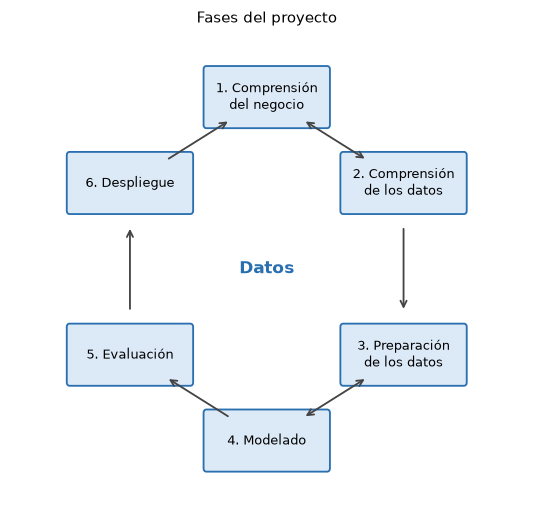

In [2]:
# Fases del proyecto dibujadas con matplotlib (sin librerías extra); la fase de cada sección queda marcada en la tabla de arriba
import numpy as np, matplotlib.pyplot as plt, matplotlib.patches as mp
fases = ['1. Comprensión\ndel negocio', '2. Comprensión\nde los datos', '3. Preparación\nde los datos', '4. Modelado', '5. Evaluación', '6. Despliegue']
ang = np.deg2rad(90 - 60 * np.arange(6)); pos = np.c_[np.cos(ang), np.sin(ang)] * 1.05
fig, ax = plt.subplots(figsize=(6, 5.6)); ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.45, 1.45); ax.axis('off')
for (x, y), t in zip(pos, fases):
    ax.add_patch(mp.FancyBboxPatch((x - .4, y - .17), .8, .34, boxstyle='round,pad=0.02', fc='#dce9f7', ec='#2a6fb0', lw=1.2))
    ax.text(x, y, t, ha='center', va='center', fontsize=8.5)
for i in range(6):
    a, b = pos[i], pos[(i + 1) % 6]
    ida_vuelta = i in (0, 2)                               # negocio <-> datos y preparación <-> modelado se revisan entre sí
    ax.annotate('', xy=b, xytext=a, arrowprops=dict(arrowstyle='<->' if ida_vuelta else '->', color='#444', shrinkA=30, shrinkB=30, lw=1.2))
ax.text(0, 0, 'Datos', ha='center', va='center', fontsize=11, weight='bold', color='#2a6fb0')
ax.set_title('Fases del proyecto', fontsize=10)
fig.savefig('figuras/f0_ciclo_crispdm.png', dpi=200, bbox_inches='tight'); plt.show()

### 0.4 Funciones auxiliares
Se definen aquí para que cada decisión aparezca más adelante, junto a su evidencia. Ninguna lee una constante de decisión: todo llega por parámetros.

| Función | Para qué sirve |
|---|---|
| `buscar_datos`, `agregar_rezagos`, `crear_niveles` | Ubicar los CSV, crear rezagos por fecha (no por posición) y calcular las clases por cuantiles de entrenamiento |
| `construir_malla`, `_params_activos`, `_ausentes`, `preparar_planta2` | Pasar a formato ancho sobre la malla completa de 15 min, estimar lo que aportaría un inversor ausente y armar el dataset de modelado |
| `validar_correccion`, `error_interpolacion` | Medir qué tan bien funciona corregir instantes incompletos o interpolar instantes ausentes |

In [3]:
def buscar_datos(archivo='Plant_2_Weather_Sensor_Data.csv', carpetas=('.', 'Solar_Power', '../../Solar_Power', 'datos_solar')):
    """Devuelve la carpeta donde están los CSV del dataset de Kaggle."""
    for carpeta in carpetas:
        hallados = glob.glob(os.path.join(carpeta, '**', archivo), recursive=True)
        if hallados:
            return os.path.dirname(hallados[0])
    for ruta_zip in glob.glob('*.zip'):
        with zipfile.ZipFile(ruta_zip) as z:
            if any(n.endswith(archivo) for n in z.namelist()):
                z.extractall('datos_solar')
                return buscar_datos(archivo, ('datos_solar',))
    raise FileNotFoundError(f'No se encontró {archivo}. Descarguen el ZIP desde Kaggle y déjenlo en la carpeta del notebook.')

def agregar_rezagos(df, columna, pasos=(1, 2, 4), freq='15min'):
    """Rezagos por fecha (no por posición): si falta el registro anterior queda NaN."""
    serie = df.set_index('DATE_TIME')[columna]
    if not serie.index.is_unique:
        raise ValueError('Hay fechas repetidas: agreguen o eliminen duplicados primero.')
    for p in pasos:
        pasado = serie.shift(p, freq=freq)
        df[f'{columna}_lag{p}'] = df['DATE_TIME'].map(pasado)
    return df

def crear_niveles(train, test, columna, n_niveles=3, etiquetas=None, umbrales=None, nombre='nivel'):
    """Variable objetivo por cuantiles de TRAIN, aplicados igual a test."""
    if umbrales is None:
        cortes = [float(train[columna].quantile(i / n_niveles)) for i in range(1, n_niveles)]
    else:
        cortes = sorted(float(u) for u in umbrales); n_niveles = len(cortes) + 1
    if len(set(cortes)) != len(cortes):
        raise ValueError(f'Cortes repetidos {cortes}.')
    if etiquetas is None:
        etiquetas = {2: ['bajo', 'alto'], 3: ['bajo', 'medio', 'alto']}.get(n_niveles, [f'nivel_{i + 1}' for i in range(n_niveles)])
    limites = [-np.inf] + cortes + [np.inf]
    train, test = train.copy(), test.copy()
    for d_ in (train, test):
        d_[nombre] = pd.cut(d_[columna], bins=limites, labels=etiquetas)
    print('Cortes (calculados con train):', [round(c, 1) for c in cortes])
    print('Proporción por clase en train:', train[nombre].value_counts(normalize=True).round(2).to_dict())
    print('Proporción por clase en test: ', test[nombre].value_counts(normalize=True).round(2).to_dict())
    return train, test, cortes

COLS_SENSOR = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

def construir_malla(gen, sen):
    """Pasa a formato ancho sobre la malla completa de instantes de 15 min (los ausentes quedan vacíos)."""
    ac = gen.pivot(index='DATE_TIME', columns='SOURCE_KEY', values='AC_POWER')
    dc = gen.pivot(index='DATE_TIME', columns='SOURCE_KEY', values='DC_POWER')
    malla = pd.date_range(gen.DATE_TIME.min().normalize(), gen.DATE_TIME.max().normalize() + pd.Timedelta(hours=23, minutes=45),
                          freq='15min', name='DATE_TIME')
    ac, dc = ac.reindex(malla), dc.reindex(malla)
    d = sen.set_index('DATE_TIME')[COLS_SENSOR].reindex(malla)
    d['n_inv'] = ac.notna().sum(axis=1)                 # inversores que reportan
    d['AC_OBS_KW'] = ac.sum(axis=1, min_count=1)        # suma observada
    d['n_inv_cero'] = (ac == 0).sum(axis=1)             # inversores que reportan AC = 0
    return ac, dc, d

def _params_activos(ac_w, cols, idx):
    """Por cada inversor ausente: r (su potencia frente al promedio de los que producen) y p0 (frecuencia de AC = 0 con sol)."""
    pe = ac_w.loc[idx].drop(columns=cols)
    prom_act = pe.where(pe > 0).mean(axis=1)
    r = {c: (ac_w.loc[idx, c].where(ac_w.loc[idx, c] > 0) / prom_act).mean() for c in cols}
    p0 = {c: (ac_w.loc[idx, c] == 0).mean() for c in cols}
    return r, p0

def _ausentes(ac_w, cols, r, p0):
    """Potencia que habrían aportado los inversores `cols` en las filas de ac_w."""
    pres = ac_w.drop(columns=cols)
    prom_act = pres.where(pres > 0).mean(axis=1).fillna(0)
    return sum(r[c] * (1 - p0[c]) * prom_act for c in cols)

def preparar_planta2(gen, sen, umbral, tratar_incompletos, interpolar_ausentes, tratar_planta_en_cero, frac_dias_train, lags):
    """Dataset de modelado de la Planta 2 y un diccionario `ctx` con los objetos intermedios (para la exploración y las pruebas de calidad)."""
    predictores = ['hora'] + [f'AC_PLANTA_KW_lag{p}' for p in lags] + [f'{c}_lag{p}' for c in COLS_SENSOR for p in lags]
    ac, dc, d = construir_malla(gen, sen)
    inv = list(ac.columns); n_tot = len(inv)
    sol = d.IRRADIATION > umbral
    dias = pd.DatetimeIndex(d.index.normalize().unique()).sort_values()
    n_tr = int(frac_dias_train * len(dias))
    dias_tr, dias_te = dias[:n_tr], dias[n_tr:]

    inc = d.index[d.n_inv.between(1, n_tot - 1)]
    falt = ac.loc[inc].isna()
    patron = pd.Series([tuple(c for c in inv if f[c]) for _, f in falt.iterrows()], index=inc, dtype=object)
    d['AC_PLANTA_KW'] = d['AC_OBS_KW']
    params = {}
    if tratar_incompletos == 'corregir':
        base = d.index[(d.n_inv == n_tot) & sol & d.index.normalize().isin(dias_tr)]     # solo días de entrenamiento
        for p in patron.unique():
            cols = list(p)
            params[p] = _params_activos(ac, cols, base)
            idx = patron.index[patron == p]
            d.loc[idx, 'AC_PLANTA_KW'] = d.loc[idx, 'AC_OBS_KW'] + _ausentes(ac.loc[idx], cols, *params[p])
    elif tratar_incompletos == 'excluir':
        d.loc[inc, 'AC_PLANTA_KW'] = np.nan
    elif tratar_incompletos != 'mantener':
        raise ValueError("tratar_incompletos debe ser 'corregir', 'excluir' o 'mantener'")

    d['imputado'] = d.n_inv == 0                              # instantes que no existen en los archivos
    d['n_inv_cero'] = d['n_inv_cero'].where(~d.imputado, 0)
    if interpolar_ausentes:
        ci = COLS_SENSOR + ['AC_PLANTA_KW']
        d.loc[d.imputado, ci] = d[ci].interpolate(method='time', limit=1, limit_area='inside').loc[d.imputado, ci]

    Dp = d.reset_index()
    for col in ['AC_PLANTA_KW'] + COLS_SENSOR:
        Dp = agregar_rezagos(Dp, col, pasos=lags)             # rezagos por fecha, ANTES de filtrar las horas de sol
    Dp = agregar_rezagos(Dp, 'n_inv_cero', pasos=(1,))
    Dp['hora'] = Dp.DATE_TIME.dt.hour + Dp.DATE_TIME.dt.minute / 60
    Dp['fecha'] = Dp.DATE_TIME.dt.normalize()

    x = Dp[~Dp.imputado]
    x = x[x.IRRADIATION > umbral]
    if tratar_planta_en_cero == 'excluir':
        x = x[~((x.n_inv > 0) & (x.n_inv_cero == x.n_inv))]
    elif tratar_planta_en_cero != 'mantener':
        raise ValueError("tratar_planta_en_cero debe ser 'mantener' o 'excluir'")
    ds = x.dropna(subset=['AC_PLANTA_KW'] + predictores)
    ctx = dict(ac=ac, dc=dc, d=d, D=Dp, inv=inv, patron=patron, params=params, umbral=umbral,
               dias=dias, dias_train=dias_tr, dias_test=dias_te)
    return ds, ctx

def validar_correccion(ctx, minimo_kw=1000):
    """Oculta los inversores de cada patrón de ausencia en instantes completos y compara la suma sin corregir y corregida."""
    ac_, d_, inv_ = ctx['ac'], ctx['d'], ctx['inv']
    base = d_.index[(d_.n_inv == len(inv_)) & (d_.IRRADIATION > ctx['umbral']) & d_.index.normalize().isin(ctx['dias_train'])]
    dias_b = pd.DatetimeIndex(base.normalize().unique()).sort_values()
    idx_est, idx_ev = base[base.normalize().isin(dias_b[::2])], base[base.normalize().isin(dias_b[1::2])]
    filas = []
    for p in ctx['patron'].unique():
        cols = list(p)
        r, p0 = _params_activos(ac_, cols, idx_est)
        real = ac_.loc[idx_ev].sum(axis=1)
        pres = ac_.loc[idx_ev].drop(columns=cols).sum(axis=1)
        corr = pres + _ausentes(ac_.loc[idx_ev], cols, r, p0)
        ok = real > minimo_kw
        e0, e1 = ((pres - real) / real)[ok], ((corr - real) / real)[ok]
        filas.append({'inversores ausentes': len(cols), 'sesgo sin corregir %': 100 * e0.mean(),
                      'error abs. sin corregir %': 100 * e0.abs().mean(), 'error abs. corregido %': 100 * e1.abs().mean()})
    return pd.DataFrame(filas).sort_values('inversores ausentes').round(1)

def error_interpolacion(d_, n_inv_total, sol):
    """Error mediano (%) de estimar un instante con el promedio de sus vecinos y % de veces que cambia la clase."""
    vec3 = (d_.n_inv == n_inv_total) & (d_.n_inv.shift(1) == n_inv_total) & (d_.n_inv.shift(-1) == n_inv_total) & sol & ~d_.imputado
    cortes_ = np.quantile(d_.loc[(d_.n_inv == n_inv_total) & sol, 'AC_OBS_KW'], [1 / 3, 2 / 3])
    est = (d_.AC_OBS_KW.shift(1) + d_.AC_OBS_KW.shift(-1)) / 2
    ok = vec3 & (d_.AC_OBS_KW > 1000)
    e = ((est - d_.AC_OBS_KW) / d_.AC_OBS_KW)[ok]
    cambia = (np.digitize(est[vec3], cortes_) != np.digitize(d_.loc[vec3, 'AC_OBS_KW'], cortes_)).mean()
    return 100 * e.abs().median(), 100 * cambia

print('Funciones definidas.')

Funciones definidas.


Criterio de la fase 0. El cuaderno ejecuta hasta aquí y no hay ninguna constante de decisión: solo `SEMILLA`. Las decisiones llegan en las fases 3 a 5, cada una después de su evidencia.

<a id="fase1"></a>
# Fase 1: Comprensión del negocio
Esta fase fija qué se quiere lograr desde el punto de vista del negocio antes de mirar un solo dato: quién usa el resultado, qué problema resuelve, cómo se sabrá que funcionó y qué riesgos hay. No hay modelado aquí; el único código es un gráfico de contexto del sector (1.1.2).

## 1.1 Determinar los objetivos del negocio

### 1.1.1 Organización y partes interesadas
La organización es una empresa de operación y mantenimiento (O&M) que ofrecerá monitoreo y mantenimiento a plantas solares fotovoltaicas en Colombia. El resultado del proyecto es una herramienta de pronóstico de corto plazo y alertas. Cada parte afectada necesita algo distinto:

| Parte interesada | Qué necesita de la herramienta |
|---|---|
| Gerente de O&M | Programar cuadrillas en las horas en que intervenir cuesta menos energía |
| Técnicos de campo | Saber cuándo intervenir y qué revisar cuando la planta rinde menos de lo esperado |
| Dueño de la planta | Perder menos energía por mantenimientos mal programados y enterarse pronto de las fallas |
| Operador de red | Una generación más predecible a corto plazo |

### 1.1.2 Contexto del sector
Colombia cuenta con un marco legal que promueve las fuentes no convencionales de energía. La Ley 1715 de 2014 regula la integración de las energías renovables no convencionales al sistema energético nacional y busca promover su desarrollo y uso, incluida su participación en el mercado eléctrico y en las zonas no interconectadas [2]. La Ley 2099 de 2021 moderniza esa legislación y dicta disposiciones para la transición energética y la dinamización del mercado energético con fuentes no convencionales [3]. El gráfico siguiente muestra la capacidad solar del Sistema Interconectado Nacional según la serie de XM/SIMEM [4].

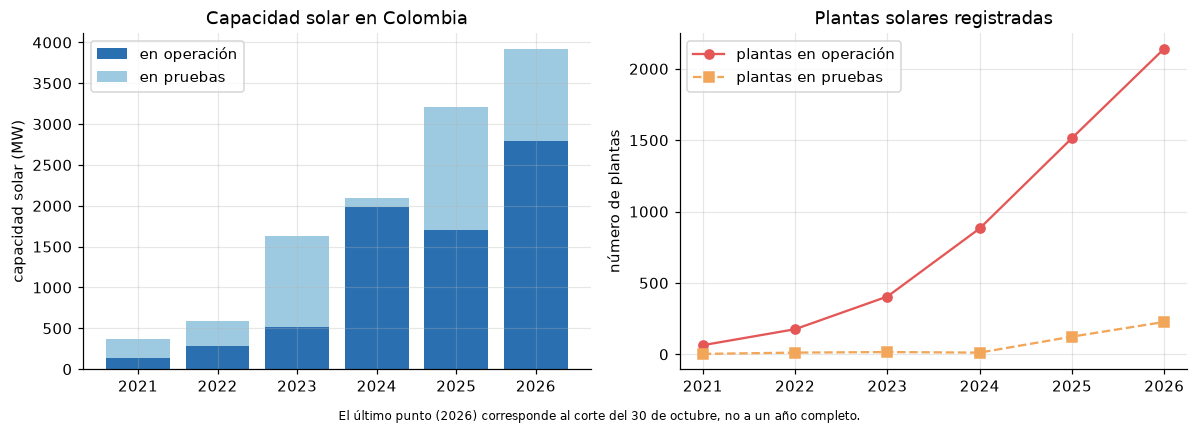

,operación (MW),plantas en operación,pruebas (MW),plantas en pruebas,participación en operación (%)
fecha,,,,,
31-12-2021,137.7,64,226.9,3,0.8
31-12-2022,289.6,176,296.0,12,1.5
31-12-2023,513.1,405,1120.8,16,2.6
31-12-2024,1984.2,882,115.2,12,9.2
31-12-2025,1699.1,1515,1508.4,124,8.0
30-10-2026,2795.2,2142,1120.7,227,12.4


In [4]:
# Capacidad solar en Colombia (serie anual de SIMEM, archivo Otros_Datos/capacidad_solar_simem*.csv)
ruta_simem = next(iter(glob.glob('../../Otros_Datos/capacidad_solar_simem*.csv') + glob.glob('Otros_Datos/capacidad_solar_simem*.csv')), None)
simem = pd.read_csv(ruta_simem, parse_dates=['fecha']).set_index('fecha')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
anios = simem.index.year.astype(str)
ax[0].bar(anios, simem.solar_operacion_MW, color='#2a6fb0', label='en operación')
ax[0].bar(anios, simem.solar_pruebas_MW, bottom=simem.solar_operacion_MW, color='#9ecae1', label='en pruebas')
ax[0].set_ylabel('capacidad solar (MW)'); ax[0].set_title('Capacidad solar en Colombia'); ax[0].legend()
ax[1].plot(anios, simem.plantas_solar_operacion, 'o-', color='#e45756', label='plantas en operación')
ax[1].plot(anios, simem.plantas_solar_pruebas, 's--', color='#f2a65a', label='plantas en pruebas')
ax[1].set_ylabel('número de plantas'); ax[1].set_title('Plantas solares registradas'); ax[1].legend()
fig.text(0.5, -0.02, 'El último punto (2026) corresponde al corte del 30 de octubre, no a un año completo.', ha='center', fontsize=8)
fig.tight_layout(); fig.savefig('figuras/f1_capacidad_solar_colombia.png', dpi=200, bbox_inches='tight'); plt.show()
resumen_simem = simem[['solar_operacion_MW', 'plantas_solar_operacion', 'solar_pruebas_MW', 'plantas_solar_pruebas', 'participacion_solar_operacion_pct']].round(1)
resumen_simem.index = resumen_simem.index.strftime('%d-%m-%Y')
display(resumen_simem.rename(columns={'solar_operacion_MW': 'operación (MW)', 'plantas_solar_operacion': 'plantas en operación', 'solar_pruebas_MW': 'pruebas (MW)',
                                      'plantas_solar_pruebas': 'plantas en pruebas', 'participacion_solar_operacion_pct': 'participación en operación (%)'}))

El número de plantas solares registradas y la capacidad en operación crecen de forma marcada entre 2021 y 2026; la participación de la solar en la capacidad en operación pasa de ser casi nula a una fracción visible. La serie de capacidad en operación no es monótona (entre 2024 y 2025 baja aunque el número de plantas sigue subiendo, probablemente por plantas que pasan entre "pruebas" y "operación" o por cambios de registro; el archivo no lo explica y no se afirma aquí). Con muchas plantas pequeñas y medianas entrando al sistema, crece la necesidad de monitoreo y mantenimiento especializado, que es el nicho de la empresa de O&M.

### 1.1.3 Área problemática y solución actual
Hoy el mantenimiento se programa en horarios fijos (madrugada o atardecer) o con la regla "lo que pasa ahora se repite" (persistencia). Tampoco hay una alerta automática cuando la planta rinde menos de lo esperado.

| | Ventajas | Desventajas |
|---|---|---|
| Horario fijo | Sencillo, sin datos ni modelo | No distingue días nublados de despejados; puede intervenir con producción alta |
| Persistencia (el nivel de hace 15 min se repite) | Muy barata y difícil de superar a 15 min | No anticipa cambios; no avisa cuando la planta rinde menos de lo esperado |
| Sin alertas de desvío | Cero costo | Las fallas se detectan tarde (reportes del dueño o facturación) |

### 1.1.4 Objetivos del negocio
1. Programar mantenimientos en ventanas de baja generación anunciadas con 15 minutos de anticipación, para perder la menor energía posible al intervenir.
2. Detectar desvíos. Si el modelo pronostica alto (o medio) y la planta genera bajo, el técnico revisa las causas probables: el MPPT del inversor, la suciedad de los paneles [5][6], las sombras parciales [7], strings desconectados o con desajuste [8], y robo o vandalismo.

### 1.1.5 Por qué datos de India para una empresa en Colombia
El conjunto público de Kaggle (Planta 2) [9] permite construir y probar la base de la herramienta: las variables de monitoreo (irradiancia, potencia AC/DC por inversor, temperatura ambiente y del módulo) y la frecuencia de 15 minutos son las mismas que entrega cualquier SCADA o datalogger. Cuando la empresa tenga plantas en Colombia, la herramienta se reentrena con datos locales (los cortes de las clases se recalculan por planta). Limitación: el clima y la estacionalidad de India y de Colombia son distintos, así que las cifras de este cuaderno miden el método, no el desempeño que tendría en una planta colombiana.

### 1.1.6 Criterios de éxito del negocio

| Objetivo | Criterio medible | Dónde se mide |
|---|---|---|
| Programar mantenimientos en ventanas bajas | Precisión de bajo mayor o igual a la de la persistencia, con un recall de bajo suficiente para aprovechar las ventanas (el mínimo se fija en 4.2.4) | 5.1.2 y 5.1.7 |
| Conocer el costo de equivocarse | Energía generada durante los falsos bajo, en MWh y en COP | 5.1.4 |
| Detectar desvíos | Alertas con hora y causa probable que un técnico pueda revisar | 6.3.2 |
| Poder repetirlo con datos nuevos | El flujo se ejecuta completo cambiando solo las decisiones documentadas | 6.6 |

## 1.2 Evaluar la situación

### 1.2.1 Inventario de recursos
- Datos: cuatro CSV de Kaggle (generación y sensor de las plantas 1 y 2). Se usa la Planta 2: generación por inversor (22 inversores) y el sensor de la planta, cada 15 minutos. La Planta 1 solo se usa para comparar un fenómeno (2.4.7). También se usa la serie de capacidad solar de SIMEM para el contexto.
- Hardware: computadores portátiles personales (el cuaderno completo corre en unos minutos en un equipo de escritorio).
- Software: Python con las librerías listadas en 0.3 (`pandas`, `numpy`, `matplotlib`, `seaborn`, `missingno`, `statsmodels`, `scipy`, `scikit-learn`, `xgboost`).
- Personas: tres integrantes que se reparten el análisis, el informe y la presentación.

### 1.2.2 Requisitos, supuestos y restricciones
- Alcance de los datos: un mes (15 de mayo a 17 de junio de 2020), una planta, registros cada 15 minutos.
- Lo que no hay: registros de mantenimientos ni de fallas reales; no se puede validar una alerta contra un evento verificado.
- Supuestos del equipo: el precio de la energía (`PRECIO_COP_KWH`, 5.1.4), la parte de la planta que se desconecta en un mantenimiento y los umbrales de selección (4.2.4).
- Restricciones: entrega el 24 de noviembre de 2026 y sustentación el 25.

### 1.2.3 Riesgos y contingencias

| Riesgo | Plan de contingencia |
|---|---|
| Pocos días de prueba (7 en la partición principal) | Evaluación día a día (walk-forward) con intervalos por bootstrap de días (5.1.2) |
| Faltantes que no son al azar | Corregir la suma con el aporte estimado de los inversores ausentes y validar la corrección (3.2.1) |
| El modelo apenas mejora a la persistencia | Reportarlo con sus intervalos y no vender más de lo que muestran los datos |
| Fuga de información | Controles explícitos y una prueba que hace trampa a propósito (5.3.2) |
| Sesgo de selección al elegir entre miles de combinaciones | Selección anidada y verificación del sesgo [10] (4.4.5) |
| Entregar tarde | Fases en orden; el cuaderno queda ejecutable al cierre de cada punto de control |

### 1.2.4 Glosario
- Irradiancia (`IRRADIATION`): potencia solar que llega por metro cuadrado (kW/m²).
- Potencia AC / DC: potencia que entrega un inversor en corriente alterna / la que recibe de los paneles en continua.
- Inversor: equipo que convierte la corriente continua de los paneles en alterna. La Planta 2 tiene 22.
- MPPT: seguimiento del punto de máxima potencia; el inversor ajusta su voltaje para extraer lo máximo de los paneles.
- String: serie de módulos conectados que alimenta una entrada del inversor.
- Clipping: recorte de potencia cuando los paneles producen más de lo que el inversor puede convertir [11].
- Persistencia: pronosticar que el nivel de dentro de 15 min será el mismo de ahora.
- Climatología: pronosticar con la potencia típica (mediana) de esa hora en los días de entrenamiento.
- Rezago: valor de una variable en un instante anterior (por ejemplo, hace 15 min).
- Tercil: cada uno de los dos cortes que dividen los datos en tres grupos del mismo tamaño (bajo, medio, alto).
- F1 macro: promedio del F1 de las tres clases. kappa: acierto descontando el azar.
- Precisión de bajo: de las veces que el modelo dijo bajo, cuántas era bajo. Recall de bajo: de las ventanas realmente bajas, cuántas detectó.
- Walk-forward: evaluación día a día, reentrenando con el pasado antes de predecir cada día.
- Ensamble: varios modelos cuyas probabilidades se promedian. Deriva: cambio con el tiempo en la distribución de los datos que deteriora el modelo.

### 1.2.5 Costo y beneficio
- Costos: horas del equipo durante el semestre y, en un despliegue real, la nube (ingesta, almacenamiento, inferencia y tablero; ver 6.2).
- Beneficios: MWh que no se pierden por intervenir en una hora de producción y fallas detectadas antes. El cálculo de energía y pesos de los falsos bajo está en 5.1.4; el costo de nube de un despliegue real no se estima aquí porque depende de la cantidad de plantas.

## 1.3 Determinar los objetivos de la minería de datos

### 1.3.1 Tipo de problema
Dos tareas: (1) clasificación multiclase del nivel de la planta (bajo, medio, alto) 15 minutos adelante, y (2) agrupamiento de los días con K-Means. Se clasifica por niveles y no se hace regresión en kW porque la decisión del técnico es por nivel (intervenir o no), no por un valor exacto; la literatura de pronóstico fotovoltaico también plantea el problema como clasificación por niveles [12].

### 1.3.2 Formulación matemática
Sea $P^{AC}_{i,t}$ la potencia AC del inversor $i$ en el instante $t$ (cada 15 min). La potencia de la planta es
$$P_t=\sum_{i=1}^{22}P^{AC}_{i,t}.$$
Variable objetivo. El nivel del instante siguiente, $y_{t+1}\in\{\text{bajo},\text{medio},\text{alto}\}$, definido por los terciles $q_{1/3}$ y $q_{2/3}$ de $P$ calculados solo con los días de entrenamiento:
$$y_{t+1}=\begin{cases}\text{bajo}& P_{t+1}\le q_{1/3}\\ \text{medio}& q_{1/3}<P_{t+1}\le q_{2/3}\\ \text{alto}& P_{t+1}>q_{2/3}\end{cases}$$
Predictores (todo lo que se conoce en $t$):
$$x_t=\big(h_t,\;P_{t-1},P_{t-2},P_{t-4},\;G_{t-k},\;T^{amb}_{t-k},\;T^{mod}_{t-k}\big),\quad k\in\{1,2,4\},$$
con $h_t$ la hora del día (o una transformación suya), $G$ la irradiancia y $T$ las temperaturas. Ensamble de $M$ modelos con pesos iguales:
$$\hat p_c(x)=\frac1M\sum_{m=1}^{M}\hat p^{(m)}_c(x),\qquad \hat y=\arg\max_{c}\hat p_c(x).$$
Métricas. Con $TP_c$, $FP_c$, $FN_c$ por clase: $\;F1_c=\dfrac{2TP_c}{2TP_c+FP_c+FN_c}$, $\;F1_{macro}=\tfrac13\sum_c F1_c$, $\;\kappa=\dfrac{p_o-p_e}{1-p_e}$ (con $p_o$ la exactitud y $p_e$ la exactitud esperada por azar), $\;\text{precisión}_{bajo}=\dfrac{TP_{bajo}}{TP_{bajo}+FP_{bajo}}$, $\;\text{recall}_{bajo}=\dfrac{TP_{bajo}}{TP_{bajo}+FN_{bajo}}$. Costo de un falso bajo: $\sum P_{t+1}\,\Delta t$ sobre los instantes en que se anunció bajo y el nivel real era medio o alto ($\Delta t=0{,}25$ h).

Por qué es un problema complejo de ingeniería. (i) Hay dependencia temporal: filas seguidas son casi copias, así que partir al azar infla los resultados. (ii) Las clases salen de cuantiles, no de un valor físico. (iii) Los faltantes no son aleatorios (un bloque de inversores falla durante días). (iv) Hay pocos días de datos. (v) El costo es asimétrico: un falso bajo hace intervenir con la planta produciendo.

### 1.3.3 Criterios de éxito de la minería de datos
1. El modelo final supera a la persistencia y a la climatología (y a su combinación) en F1 macro y kappa, con un intervalo de 95 % por bootstrap de días que excluya 0.
2. La precisión de bajo es mayor o igual a la de la persistencia.
3. La prueba de fuga de información (5.3.2) no produce un resultado casi perfecto: si el modelo copia la respuesta, no hay modelo.

## 1.4 Ética e impactos

### 1.4.1 Dilemas éticos
| Dilema | Principio | Decisión del proyecto | Medida |
|---|---|---|---|
| Privacidad | Proteger datos personales | Los datos son de equipos (inversores, sensor), no de personas; no hay datos personales | Ninguna columna identifica a una persona |
| Uso responsable | No causar daño evitable | Un falso bajo hace intervenir con producción; un falso alto oculta fallas | Se reporta la energía de los falsos bajo y se ofrece un umbral opcional que sube la precisión de bajo |
| Transparencia | Honestidad y rendición de cuentas | El modelo apenas mejora a la persistencia en algunas métricas | Se reportan todos los modelos probados, los resultados modestos y los intervalos |
| Sesgo de generalización | Equidad y alcance del resultado | Una planta, un mes y otro país | Se dice que las cifras miden el método y se reentrena con datos colombianos |
| Seguridad del técnico | Seguridad de las personas | Una alerta equivocada puede mandar a intervenir equipos energizados | La alerta es una recomendación; la intervención sigue los protocolos de la empresa |

### 1.4.2 Matriz de impactos

| Dimensión | Impacto positivo | Riesgo | Mitigación |
|---|---|---|---|
| Social | Empleos técnicos mejor organizados; menos riesgo al programar intervenciones | Confiar de más en el modelo y descuidar la inspección | El modelo recomienda; el técnico decide y la alerta lleva hora y causa probable |
| Económico | Menos energía perdida al intervenir; fallas detectadas antes | Un precio supuesto de energía puede sobrestimar el ahorro | El precio es un supuesto declarado (`PRECIO_COP_KWH`) y se reporta también la energía en MWh |
| Ambiental | Más energía solar aprovechada y menos fallas sin detectar | Cómputo en la nube con huella de carbono | Un solo modelo liviano; reentrenar cada mes y no a diario |
| Global | Método replicable en otros países con SCADA estándar | Extrapolar cifras de un clima a otro | Reentrenar y recalcular los cortes con datos de cada planta |

## 1.5 Plan del proyecto
Las duraciones son una estimación de planeación para el calendario del curso; el grupo las ajusta con sus fechas reales.

| Fase | Duración estimada | Recursos | Riesgos principales |
|---|---|---|---|
| 1. Comprensión del negocio | 1 día | Equipo, bibliografía | Objetivos vagos |
| 2. Comprensión de los datos | 2 días | CSV de Kaggle, `missingno` | Descubrir tarde faltantes no aleatorios |
| 3. Preparación | 3 días | `pandas`, validación de cada decisión | Decidir sin evidencia o con fuga |
| 4. Modelado | 3 días | `scikit-learn`, `xgboost`, 20 núcleos de CPU | Tiempo de cómputo; sesgo de selección |
| 5. Evaluación | 2 días | Walk-forward, bootstrap | Pocos días de prueba |
| 6. Despliegue y entrega | 2 días | Informe IEEE, diapositivas, simulación local | Plazo |

Puntos de decisión e iteraciones. Tras la fase 4, los resultados modestos de los modelos sueltos llevaron a volver a modelar (ensamble, línea base más exigente) y a revisar la evaluación; tras la fase 5, la sensibilidad a las decisiones de limpieza confirma o revisa la fase 3 (ver 5.3.3).

## 1.6 Cierre de la fase

| Elemento | Resultado | Dónde se ve |
|---|---|---|
| Objetivos del negocio y usuarios | Programar mantenimientos y detectar desvíos para una empresa de O&M en Colombia | 1.1.1, 1.1.4 |
| Criterios de éxito medibles | De negocio y de minería de datos | 1.1.6, 1.3.3 |
| Recursos, supuestos y riesgos | Identificados, con plan de contingencia | 1.2 |
| Problema de minería de datos | Clasificación multiclase a 15 min y agrupamiento de días, formulados matemáticamente | 1.3.1, 1.3.2 |
| Ética e impactos | Dilemas y matriz de impactos con mitigación | 1.4 |

Con esto queda definido qué se necesita; sigue la exploración de los datos.

<a id="fase2"></a>
# Fase 2: Comprensión de los datos
Esta fase describe y diagnostica; no se define ninguna constante de decisión. Para poder graficar se usa una vista provisional sin decisiones: la malla completa de instantes de 15 min con la suma observada de los inversores (`AC_OBS_KW`, sin corregir) y todas las horas. Las decisiones de limpieza se toman en la fase 3, cada una apoyada en lo que se vea aquí.

## 2.1 Recopilar los datos
### 2.1.1 Carga
Se cargan los dos archivos de la Planta 2: la generación de cada inversor y el sensor de la planta. La fecha llega como texto; se convierte con formato explícito y se cuentan las fechas inválidas.

In [5]:
ruta = buscar_datos()
FMT = '%Y-%m-%d %H:%M:%S'
# La fecha llega como texto: se convierte con formato explícito y se cuentan las fechas inválidas
for archivo in ['Plant_2_Generation_Data.csv', 'Plant_2_Weather_Sensor_Data.csv']:
    txt = pd.read_csv(os.path.join(ruta, archivo), usecols=['DATE_TIME'], dtype=str)['DATE_TIME']
    invalidas = int(pd.to_datetime(txt, format=FMT, errors='coerce').isna().sum())
    print(f'{archivo}: tipo antes de convertir = {txt.dtype} | fechas inválidas con format={FMT!r}: {invalidas}')
gen = pd.read_csv(os.path.join(ruta, 'Plant_2_Generation_Data.csv'), parse_dates=['DATE_TIME'], date_format=FMT)
sen = pd.read_csv(os.path.join(ruta, 'Plant_2_Weather_Sensor_Data.csv'), parse_dates=['DATE_TIME'], date_format=FMT)
print('Datos en:', ruta)
print('Tipo después de convertir:', gen.DATE_TIME.dtype, '|', sen.DATE_TIME.dtype)

Plant_2_Generation_Data.csv: tipo antes de convertir = str | fechas inválidas con format='%Y-%m-%d %H:%M:%S': 0
Plant_2_Weather_Sensor_Data.csv: tipo antes de convertir = str | fechas inválidas con format='%Y-%m-%d %H:%M:%S': 0
Datos en: ../../Solar_Power\Data
Tipo después de convertir: datetime64[us] | datetime64[us]


### 2.1.2 Informe de recopilación
- Origen: conjunto público de Kaggle [9]. La Planta 2 es la planta que se estudia.
- Atributos prometedores: `AC_POWER` por inversor (la potencia que define el nivel), `IRRADIATION` (el sol que llega) y las temperaturas ambiente y del módulo [13].
- Atributos que se excluirán por contener la respuesta: `DC_POWER` del mismo instante (sale de la misma corriente que la potencia AC), `DAILY_YIELD` y `TOTAL_YIELD` (energías acumuladas con la misma potencia). La razón completa y la prueba que lo demuestra están en 3.1.3 y 5.3.2.
- Claves de unión: `DATE_TIME` (entre generación y sensor) y `SOURCE_KEY` (cada inversor). `PLANT_ID` es constante en cada archivo.

## 2.2 Describir los datos

In [6]:
unidades = {'DC_POWER': 'kW', 'AC_POWER': 'kW', 'DAILY_YIELD': 'kWh', 'TOTAL_YIELD': 'kWh', 'AMBIENT_TEMPERATURE': '°C',
            'MODULE_TEMPERATURE': '°C', 'IRRADIATION': 'kW/m²', 'DATE_TIME': 'fecha-hora', 'PLANT_ID': 'id', 'SOURCE_KEY': 'id'}
def resumen_archivo(df, nombre):
    t = pd.Series(sorted(df.DATE_TIME.unique())); frec = t.diff().dropna().value_counts()
    return {'archivo': nombre, 'filas': len(df), 'columnas': df.shape[1], 'desde': df.DATE_TIME.min(), 'hasta': df.DATE_TIME.max(),
            'intervalo más frecuente': str(frec.index[0]).replace('0 days ', ''), 'veces': int(frec.iloc[0]), 'otros intervalos': int(frec.iloc[1:].sum()),
            'fuentes (SOURCE_KEY)': df.SOURCE_KEY.nunique(), 'celdas vacías': int(df.isna().sum().sum())}
display(pd.DataFrame([resumen_archivo(gen, 'generación'), resumen_archivo(sen, 'sensor')]).set_index('archivo').T)
tipos = pd.DataFrame({'tipo (generación)': gen.dtypes.astype(str)}).join(pd.DataFrame({'tipo (sensor)': sen.dtypes.astype(str)}), how='outer')
tipos['unidad'] = [unidades.get(i, '') for i in tipos.index]; display(tipos)

archivo,generación,sensor
filas,67698,3259
columnas,7,6
desde,2020-05-15 00:00:00,2020-05-15 00:00:00
hasta,2020-06-17 23:45:00,2020-06-17 23:45:00
intervalo más frecuente,00:15:00,00:15:00
veces,3253,3253
otros intervalos,5,5
fuentes (SOURCE_KEY),22,1
celdas vacías,0,0


,tipo (generación),tipo (sensor),unidad
AC_POWER,float64,NaN,kW
AMBIENT_TEMPERATURE,NaN,float64,°C
DAILY_YIELD,float64,NaN,kWh
DATE_TIME,datetime64[us],datetime64[us],fecha-hora
DC_POWER,float64,NaN,kW
IRRADIATION,NaN,float64,kW/m²
MODULE_TEMPERATURE,NaN,float64,°C
PLANT_ID,int64,int64,id
SOURCE_KEY,str,str,id
TOTAL_YIELD,float64,NaN,kWh


In [7]:
print('Generación (por inversor y por instante):'); display(gen[['DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']].describe().round(2))
print('Sensor (de toda la planta):'); display(sen[COLS_SENSOR].describe().round(3))

Generación (por inversor y por instante):


,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
count,67698.00,67698.00,67698.00,6.769800e+04
mean,246.70,241.28,3294.89,6.589448e+08
std,370.57,362.11,2919.45,7.296678e+08
min,0.00,0.00,0.00,0.000000e+00
25%,0.00,0.00,272.75,1.996494e+07
50%,0.00,0.00,2911.00,2.826276e+08
75%,446.59,438.22,5534.00,1.348495e+09
max,1420.93,1385.42,9873.00,2.247916e+09


Sensor (de toda la planta):


,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,3259.000,3259.000,3259.000
mean,28.069,32.772,0.233
std,4.062,11.344,0.313
min,20.942,20.265,0.000
25%,24.602,23.717,0.000
50%,26.981,27.535,0.019
75%,31.057,40.481,0.439
max,39.182,66.636,1.099


### 2.2.1 Informe de descripción
Hay dos archivos planos CSV con coma como delimitador. El de generación tiene un registro por inversor por instante (22 inversores, cada 15 minutos, 34 días); el del sensor tiene un registro por instante para toda la planta. Las fechas se leen sin errores con formato explícito. Los valores de potencia están en kW y las energías acumuladas en kWh. No hay celdas vacías en los archivos: los faltantes son registros que no existen (instantes o inversores ausentes), no celdas en blanco, y se detectan al armar la malla completa de instantes (2.4). Para el negocio: la potencia AC es la variable que se quiere anticipar y la irradiancia es la que más la explica (se ve en 2.3.2).

## 2.3 Explorar los datos
Antes de graficar se arma la vista provisional: una fila por cada instante posible de 15 min (malla completa), con la suma de lo que reportan los inversores. `IRR_EXPLORACION` solo define qué se dibuja como "hay sol" en los gráficos de esta fase; no es la decisión de limpieza, que se toma en 3.1.1 con la evidencia de 2.4.11.

In [8]:
ac, dc, d = construir_malla(gen, sen)                   # malla completa de instantes (los ausentes quedan vacíos)
N_INV = ac.shape[1]
IRR_EXPLORACION = 0.1                                   # kW/m²: solo para dibujar "con sol" en esta fase; no es una decisión de limpieza
sol_x = d.IRRADIATION > IRR_EXPLORACION
comp = d.n_inv == N_INV                                 # instantes con los 22 inversores
todos_cero_x = sol_x & (d.n_inv > 0) & (d.n_inv_cero == d.n_inv)
hora_dia = d.index.hour + d.index.minute / 60
print(f'Malla: {len(d)} instantes ({d.index.normalize().nunique()} días por 96) | inversores: {N_INV} | con los 22 inversores: {int(comp.sum())} | sin ningún inversor: {int((d.n_inv == 0).sum())}')

Malla: 3264 instantes (34 días por 96) | inversores: 22 | con los 22 inversores: 2355 | sin ningún inversor: 5


### 2.3.1 Energía diaria y distribución de la potencia

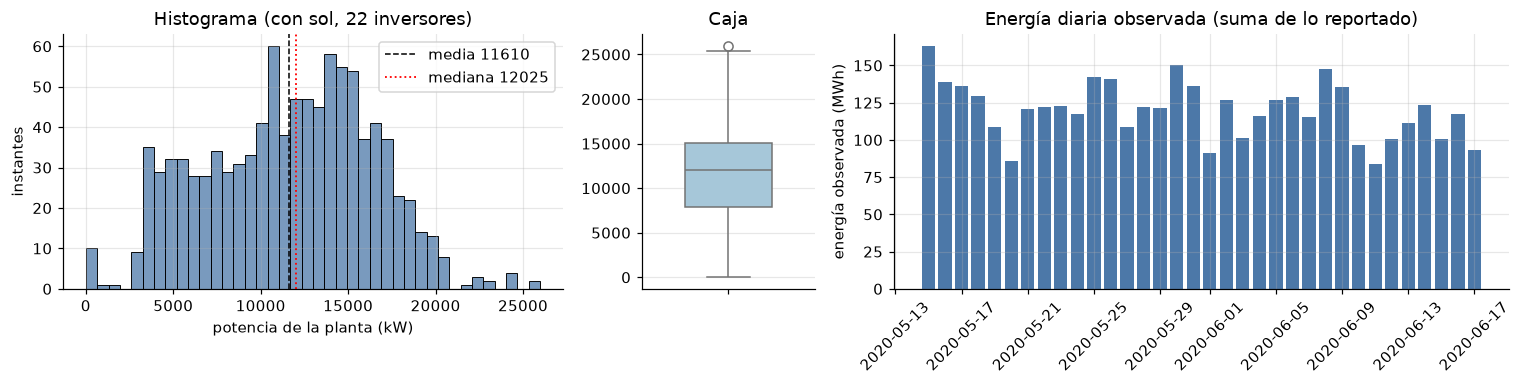

,potencia con sol (kW),energía diaria (MWh),irradiación diaria (kWh/m²),rendimiento diario (MWh por kWh/m²)
count,984.00,34.00,34.00,34.00
mean,11610.37,120.10,5.58,22.34
std,4761.74,18.99,1.28,4.39
min,0.00,83.96,2.82,12.87
25%,7936.73,108.51,4.86,20.05
50%,12024.91,121.60,5.86,22.16
75%,15109.56,134.05,6.74,24.37
max,25979.76,162.86,7.14,31.19


,menor energía,menor rendimiento
0,11-06,20-05
1,20-05,27-05
2,01-06,22-05
3,17-06,24-05
4,10-06,28-05


In [9]:
dia_g = gen.DATE_TIME.dt.normalize(); dia_s = sen.DATE_TIME.dt.normalize()
e_dia_raw = gen.groupby(dia_g).AC_POWER.sum() * 0.25 / 1000        # MWh de lo observado (los inversores ausentes no suman)
h_dia_raw = sen.groupby(dia_s).IRRADIATION.sum() * 0.25            # kWh/m²
pot_sol = d.AC_OBS_KW[comp & sol_x]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={'width_ratios': [1.3, .45, 1.6]})
sns.histplot(pot_sol, bins=40, color='#4c78a8', ax=ax[0]); ax[0].axvline(pot_sol.mean(), color='k', ls='--', lw=1, label=f'media {pot_sol.mean():.0f}')
ax[0].axvline(pot_sol.median(), color='r', ls=':', lw=1.2, label=f'mediana {pot_sol.median():.0f}'); ax[0].legend()
ax[0].set_xlabel('potencia de la planta (kW)'); ax[0].set_ylabel('instantes'); ax[0].set_title('Histograma (con sol, 22 inversores)')
sns.boxplot(y=pot_sol, ax=ax[1], color='#9ecae1', width=.5); ax[1].set_ylabel(''); ax[1].set_title('Caja')
ax[2].bar(e_dia_raw.index, e_dia_raw, color='#4c78a8'); ax[2].set_ylabel('energía observada (MWh)'); ax[2].tick_params(axis='x', rotation=45)
ax[2].set_title('Energía diaria observada (suma de lo reportado)')
fig.tight_layout(); fig.savefig('figuras/f2_energia_diaria.png', dpi=200, bbox_inches='tight'); plt.show()
rend_raw = e_dia_raw / h_dia_raw
display(pd.DataFrame({'potencia con sol (kW)': pot_sol.describe(), 'energía diaria (MWh)': e_dia_raw.describe(), 'irradiación diaria (kWh/m²)': h_dia_raw.describe(),
                      'rendimiento diario (MWh por kWh/m²)': rend_raw.describe()}).round(2))
display(pd.DataFrame({'menor energía': [x.strftime('%d-%m') for x in e_dia_raw.nsmallest(5).index], 'menor rendimiento': [x.strftime('%d-%m') for x in rend_raw.nsmallest(5).index]}))

La energía varía mucho de un día a otro: hay días buenos y días malos. Los días de menor energía y los de menor rendimiento (energía por unidad de irradiación) no coinciden del todo: unos son nublados y otros tienen pérdidas con buen sol (por ejemplo, inversores desconectados). Hipótesis 1: el nivel de la planta depende del clima del día y de las pérdidas operativas. Hipótesis 2: la distribución de la potencia sin cola larga permite clasificar por terciles sin clases extremas.

### 2.3.2 Potencia frente a irradiancia

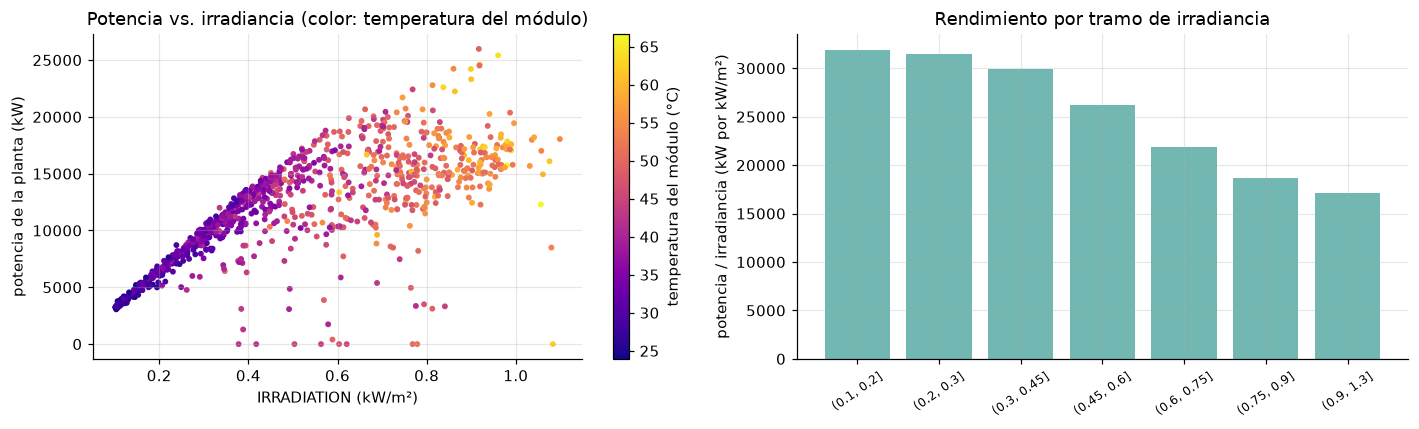

,instantes,kW por kW/m²,temp. módulo media (°C)
IRRADIATION,,,
"(0.1, 0.2]",145.0,31921.8,30.4
"(0.2, 0.3]",122.0,31431.6,34.3
"(0.3, 0.45]",225.0,29871.7,37.2
"(0.45, 0.6]",149.0,26218.0,42.6
"(0.6, 0.75]",131.0,21831.8,48.1
"(0.75, 0.9]",136.0,18704.0,51.6
"(0.9, 1.3]",76.0,17117.0,55.6


In [10]:
base_ir = d[comp & sol_x]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sc = ax[0].scatter(base_ir.IRRADIATION, base_ir.AC_OBS_KW, c=base_ir.MODULE_TEMPERATURE, s=8, cmap='plasma')
ax[0].set_xlabel('IRRADIATION (kW/m²)'); ax[0].set_ylabel('potencia de la planta (kW)'); ax[0].set_title('Potencia vs. irradiancia (color: temperatura del módulo)')
fig.colorbar(sc, ax=ax[0], label='temperatura del módulo (°C)')
tramos = pd.cut(base_ir.IRRADIATION, [0.1, .2, .3, .45, .6, .75, .9, 1.3])
rend_tr = base_ir.groupby(tramos, observed=True).apply(lambda g: pd.Series({'instantes': len(g), 'kW por kW/m²': g.AC_OBS_KW.sum() / g.IRRADIATION.sum(),
                                                                          'temp. módulo media (°C)': g.MODULE_TEMPERATURE.mean()}), include_groups=False)
ax[1].bar(range(len(rend_tr)), rend_tr['kW por kW/m²'], color='#72b7b2'); ax[1].set_xticks(range(len(rend_tr)))
ax[1].set_xticklabels([str(i) for i in rend_tr.index], rotation=35, fontsize=8)
ax[1].set_ylabel('potencia / irradiancia (kW por kW/m²)'); ax[1].set_title('Rendimiento por tramo de irradiancia')
fig.tight_layout(); fig.savefig('figuras/f2_potencia_irradiancia.png', dpi=200, bbox_inches='tight'); plt.show()
display(rend_tr.round(1))
caida_exp = 100 * (1 - rend_tr['kW por kW/m²'].iloc[-1] / rend_tr['kW por kW/m²'].iloc[0])

La relación entre irradiancia y potencia es casi lineal, pero el rendimiento por unidad de irradiancia baja cuando la irradiancia y la temperatura del módulo suben. Eso es coherente con dos efectos: la potencia de un módulo cae al calentarse [13] y los inversores recortan potencia cuando los paneles producen más de lo que pueden convertir (clipping, la meseta de la nube de puntos) [11]. Con estos datos no se puede repartir cuánto de la caída es de cada causa (también influyen la suciedad y los inversores en cero); basta saber que la relación no es perfectamente lineal. Hipótesis 3: la irradiancia reciente informa el nivel, pero no es el único factor.

### 2.3.3 Día típico y cambio entre días

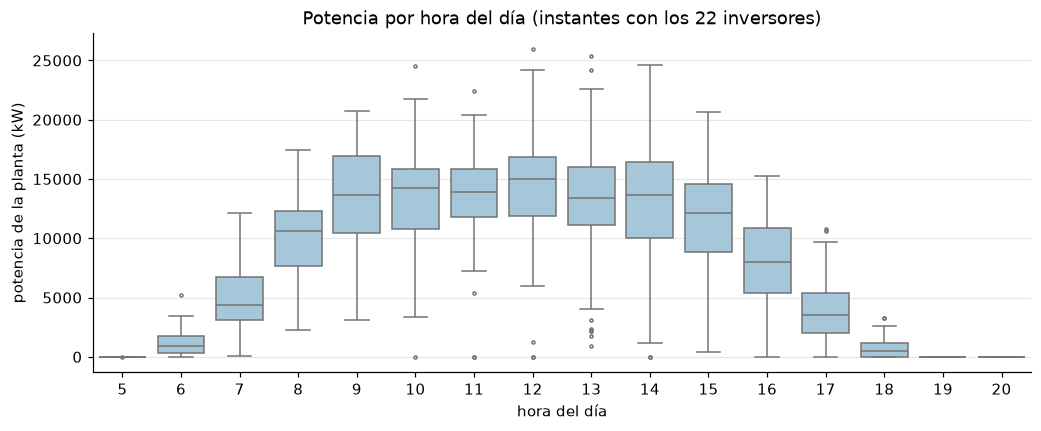

hora_int,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
mediana (kW),0,912,4331,10589,13630,14242,13931,15042,13358,13686,12121,7980,3551,473,0,0
P10 (kW),0,85,2126,5037,7578,7967,8615,9939,6173,5411,5720,2902,702,0,0,0
P90 (kW),0,2593,8406,15271,19383,17883,17330,18064,18307,18123,17582,13209,6869,1900,0,0


In [11]:
x_h = d[comp & (hora_dia >= 5) & (hora_dia <= 20)].assign(hora_int=lambda t: t.index.hour)
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=x_h, x='hora_int', y='AC_OBS_KW', color='#9ecae1', fliersize=2, ax=ax)
ax.set_xlabel('hora del día'); ax.set_ylabel('potencia de la planta (kW)'); ax.set_title('Potencia por hora del día (instantes con los 22 inversores)')
fig.savefig('figuras/f2_potencia_por_hora.png', dpi=200, bbox_inches='tight'); plt.show()
med_h = x_h.groupby('hora_int').AC_OBS_KW.median(); q_h = x_h.groupby('hora_int').AC_OBS_KW.quantile([.1, .9]).unstack()
display(pd.DataFrame({'mediana (kW)': med_h, 'P10 (kW)': q_h[0.1], 'P90 (kW)': q_h[0.9]}).round(0).astype(int).T)

La potencia tiene forma de campana a lo largo del día, pero a la misma hora la dispersión entre días es enorme (días nublados frente a despejados). Hipótesis 4: la hora ayuda a ubicar el momento del día, pero hay que combinarla con lo que acaba de pasar; además, como la curva sube y baja, la hora en bruto no tendrá relación lineal con la potencia (se prueba en 3.3.3).

### 2.3.4 Mapa día por hora

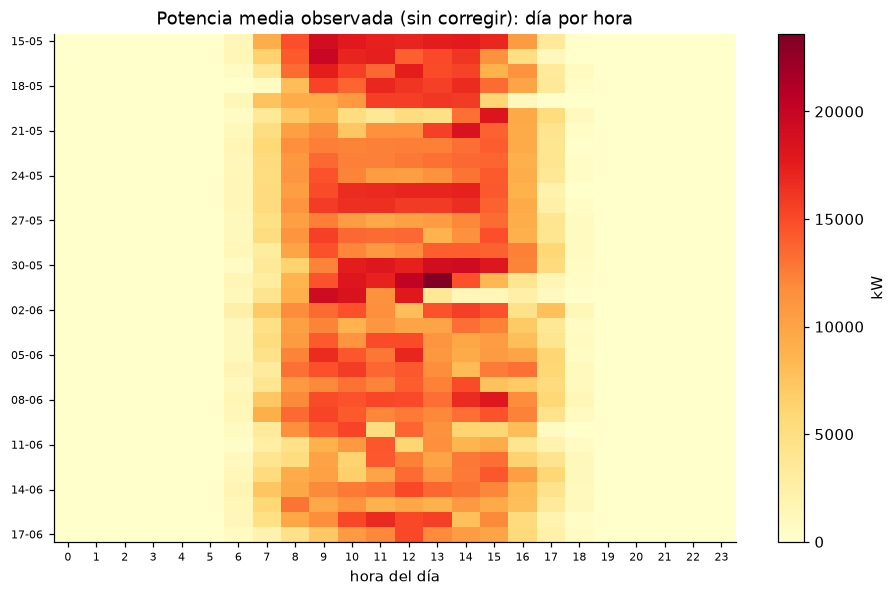

In [12]:
mapa = d[d.n_inv > 0].assign(fecha=lambda t: t.index.normalize(), hr=lambda t: t.index.hour).pivot_table(index='fecha', columns='hr', values='AC_OBS_KW', aggfunc='mean')
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(mapa.values, aspect='auto', cmap='YlOrRd'); ax.grid(False)
ax.set_yticks(range(0, len(mapa), 3)); ax.set_yticklabels([x.strftime('%d-%m') for x in mapa.index[::3]], fontsize=7)
ax.set_xticks(range(len(mapa.columns))); ax.set_xticklabels(mapa.columns, fontsize=7); ax.set_xlabel('hora del día')
ax.set_title('Potencia media observada (sin corregir): día por hora'); fig.colorbar(im, ax=ax, label='kW')
fig.savefig('figuras/f2_mapa_dia_hora.png', dpi=200, bbox_inches='tight'); plt.show()

Hay días seguidos parecidos y cambios bruscos entre rachas: el clima tiene memoria de un día a otro. Los últimos días aparecen más apagados que los primeros; esto importa porque la partición cronológica (3.1.4) pondrá los días más nublados en la prueba. Las celdas más claras en los días con inversores ausentes (suma observada sin corregir) subestiman la planta, lo que motiva la corrección de 3.2.1.

### 2.3.5 Memoria de la serie
La autocorrelación mide cuánto se parece la potencia de ahora a la de uno, dos, ... pasos antes. Sirve para decidir cuántos rezagos usar. Se muestra la ACF y la PACF a 8 pasos (2 h), la autocorrelación a 48 h con y sin el ciclo diario, y la prueba de Dickey-Fuller aumentada (ADF) de estacionariedad [14].

rezago (x 15 min),1,2,4,8,16,48,96,192
autocorrelación,0.94,0.90,0.84,0.68,0.29,-0.61,0.85,0.81
sin ciclo diario (anomalía),0.69,0.49,0.37,0.22,0.04,0.00,0.09,-0.09


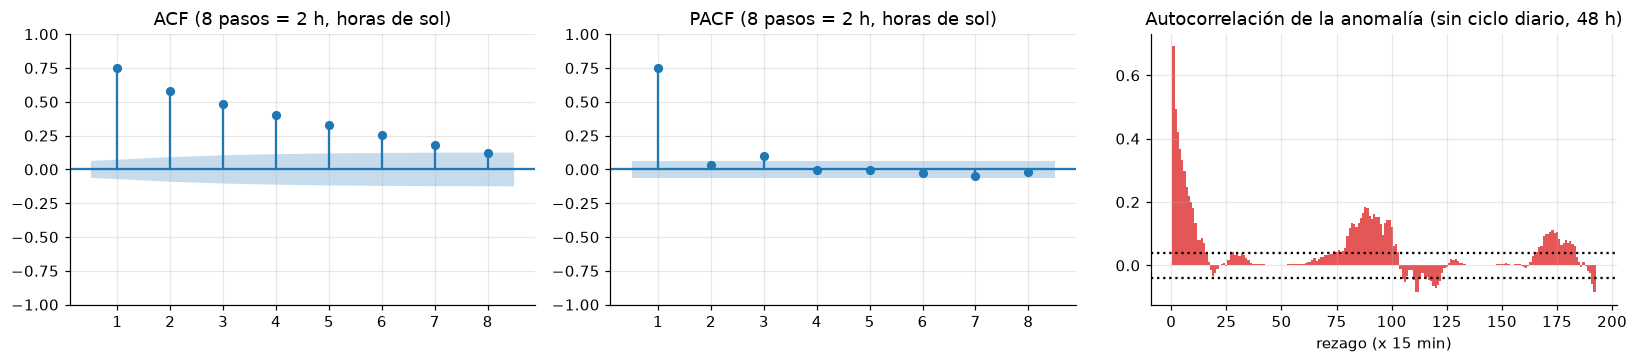

,instantes,estadístico ADF,valor p,rezagos usados,crítico 1 %,crítico 5 %
prueba ADF,2327,-10.5847,0.0,27,-3.4332,-2.8628


Correlación de la potencia con cada variable k pasos antes (k = 0 es el mismo instante):


,k=0,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8
AMBIENT_TEMPERATURE,0.70,0.65,0.61,0.56,0.52,0.47,0.42,0.37,0.32
MODULE_TEMPERATURE,0.89,0.85,0.83,0.80,0.76,0.73,0.69,0.64,0.60
IRRADIATION,0.93,0.89,0.87,0.85,0.83,0.80,0.77,0.73,0.70


In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
serie_p = d.AC_OBS_KW.where(comp)                                     # solo instantes con los 22 inversores
banda = 1.96 / np.sqrt(serie_p.notna().sum())
acf192 = pd.Series({k: serie_p.autocorr(lag=k) for k in range(1, 193)})
anomalia = serie_p - serie_p.groupby(hora_dia).transform('mean')
acf_an = pd.Series({k: anomalia.autocorr(lag=k) for k in range(1, 193)})
rezagos_tabla = [1, 2, 4, 8, 16, 48, 96, 192]
display(pd.DataFrame({'autocorrelación': acf192.loc[rezagos_tabla], 'sin ciclo diario (anomalía)': acf_an.loc[rezagos_tabla]}).round(2).rename_axis('rezago (x 15 min)').T)
serie_dia = serie_p[sol_x].dropna()                                   # horas de sol sin vacíos (una pequeña discontinuidad entre días no cambia la lectura)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
plot_acf(serie_dia, lags=8, ax=ax[0], zero=False, title='ACF (8 pasos = 2 h, horas de sol)')
plot_pacf(serie_dia, lags=8, ax=ax[1], zero=False, title='PACF (8 pasos = 2 h, horas de sol)')
ax[2].bar(acf_an.index, acf_an.values, width=1, color='#e45756'); ax[2].set_title('Autocorrelación de la anomalía (sin ciclo diario, 48 h)')
ax[2].axhline(banda, ls=':', c='k'); ax[2].axhline(-banda, ls=':', c='k'); ax[2].set_xlabel('rezago (x 15 min)')
fig.tight_layout(); fig.savefig('figuras/f2_acf_pacf.png', dpi=200, bbox_inches='tight'); plt.show()
est_adf, p_adf, lags_adf, n_adf, crit_adf, _ = adfuller(serie_p.dropna(), autolag='AIC')
display(pd.DataFrame({'instantes': [n_adf], 'estadístico ADF': [est_adf], 'valor p': [p_adf], 'rezagos usados': [lags_adf], 'crítico 1 %': [crit_adf['1%']], 'crítico 5 %': [crit_adf['5%']]}, index=['prueba ADF']).round(4))
cruz = pd.DataFrame({c_: [serie_p.corr(d[c_].shift(k)) for k in range(9)] for c_ in COLS_SENSOR}, index=[f'k={k}' for k in range(9)]).T
print('Correlación de la potencia con cada variable k pasos antes (k = 0 es el mismo instante):'); display(cruz.round(2))

La autocorrelación del primer rezago es muy alta y decae poco a poco; la PACF muestra que, una vez conocido el rezago 1, los siguientes aportan poco, aunque el de 45 min todavía sobresale levemente de la banda. Al quitar el ciclo diario, el rezago de 24 h casi desaparece: la memoria útil es de corto plazo. La irradiancia y las temperaturas pierden correlación con la potencia al crecer k. La ADF resume qué tan estacionaria es la serie (el ciclo diario hace que la serie completa no lo sea por construcción; por eso se trabaja con rezagos y con la hora, no con la serie en bruto) [14]. Hipótesis 5: bastan rezagos cortos (15, 30 y 60 min) de la potencia y del sensor; se decide en 3.1.2.

### 2.3.6 Correlaciones

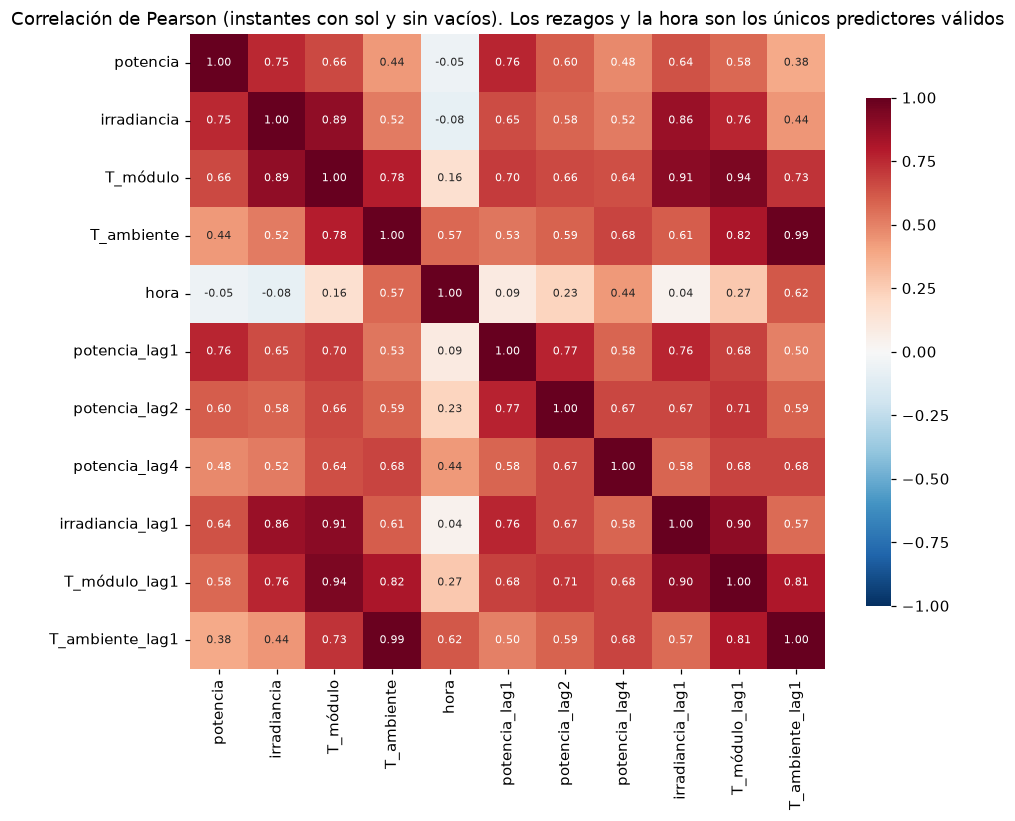

Correlación de Spearman con la potencia (relaciones monótonas):


,Spearman
irradiancia,0.810
potencia_lag1,0.768
T_módulo,0.692
irradiancia_lag1,0.686
potencia_lag2,0.627
T_módulo_lag1,0.596
potencia_lag4,0.491
T_ambiente,0.443
T_ambiente_lag1,0.380
hora,-0.047


In [14]:
v = pd.DataFrame({'potencia': d.AC_OBS_KW.where(comp), 'irradiancia': d.IRRADIATION, 'T_módulo': d.MODULE_TEMPERATURE, 'T_ambiente': d.AMBIENT_TEMPERATURE, 'hora': hora_dia}, index=d.index)
for p in (1, 2, 4): v[f'potencia_lag{p}'] = v.potencia.shift(p)
for c_ in ('irradiancia', 'T_módulo', 'T_ambiente'): v[f'{c_}_lag1'] = v[c_].shift(1)
vs = v[sol_x].dropna()
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(vs.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, annot_kws={'size': 7}, square=True, cbar_kws={'shrink': .8}, ax=ax)
ax.grid(False); ax.set_title('Correlación de Pearson (instantes con sol y sin vacíos). Los rezagos y la hora son los únicos predictores válidos')
fig.savefig('figuras/f2_correlaciones.png', dpi=200, bbox_inches='tight'); plt.show()
sp = pd.Series({c_: stats.spearmanr(vs.potencia, vs[c_])[0] for c_ in vs.columns if c_ != 'potencia'}).sort_values(ascending=False)
print('Correlación de Spearman con la potencia (relaciones monótonas):'); display(sp.round(3).to_frame('Spearman'))

La matriz deja varias cosas interesantes. La primera es que la potencia de la planta se relaciona mucho más con lo que acaba de pasar (su propio valor de hace 15 minutos y la irradiancia) que con el reloj: la hora casi no tiene correlación lineal con la potencia, y no porque no importe, sino porque la curva diaria sube y baja y esa forma de campana se cancela en una correlación lineal. La segunda es que la temperatura del módulo y la irradiancia casi se confunden (correlación cercana a 0,9): el módulo se calienta cuando hay sol, así que ambas variables cuentan la misma historia y aportarán información muy parecida al modelo. La tercera es que la tabla de Spearman, que mide relaciones monótonas sin exigir linealidad, ordena las variables de una forma coherente con la física: irradiancia, potencia reciente y temperatura del módulo arriba, temperatura ambiente más abajo. De aquí sale una pista para lo que viene: los predictores útiles serán los rezagos de la potencia y del sensor, y la hora tendrá que entrar transformada.

### 2.3.7 Informe de exploración
- Hipótesis formuladas: (1) el nivel depende del clima del día y de pérdidas operativas; (2) la distribución de la potencia permite clasificar por terciles; (3) la irradiancia reciente informa el nivel pero no es el único factor; (4) la hora sola no basta y en bruto no es lineal; (5) bastan rezagos cortos.
- Atributos prometedores: la potencia reciente (rezagos), la irradiancia y las temperaturas recientes y una transformación de la hora.
- Subconjuntos útiles: las horas de sol (de noche la potencia es cero por construcción) y, para evaluar, las horas centrales, donde la decisión es difícil.
- ¿Cambió algún objetivo? No: se mantiene predecir el nivel a 15 min. Se agrega vigilar a los inversores en cero y a la planta completa en cero, porque son pérdidas que el pronóstico debe poder señalar.

## 2.4 Verificar la calidad de los datos
### 2.4.1 Malla completa e instantes sin registro

In [15]:
sin_reg = d.n_inv == 0
por_dia = pd.DataFrame({'instantes sin ningún inversor': sin_reg.groupby(d.index.normalize()).sum(),
                        'instantes con sol y algún inversor ausente': (sol_x & d.n_inv.between(1, N_INV - 1)).groupby(d.index.normalize()).sum()})
por_dia = por_dia[(por_dia > 0).any(axis=1)]; por_dia.index = por_dia.index.strftime('%d-%m')
print(f'Instantes de la malla: {len(d)} | sin ningún registro de inversor: {int(sin_reg.sum())} | sin registro del sensor: {int(d.IRRADIATION.isna().sum())} (coinciden: {bool((sin_reg == d.IRRADIATION.isna()).all())})')
print(f'Registros de inversor que faltan: {len(d) * N_INV - len(gen)} de {len(d) * N_INV} ({100 * (len(d) * N_INV - len(gen)) / (len(d) * N_INV):.1f} %)')
print(f'Días con algún instante ausente o incompleto: {len(por_dia)} de {d.index.normalize().nunique()}'); display(por_dia.T)

Instantes de la malla: 3264 | sin ningún registro de inversor: 5 | sin registro del sensor: 5 (coinciden: True)
Registros de inversor que faltan: 4110 de 71808 (5.7 %)
Días con algún instante ausente o incompleto: 14 de 34


DATE_TIME,15-05,19-05,20-05,21-05,22-05,23-05,24-05,25-05,26-05,27-05,28-05,29-05,01-06,03-06
instantes sin ningún inversor,1,1,0,0,0,0,0,0,0,0,0,1,1,1
instantes con sol y algún inversor ausente,0,0,29,43,44,43,43,42,42,43,44,35,0,0


El panorama es más limpio de lo que parece a primera vista: solo 5 de los 3 264 instantes no tienen ningún registro y son aislados (uno en cada uno de cinco días distintos), de modo que no hubo un apagón largo de adquisición. Lo que sí llama la atención es la segunda fila de la tabla: entre el 20 y el 29 de mayo hay cada día unas 43 lecturas con sol en las que faltan inversores, es decir, prácticamente todo el día durante diez días seguidos. Eso ya no se parece a un fallo puntual de comunicación sino a un grupo de inversores que quedó fuera de la adquisición, y es el hallazgo que orienta buena parte del trabajo de limpieza.

### 2.4.2 `missingno`: matriz de faltantes
Se pasan los 22 inversores y el sensor de las horas con sol a una matriz. Además de los vacíos reales de los archivos se marcan como faltantes los instantes con sol en los que toda la planta reporta cero, porque un cero con sol fuerte en los 22 inversores a la vez no se parece a una producción real (se estudian en 2.4.7).

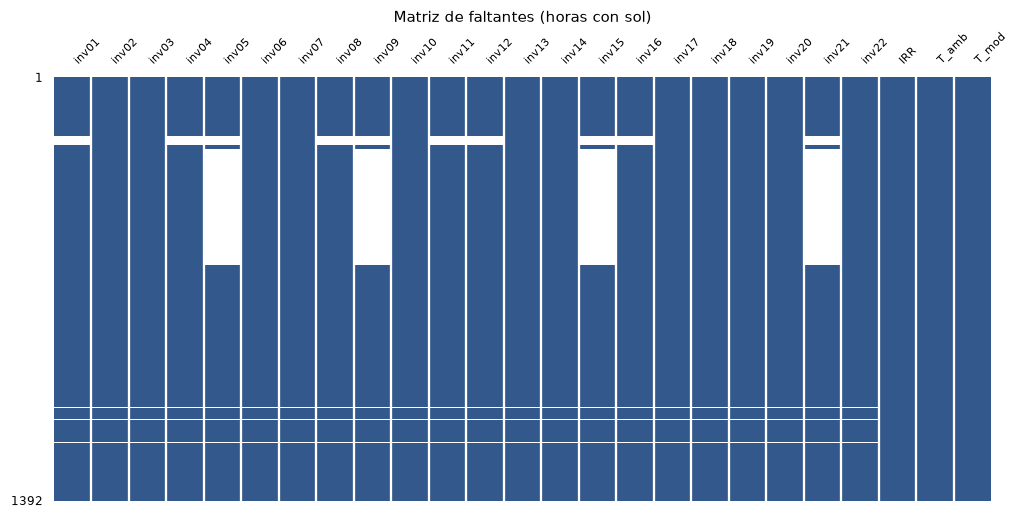

In [16]:
frame = ac[sol_x].astype(float)
frame.columns = [f'inv{i + 1:02d}' for i in range(N_INV)]
frame[['IRR', 'T_amb', 'T_mod']] = d.loc[sol_x, ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']].to_numpy()
frame.loc[todos_cero_x[sol_x].to_numpy(), frame.columns[:N_INV]] = np.nan       # los ceros de toda la planta se tratan como faltantes solo para estudiar su patrón
fig, ax = plt.subplots(figsize=(11, 5))
msno.matrix(frame, ax=ax, sparkline=False, fontsize=7, color=(.2, .35, .55)); ax.set_title('Matriz de faltantes (horas con sol)', fontsize=10)
fig.savefig('figuras/f2_msno_matriz.png', dpi=200, bbox_inches='tight'); plt.show()

Los vacíos no son puntos sueltos: son bloques horizontales en pocos inversores durante periodos largos, más las rayas completas de los instantes en que toda la planta marca cero. Eso apunta a causas comunes (comunicación, parada) y no a ruido aleatorio.

### 2.4.3 `missingno`: barras de datos presentes

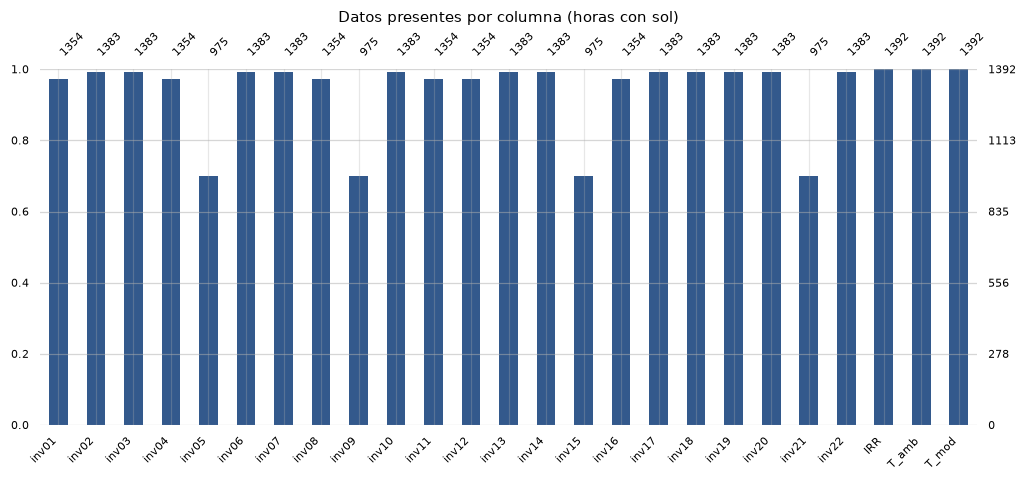

Inversores con más de 5 % de horas de sol sin dato: 4 (inv05, inv09, inv15, inv21); faltan en 29 % de las horas de sol, en 10 días (20-05 a 29-05).


In [17]:
fig, ax = plt.subplots(figsize=(11, 4.2))
msno.bar(frame, ax=ax, fontsize=7, color=(.2, .35, .55)); ax.set_title('Datos presentes por columna (horas con sol)', fontsize=10)
fig.savefig('figuras/f2_msno_barras.png', dpi=200, bbox_inches='tight'); plt.show()
na_inv = ac[sol_x].isna(); frac_na = na_inv.mean()
top = frac_na[frac_na > .05].index; dias_f = na_inv.index[na_inv[top].any(axis=1)].normalize().unique()
print(f'Inversores con más de 5 % de horas de sol sin dato: {len(top)} ({", ".join(f"inv{list(ac.columns).index(c_) + 1:02d}" for c_ in top)}); faltan en {100 * frac_na[top].mean():.0f} % de las horas de sol, en {len(dias_f)} días ({dias_f.min():%d-%m} a {dias_f.max():%d-%m}).')

Casi todas las columnas están completas; los inversores con barras más cortas son pocos y fallan en un periodo de días seguidos (no repartidos por todo el mes). El sensor (`IRR`, `T_amb`, `T_mod`) está completo en las horas con sol.

### 2.4.4 `missingno`: mapa de calor de nulidad
Si los faltantes de unos inversores ocurren al mismo tiempo que los de otros (correlación de nulidad alta), hay una causa compartida; si son independientes, cada inversor falla por su cuenta. Esto decide si la corrección debe hacerse por grupos de inversores ausentes.

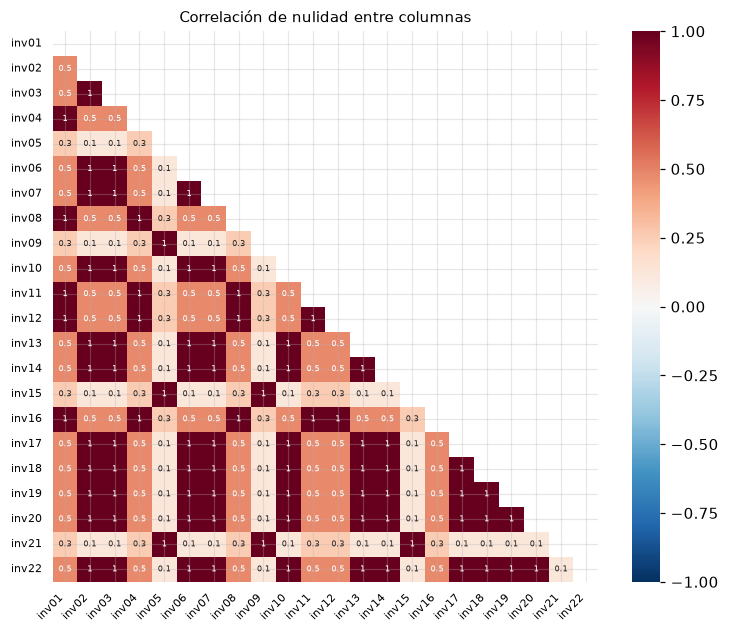

In [18]:
fig, ax = plt.subplots(figsize=(8, 6.5))
msno.heatmap(frame, ax=ax, fontsize=7, cmap='RdBu_r'); ax.set_title('Correlación de nulidad entre columnas', fontsize=10)
fig.savefig('figuras/f2_msno_heatmap.png', dpi=200, bbox_inches='tight'); plt.show()

Los inversores se ausentan en bloques: dentro de cada bloque la correlación de nulidad es 1 (faltan en los mismos instantes) y entre bloques es baja o media. Hay una causa compartida por bloque (por ejemplo, un concentrador de datos), no fallas independientes. Por eso la corrección de 3.2.1 se hace por patrón de ausencia (el grupo exacto de inversores que falta en cada instante).

### 2.4.5 `missingno`: dendrograma

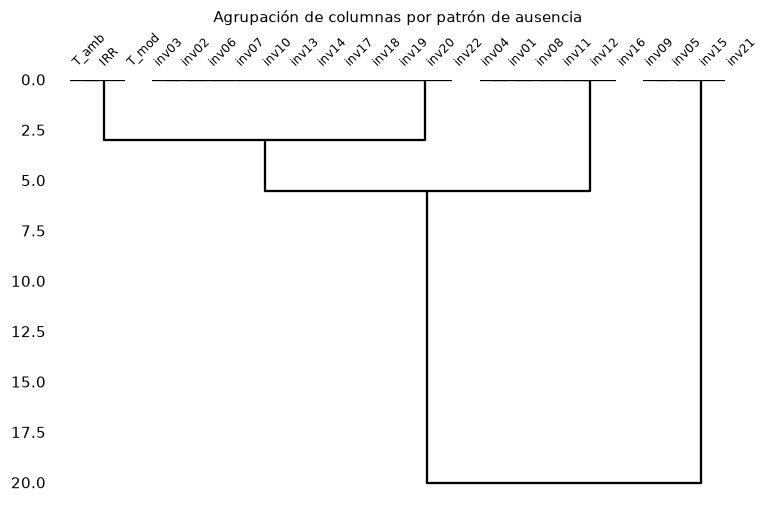

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
msno.dendrogram(frame, ax=ax, fontsize=8); ax.set_title('Agrupación de columnas por patrón de ausencia', fontsize=10)
fig.savefig('figuras/f2_msno_dendrograma.png', dpi=200, bbox_inches='tight'); plt.show()

El dendrograma separa los inversores en tres ramas según su patrón de ausencia, y el sensor queda aparte. Una de ellas reúne a los cuatro inversores que más faltan (los mismos de 2.4.3), que se ausentan juntos durante varios días. Con esto se confirma que los faltantes son estructurados.

### 2.4.6 Línea de tiempo de los tres tipos de faltante

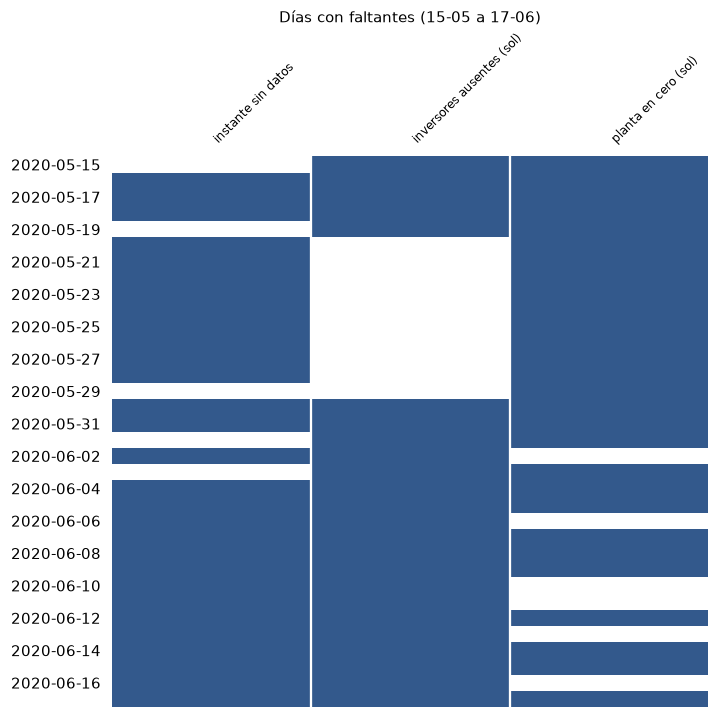

In [20]:
# Línea de tiempo de los tres tipos de faltante, un renglón por día: el vacío (blanco) marca que ese día hubo al menos un faltante
tl = pd.DataFrame({'instante sin datos': np.where(d.n_inv == 0, np.nan, 1.0),
                   'inversores ausentes (sol)': np.where(sol_x & d.n_inv.between(1, N_INV - 1), np.nan, 1.0),
                   'planta en cero (sol)': np.where(todos_cero_x, np.nan, 1.0)}, index=d.index)
tl = tl.groupby(tl.index.normalize()).agg(lambda s: np.nan if s.isna().any() else 1.0)
fig, ax = plt.subplots(figsize=(7, 6.5))
msno.matrix(tl, ax=ax, sparkline=False, fontsize=8, freq='2D', color=(.2, .35, .55)); ax.set_title('Días con faltantes (15-05 a 17-06)', fontsize=10)
fig.savefig('figuras/f2_msno_tiempo.png', dpi=200, bbox_inches='tight'); plt.show()

Cada renglón es un día y el blanco marca que ese día tuvo al menos un faltante de cada tipo. Los instantes sin datos son pocos y aislados; los inversores ausentes con sol se concentran en un bloque de días seguidos de la primera mitad del mes; los instantes con toda la planta en cero aparecen también al final del mes. Son tres problemas distintos y se tratan por separado en la fase 3.

### 2.4.7 Planta completa en cero con sol
Se listan los episodios (día, hora, instantes, irradiancia y lo que hace el contador de rendimiento diario antes y después) y se compara con la Planta 1.

In [21]:
from math import comb
# Los episodios de planta en cero: cuándo, con cuánto sol y qué hace el contador de rendimiento diario
dias_es = ['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom']
rend = gen.pivot(index='DATE_TIME', columns='SOURCE_KEY', values='DAILY_YIELD').reindex(d.index)
grupo = (~todos_cero_x).cumsum()[todos_cero_x]                                  # instantes seguidos comparten grupo
filas = []
for _, idx in grupo.groupby(grupo).groups.items():
    ini, fin = idx.min(), idx.max(); antes, desp = rend.loc[ini - pd.Timedelta('15min')].median(), rend.loc[fin + pd.Timedelta('15min')].median()
    filas.append({'día': f'{ini:%d-%m} {dias_es[ini.weekday()]}', 'hora': f'{ini:%H:%M}', 'instantes': len(idx),
                  'irradiación (kW/m²)': round(d.loc[idx, 'IRRADIATION'].mean(), 2),
                  'rend. diario antes (kWh)': round(antes), 'rend. diario después (kWh)': round(desp),
                  'contador': 'baja' if desp < antes else 'sigue'})
episodios = pd.DataFrame(filas); display(episodios)

# ¿Es de todo o nada? Cuántos inversores están en cero a la vez en las horas de sol
z = ((ac == 0) & sol_x.to_numpy()[:, None]).sum(axis=1)[sol_x]
fuera = z[z < N_INV]
# ¿Se concentran en ciertas horas o días? Probabilidad de que caigan donde caen si fueran al azar
horas = d.index.hour + d.index.minute / 60; h_ev = horas[todos_cero_x.to_numpy()]
p_h = ((horas >= h_ev.min()) & (horas <= h_ev.max()))[sol_x.to_numpy()].mean()
dias_sol = d.index[sol_x].normalize().unique(); ev_dias = d.index[todos_cero_x].normalize().unique()
n_ult = int((dias_sol >= ev_dias.min()).sum())
# ¿Pasa lo mismo en la Planta 1 (otra planta del mismo conjunto de Kaggle)?
try:
    r1 = buscar_datos('Plant_1_Generation_Data.csv')
    ac1 = pd.read_csv(os.path.join(r1, 'Plant_1_Generation_Data.csv'), parse_dates=['DATE_TIME'], date_format='%d-%m-%Y %H:%M').pivot(index='DATE_TIME', columns='SOURCE_KEY', values='AC_POWER')
    irr1 = pd.read_csv(os.path.join(r1, 'Plant_1_Weather_Sensor_Data.csv'), parse_dates=['DATE_TIME'], date_format=FMT).set_index('DATE_TIME').IRRADIATION.reindex(ac1.index)
    p1 = int(((irr1 > IRR_EXPLORACION) & (ac1.notna().sum(axis=1) > 0) & ((ac1 == 0).sum(axis=1) == ac1.notna().sum(axis=1))).sum()); txt_p1 = f'En la Planta 1 hay {p1} instantes así: el problema es de la Planta 2.' if p1 == 0 else f'En la Planta 1 hay {p1} instantes así.'
except Exception as e:
    txt_p1 = f'No se pudo comparar con la Planta 1 ({type(e).__name__}).'

,día,hora,instantes,irradiación (kW/m²),rend. diario antes (kWh),rend. diario después (kWh),contador
0,02-06 mar,12:30,1,1.08,2653,2236,baja
1,02-06 mar,16:15,2,0.40,4037,4579,sigue
2,06-06 sáb,14:30,1,0.60,5192,3106,baja
3,10-06 mié,11:15,2,0.77,2165,1592,baja
4,11-06 jue,12:00,1,0.62,1832,297,baja
5,13-06 sáb,10:45,1,0.50,480,734,sigue
6,16-06 mar,14:30,1,0.56,1947,3629,sigue


Los episodios se concentran en las horas centrales y en las últimas semanas, ocurren en los 22 inversores a la vez (algo que no pasa en ninguna otra hora con sol) y no aparecen en la Planta 1. Con tan pocos casos es una tendencia, no una regla. El contador de rendimiento diario no permite saber si fue una parada real o un registro vacío: en unos episodios baja después (como un reinicio) y en otros sigue. Esta ambigüedad se resuelve en 3.2.3 con una decisión explícita.

### 2.4.8 Inversores individuales en cero con sol

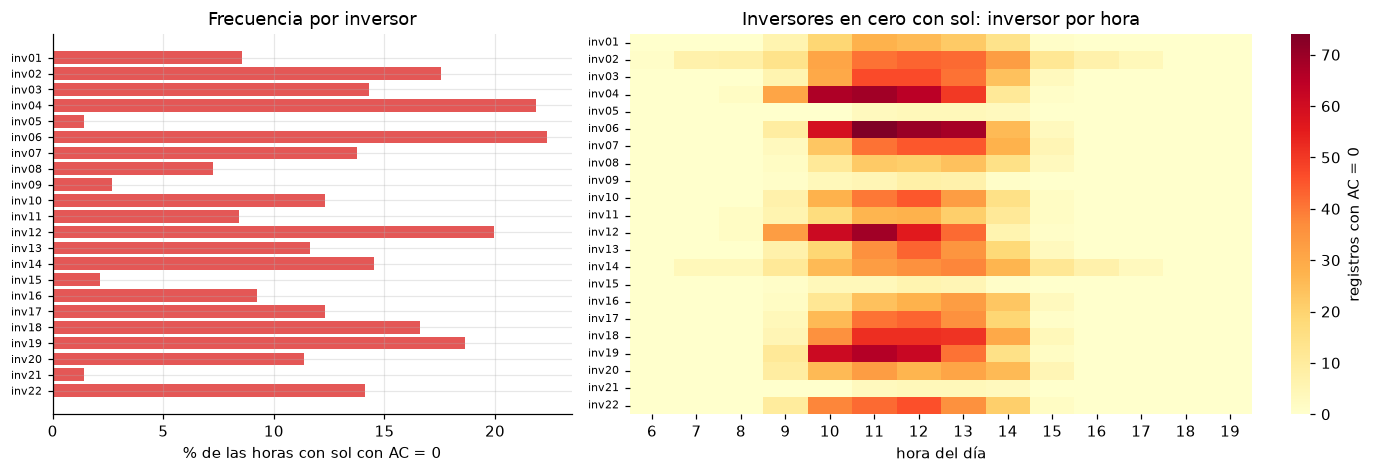

Registros con sol y AC = 0 (sin contar la planta completa en cero): 3576; con DC = 0 también: 3576 (100 %).


In [22]:
cero_inv = pd.DataFrame((ac == 0).to_numpy() & sol_x.to_numpy()[:, None] & ~todos_cero_x.to_numpy()[:, None], index=ac.index, columns=[f'inv{i + 1:02d}' for i in range(N_INV)])
frec_inv = cero_inv.sum() / ac[sol_x & ~todos_cero_x].notna().sum().to_numpy()
por_hora = cero_inv.groupby(cero_inv.index.hour).sum().loc[6:19]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'width_ratios': [1, 1.5]})
ax[0].barh(frec_inv.index[::-1], 100 * frec_inv.values[::-1], color='#e45756'); ax[0].set_xlabel('% de las horas con sol con AC = 0'); ax[0].set_title('Frecuencia por inversor'); ax[0].tick_params(axis='y', labelsize=7)
sns.heatmap(por_hora.T, cmap='YlOrRd', ax=ax[1], cbar_kws={'label': 'registros con AC = 0'}); ax[1].grid(False); ax[1].tick_params(axis='y', labelsize=7)
ax[1].set_xlabel('hora del día'); ax[1].set_title('Inversores en cero con sol: inversor por hora')
fig.tight_layout(); fig.savefig('figuras/f2_inversores_cero.png', dpi=200, bbox_inches='tight'); plt.show()
dc_cero = int((((dc == 0) & (ac == 0)).to_numpy() & sol_x.to_numpy()[:, None] & ~todos_cero_x.to_numpy()[:, None]).sum())
print(f'Registros con sol y AC = 0 (sin contar la planta completa en cero): {int(cero_inv.to_numpy().sum())}; con DC = 0 también: {dc_cero} ({100 * dc_cero / max(int(cero_inv.to_numpy().sum()), 1):.0f} %).')

Los ceros de inversores individuales con sol afectan a casi todos los inversores (unos mucho más que otros) y se concentran en las horas centrales. Los cuatro inversores que más faltan en los archivos casi nunca marcan cero. Todos los ceros vienen con DC = 0 también: el inversor no recibe corriente (desconexión o falla aguas arriba), no es un error de conversión. Son pérdidas reales de la planta, no errores de medición.

### 2.4.9 Duplicados, coherencia, lecturas congeladas y saltos

In [23]:
filas_q = []
inter = {n: pd.Series(sorted(df.DATE_TIME.unique())).diff().dropna().value_counts() for n, df in (('generación', gen), ('sensor', sen))}
filas_q.append(('Intervalos entre registros distinto de 15 min', {n: int(v[v.index != pd.Timedelta('15min')].sum()) for n, v in inter.items()}, 'cada hueco es un instante que falta'))
filas_q.append(('Duplicados (instante, inversor)', int(gen.duplicated(['DATE_TIME', 'SOURCE_KEY']).sum()), 'ninguno'))
filas_q.append(('Fechas del sensor que no están en generación y viceversa', (len(set(sen.DATE_TIME) - set(gen.DATE_TIME)), len(set(gen.DATE_TIME) - set(sen.DATE_TIME))), 'ambos archivos tienen los mismos instantes'))
rangos = [('IRRADIATION', sen, 0, 1.5), ('MODULE_TEMPERATURE', sen, -5, 90), ('AMBIENT_TEMPERATURE', sen, -5, 50), ('AC_POWER', gen, 0, np.inf), ('DC_POWER', gen, 0, np.inf)]
filas_q.append(('Valores fuera del rango físico', {v: int(((t[v] < lo) | (t[v] > hi)).sum()) for v, t, lo, hi in rangos}, 'IRRADIATION 0-1.5 kW/m², módulo −5-90 °C, ambiente −5-50 °C, potencias mayor o igual a 0'))
filas_q.append(('Registros con AC > DC', int((gen.AC_POWER > gen.DC_POWER).sum()), 'el inversor no puede entregar más de lo que recibe'))
def corridas(serie, activo):
    x = serie[activo]; seguido = x.index.to_series().diff() == pd.Timedelta('15min')
    return x.groupby((x.ne(x.shift()) | ~seguido).cumsum()).size()
activo = sol_x & (d.n_inv > 0)
filas_q.append(('Lecturas congeladas (corrida más larga de valores idénticos, en pasos de 15 min)', {v: int(corridas(d[v], activo).max()) for v in ['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'AC_OBS_KW']}, 'más de 4 pasos seguidos sería sospechoso'))
consec = comp & comp.shift(fill_value=False) & sol_x & sol_x.shift(fill_value=False)
dI, dA = d.IRRADIATION.diff()[consec], d.AC_OBS_KW.diff()[consec]; top_i = dI.abs().nlargest(20).index
filas_q.append(('Saltos bruscos: correlación entre el cambio de irradiancia y el de potencia', round(float(dI.corr(dA)), 2), f'en los 20 mayores saltos de irradiancia la potencia se movió en la misma dirección {int((np.sign(dI[top_i]) == np.sign(dA[top_i])).sum())} veces'))
pd.set_option('display.max_colwidth', 220); display(pd.DataFrame(filas_q, columns=['prueba', 'resultado', 'qué indica']))

,prueba,resultado,qué indica
0,Intervalos entre registros distinto de 15 min,"{'generación': 5, 'sensor': 5}",cada hueco es un instante que falta
1,"Duplicados (instante, inversor)",0,ninguno
2,Fechas del sensor que no están en generación y viceversa,"(0, 0)",ambos archivos tienen los mismos instantes
3,Valores fuera del rango físico,"{'IRRADIATION': 0, 'MODULE_TEMPERATURE': 0, 'AMBIENT_TEMPERATURE': 0, 'AC_POWER': 0, 'DC_POWER': 0}","IRRADIATION 0-1.5 kW/m², módulo −5-90 °C, ambiente −5-50 °C, potencias mayor o igual a 0"
4,Registros con AC > DC,18,el inversor no puede entregar más de lo que recibe
5,"Lecturas congeladas (corrida más larga de valores idénticos, en pasos de 15 min)","{'IRRADIATION': 1, 'MODULE_TEMPERATURE': 1, 'AMBIENT_TEMPERATURE': 1, 'AC_OBS_KW': 2}",más de 4 pasos seguidos sería sospechoso
6,Saltos bruscos: correlación entre el cambio de irradiancia y el de potencia,0.61,en los 20 mayores saltos de irradiancia la potencia se movió en la misma dirección 15 veces


Las verificaciones son tranquilizadoras: los dos archivos tienen exactamente los mismos instantes (y los mismos 5 huecos), no hay duplicados ni valores fuera de los rangos físicos, y el sensor no tiene lecturas congeladas. Hay un detalle menor que vale la pena registrar: 18 registros de inversor entregan más potencia AC que DC, algo que en rigor no debería pasar; frente a más de 67 000 registros es una fracción insignificante y apunta más a redondeos o a desfases de medición que a un problema real. Por último, el cambio de irradiancia y el de potencia entre un instante y el siguiente se mueven juntos (correlación de 0,61), lo que sugiere que buena parte de los saltos bruscos de potencia tiene una causa meteorológica y no un error del equipo de medida.

### 2.4.10 Atípicos por franja horaria

In [24]:
base_seg = d[sol_x & comp].copy()
base_seg['franja'] = pd.cut(base_seg.index.hour + base_seg.index.minute / 60, [5, 9, 12, 15, 20], right=False, labels=['5-9 h', '9-12 h', '12-15 h', '15-20 h'])
def atipicos_iqr(x):
    q1, q3 = x.quantile([.25, .75]); i = q3 - q1
    return pd.Series({'instantes': len(x), 'límite inferior': round(q1 - 1.5 * i), 'límite superior': round(q3 + 1.5 * i),
                      'fuera por abajo': int((x < q1 - 1.5 * i).sum()), 'fuera por arriba': int((x > q3 + 1.5 * i).sum())})
glob_iqr = atipicos_iqr(base_seg.AC_OBS_KW)
seg_iqr = pd.DataFrame({f_: atipicos_iqr(g_.AC_OBS_KW) for f_, g_ in base_seg.groupby('franja', observed=True)}).T
n_iqr_f = int(seg_iqr[['fuera por abajo', 'fuera por arriba']].sum().sum())
print('IQR global de la potencia observada: fuera por abajo', glob_iqr['fuera por abajo'], '| fuera por arriba', glob_iqr['fuera por arriba'])
display(seg_iqr); print('Total de atípicos segmentando por franja:', n_iqr_f)
marc = pd.Series(False, index=base_seg.index)
for f_, g_ in base_seg.groupby('franja', observed=True):
    q1_, q3_ = g_.AC_OBS_KW.quantile([.25, .75]); marc[g_.index] = (g_.AC_OBS_KW < q1_ - 1.5 * (q3_ - q1_)) | (g_.AC_OBS_KW > q3_ + 1.5 * (q3_ - q1_))
n_marc_cero = int((base_seg[marc].n_inv_cero == N_INV).sum())
print(f'De los {int(marc.sum())} marcados, {n_marc_cero} son instantes con toda la planta en cero (2.4.7) y {int(marc.sum()) - n_marc_cero} no lo son.')
display(base_seg[marc][['IRRADIATION', 'AC_OBS_KW', 'n_inv_cero']].round(2).T)

IQR global de la potencia observada: fuera por abajo 0 | fuera por arriba 1


,instantes,límite inferior,límite superior,fuera por abajo,fuera por arriba
5-9 h,169,-3784,19805,0,0
9-12 h,288,3000,24113,3,1
12-15 h,282,3296,24337,8,3
15-20 h,245,-4476,22862,0,0


Total de atípicos segmentando por franja: 15
De los 15 marcados, 7 son instantes con toda la planta en cero (2.4.7) y 8 no lo son.


DATE_TIME,2020-05-31 13:15:00,2020-05-31 14:00:00,2020-06-01 10:15:00,2020-06-01 12:30:00,2020-06-02 12:30:00,2020-06-06 14:30:00,2020-06-10 11:15:00,2020-06-10 11:30:00,2020-06-10 14:00:00,2020-06-11 12:00:00,2020-06-11 12:15:00,2020-06-12 13:00:00,2020-06-13 10:45:00,2020-06-16 14:30:00,2020-06-17 13:45:00
IRRADIATION,0.96,0.92,0.92,0.92,1.08,0.6,0.77,0.78,0.38,0.62,0.39,0.49,0.5,0.56,0.58
AC_OBS_KW,25409.60,24595.29,24514.15,25979.76,0.00,0.0,0.00,0.00,3096.20,0.00,1287.88,3078.35,0.0,0.00,1743.61
n_inv_cero,1.00,1.00,0.00,0.00,22.00,22.0,22.00,22.00,0.00,22.00,0.00,0.00,22.0,22.00,0.00


Con el IQR calculado dentro de cada franja horaria quedan marcados pocos instantes (cerca del 1,5 % de los completos). Casi la mitad son instantes con toda la planta en cero, que ya se estudiaron en 2.4.7; el resto son extremos por arriba o por abajo con irradiancia coherente, sin evidencia de error de medición (por ejemplo, un paso de nubes o pérdidas reales). No hay valores imposibles que eliminar; la decisión de no eliminar nada se confirma en 3.2.4.

### 2.4.11 Irradiancia cerca de cero
Evidencia para el umbral de horas de sol (3.1.1): en qué rango de irradiancia la potencia de la planta ya es prácticamente cero.

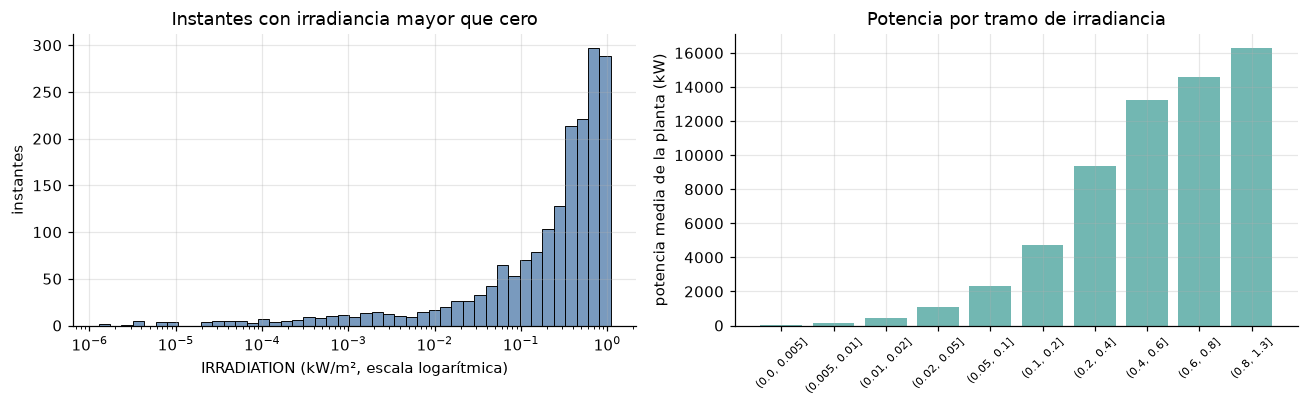

,instantes,potencia_media_kW,potencia_mediana_kW,% con potencia 0
IRRADIATION,,,,
"(0.0, 0.005]",130,7.0,0.0,85.4
"(0.005, 0.01]",23,165.8,143.6,0.0
"(0.01, 0.02]",40,433.5,437.2,0.0
"(0.02, 0.05]",78,1084.9,1114.3,0.0
"(0.05, 0.1]",102,2309.0,2205.1,0.0
"(0.1, 0.2]",145,4717.4,4709.0,0.0
"(0.2, 0.4]",281,9372.3,9495.8,0.4
"(0.4, 0.6]",215,13240.7,13834.0,1.4
"(0.6, 0.8]",193,14599.1,14925.9,2.1


In [25]:
irr_pos = d.loc[d.IRRADIATION > 0, 'IRRADIATION']
bordes = [0, .005, .01, .02, .05, .1, .2, .4, .6, .8, 1.3]
tr_irr = pd.cut(d.IRRADIATION[comp], bordes, include_lowest=False)
tab_irr = d[comp].groupby(tr_irr, observed=True).AC_OBS_KW.agg(instantes='size', potencia_media_kW='mean', potencia_mediana_kW='median')
tab_irr['% con potencia 0'] = d[comp].groupby(tr_irr, observed=True).AC_OBS_KW.apply(lambda s: 100 * (s == 0).mean())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(irr_pos, bins=45, log_scale=True, color='#4c78a8', ax=ax[0]); ax[0].set_xlabel('IRRADIATION (kW/m², escala logarítmica)'); ax[0].set_ylabel('instantes'); ax[0].set_title('Instantes con irradiancia mayor que cero')
ax[1].bar(range(len(tab_irr)), tab_irr.potencia_media_kW, color='#72b7b2'); ax[1].set_xticks(range(len(tab_irr))); ax[1].set_xticklabels([str(i) for i in tab_irr.index], rotation=45, fontsize=7)
ax[1].set_ylabel('potencia media de la planta (kW)'); ax[1].set_title('Potencia por tramo de irradiancia')
fig.tight_layout(); fig.savefig('figuras/f2_irradiancia_baja.png', dpi=200, bbox_inches='tight'); plt.show()
display(tab_irr.round(1))

Por debajo de 0,005 kW/m² la planta casi siempre marca exactamente 0 kW; entre 0,005 y 0,02 la potencia media es pequeña frente a la de las horas con sol (del orden de pocos por ciento) y crece rápido por encima. Esa zona de transición es donde hay que trazar la línea; se fija el umbral en 3.1.1 con una tabla de sensibilidad.

### 2.4.12 Informe de calidad

In [26]:
reg_falt0 = len(d) * N_INV - len(gen)
cer_sol = ((ac == 0).to_numpy() & sol_x.to_numpy()[:, None] & ~todos_cero_x.to_numpy()[:, None]).sum(); reg_sol0 = int(ac[sol_x].notna().sum().sum())
informe_calidad = pd.DataFrame([
    ('Instantes sin ningún registro', f'{int(sin_reg.sum())} de {len(d)} instantes (aislados; iguales en ambos archivos)', '2.4.1', 'Decidir si se interpolan (3.2.2)'),
    ('Inversores ausentes en instantes con sol', f'{int((sol_x & d.n_inv.between(1, N_INV - 1)).sum())} de {int(sol_x.sum())} instantes con sol; {reg_falt0} registros de inversor ({100 * reg_falt0 / (len(d) * N_INV):.1f} %)', '2.4.2 a 2.4.6', 'Corregir la suma por patrón de ausencia, excluir o mantener (3.2.1)'),
    ('Planta completa en cero con sol', f'{int(todos_cero_x.sum())} instantes', '2.4.2, 2.4.6 y 2.4.7', 'Mantener o excluir (3.2.3)'),
    ('Inversores individuales en cero con sol', f'{int(cer_sol)} de {reg_sol0} registros ({100 * cer_sol / reg_sol0:.1f} %)', '2.4.8', 'Mantener: son pérdidas reales (3.2.4)'),
    ('Atípicos (IQR por franja)', f'{n_iqr_f} instantes', '2.4.10', 'No eliminar nada (3.2.4)'),
    ('Duplicados, unidades, rangos físicos', 'ninguno', '2.4.9', 'Nada que corregir'),
    ('Irradiancia cerca de cero (noche y crepúsculo)', f'{int((d.IRRADIATION > 0).sum() - sol_x.sum())} instantes con irradiancia entre 0 y {IRR_EXPLORACION} kW/m²', '2.4.11', 'Fijar el umbral de horas de sol (3.1.1)'),
], columns=['problema', 'cuánto', 'evidencia', 'tratamiento propuesto (se decide en la fase 3)'])
pd.set_option('display.max_colwidth', 120); display(informe_calidad)

,problema,cuánto,evidencia,tratamiento propuesto (se decide en la fase 3)
0,Instantes sin ningún registro,5 de 3264 instantes (aislados; iguales en ambos archivos),2.4.1,Decidir si se interpolan (3.2.2)
1,Inversores ausentes en instantes con sol,408 de 1392 instantes con sol; 4110 registros de inversor (5.7 %),2.4.2 a 2.4.6,"Corregir la suma por patrón de ausencia, excluir o mantener (3.2.1)"
2,Planta completa en cero con sol,9 instantes,"2.4.2, 2.4.6 y 2.4.7",Mantener o excluir (3.2.3)
3,Inversores individuales en cero con sol,3576 de 28818 registros (12.4 %),2.4.8,Mantener: son pérdidas reales (3.2.4)
4,Atípicos (IQR por franja),15 instantes,2.4.10,No eliminar nada (3.2.4)
5,"Duplicados, unidades, rangos físicos",ninguno,2.4.9,Nada que corregir
6,Irradiancia cerca de cero (noche y crepúsculo),470 instantes con irradiancia entre 0 y 0.1 kW/m²,2.4.11,Fijar el umbral de horas de sol (3.1.1)


Del informe de calidad se desprende lo siguiente.
- Faltantes: hay de tres tipos: instantes sin registro (aislados), inversores ausentes en bloques (causa compartida, no aleatorios) y la planta completa en cero. Significan fallas de adquisición o paradas, no ausencia de producción, salvo los ceros de inversores individuales con DC = 0, que son pérdidas reales.
- Valores raros: no hay valores fuera de rango físico ni atípicos que eliminar; lo raro son los ceros con sol.
- Consistencia entre fuentes: ambos archivos tienen los mismos instantes y la fecha se lee sin errores.
- Formato: son archivos planos CSV con delimitador coma; las fechas se convirtieron con formato explícito.

## 2.5 Cierre de la fase

| Elemento | Resultado | Dónde se ve |
|---|---|---|
| Fuentes | Dos CSV de la Planta 2 (más la Planta 1 solo para comparar) | 2.1 |
| Formato, dimensiones y tipos | Descritos | 2.2 |
| Relaciones entre variables | Exploradas, con cinco hipótesis | 2.3 |
| Calidad de los datos | Problemas documentados en el informe de calidad | 2.4.12 |
| Obstáculos para modelar | Ninguno; los problemas encontrados se tratan en la fase 3 | 2.4 |

Los datos son aptos para modelar una vez resueltos los problemas del informe de calidad.

<a id="fase3"></a>
# Fase 3: Preparación de los datos
Esta fase suele ser la que más esfuerzo consume en un proyecto de datos. Cada decisión se presenta después de la evidencia que la origina (un gráfico o una tabla de la fase 2, o una prueba nueva), con la fuente que la respalda o, si no la hay, como supuesto del equipo, y se cierra con la constante que la fija. Las decisiones se toman en este orden: umbral de horas de sol, rezagos y partición cronológica (que alimentan la corrección de faltantes, porque ésta se estima solo con días de entrenamiento), luego la limpieza, y al final la construcción de la variable objetivo y de la hora.

## 3.1 Seleccionar los datos
### 3.1.1 Horas de sol
El histograma y la tabla de 2.4.11 muestran la potencia por tramo de irradiancia. La tabla siguiente mide qué se descarta con cada umbral: cuántos instantes quedan y cuánta potencia media tenían los que se descartan, en relación con la potencia media de las horas con sol.

In [27]:
pot_ref = d.AC_OBS_KW[comp & (d.IRRADIATION > IRR_EXPLORACION)].mean()
filas_u = []
for u in [0.005, 0.01, 0.02, 0.05, 0.10, 0.20]:
    desc = d[comp & (d.IRRADIATION > 0) & (d.IRRADIATION <= u)]
    filas_u.append({'umbral (kW/m²)': u, 'instantes que quedan (con algún inversor)': int(((d.IRRADIATION > u) & (d.n_inv > 0)).sum()),
                    'instantes descartados con irradiancia > 0': len(desc), 'potencia media de lo descartado (kW)': desc.AC_OBS_KW.mean(),
                    '% de la potencia media con sol': 100 * desc.AC_OBS_KW.mean() / pot_ref})
display(pd.DataFrame(filas_u).round(1))

,umbral (kW/m²),instantes que quedan (con algún inversor),instantes descartados con irradiancia > 0,potencia media de lo descartado (kW),% de la potencia media con sol
0,0.0,1704,130,7.0,0.1
1,0.0,1676,153,30.9,0.3
2,0.0,1623,193,114.3,1.0
3,0.0,1526,271,393.7,3.4
4,0.1,1392,373,917.5,7.9
5,0.2,1214,518,1981.1,17.1


Con 0,02 kW/m² lo que se descarta pesa alrededor del 1 % de la potencia media de las horas con sol; la fracción crece rápido con umbrales mayores (varias veces más con 0,05 y mucho más con 0,10), y con 0,005 o 0,01 se conservarían instantes de crepúsculo donde casi no hay nada que predecir. La norma IEC 61724-1 [15] habla de periodos con irradiancia mínima para sus indicadores, pero no fija este valor para el problema de pronóstico, así que el umbral se apoya en los datos y no en la norma. Por eso se adoptó 0,02 kW/m² y se midió cuánto cambia el resultado con 0,01 y 0,05 (sensibilidad en 5.3.1).

In [28]:
UMBRAL_IRR = 0.02            # kW/m²: IRRADIATION > UMBRAL_IRR = horas de sol (decisión 3.1.1)

### 3.1.2 Rezagos
La ACF y la PACF de 2.3.5. La tabla resume la autocorrelación y la autocorrelación parcial en los primeros pasos (cada paso son 15 minutos).

In [29]:
from statsmodels.tsa.stattools import pacf
pacf_v = pacf(serie_dia, nlags=8)
tab_lag = pd.DataFrame({'minutos': [15 * k for k in range(1, 9)], 'ACF': [serie_dia.autocorr(lag=k) for k in range(1, 9)], 'PACF': pacf_v[1:]},
                       index=[f'rezago {k}' for k in range(1, 9)])
tab_lag['PACF fuera de la banda de confianza'] = tab_lag.PACF.abs() > 1.96 / np.sqrt(len(serie_dia))
display(tab_lag.round(3))

,minutos,ACF,PACF,PACF fuera de la banda de confianza
rezago 1,15,0.752,0.751,True
rezago 2,30,0.580,0.035,False
rezago 3,45,0.490,0.099,True
rezago 4,60,0.404,-0.005,False
rezago 5,75,0.327,-0.005,False
rezago 6,90,0.254,-0.028,False
rezago 7,105,0.180,-0.047,False
rezago 8,120,0.124,-0.016,False


La autocorrelación es alta en los primeros pasos y decae despacio; la parcial es grande solo en el rezago 1 y pequeña después (el de 45 min apenas sale de la banda). Es decir, la PACF sola justificaría un único rezago; se conservan además los de 30 y 60 minutos para que el modelo vea la tendencia de la última hora (si la potencia sube o baja), algo que un solo rezago no da. Elegir los rezagos a partir de la ACF/PACF y de la correlación cruzada con las variables del sensor es la práctica habitual [14]; la ventana de una hora es un supuesto del equipo. Se usan entonces los rezagos de 15, 30 y 60 minutos (pasos 1, 2 y 4) de la potencia y de cada variable del sensor. Los rezagos se calculan por fecha (`shift(freq='15min')`) y no por posición, para que un instante ausente produzca un vacío y no un valor equivocado.

In [30]:
LAGS = (1, 2, 4)             # rezagos de 15, 30 y 60 minutos (decisión 3.1.2)
LAGS_POTENCIA = [f'AC_PLANTA_KW_lag{p}' for p in LAGS]
LAGS_SENSOR = [f'{c_}_lag{p}' for c_ in COLS_SENSOR for p in LAGS]
PREDICTORES = ['hora'] + LAGS_POTENCIA + LAGS_SENSOR

### 3.1.3 Columnas que entran y columnas que se descartan
Regla práctica: imaginar a la empresa usando el modelo un paso antes; solo entra lo que ya existe en ese momento.

In [31]:
nombres_var = {'AC_PLANTA_KW': 'Potencia de la planta', 'IRRADIATION': 'Irradiación', 'MODULE_TEMPERATURE': 'Temperatura del módulo', 'AMBIENT_TEMPERATURE': 'Temperatura ambiente'}
filas = [('Hora del día (o su transformación)', 'hora', 0, 'Sí', 'El reloj no es una medición: se conoce siempre.')]
for var in ['AC_PLANTA_KW'] + COLS_SENSOR:
    for p_ in LAGS:
        filas.append((nombres_var[var], f'{var}_lag{p_}', 15 * p_, 'Sí', f'Medida {15 * p_} minutos antes del instante que se clasifica; ya existía en t − 1.'))
pd.set_option('display.max_colwidth', 90)
display(pd.DataFrame(filas, columns=['variable', 'columna', 'minutos de rezago', '¿se conoce a tiempo?', 'por qué']))
display(pd.DataFrame([('DC_POWER', 'Sale de la misma corriente que da la potencia AC (cociente AC/DC casi constante): contiene la respuesta.'),
                      ('DAILY_YIELD, TOTAL_YIELD', 'Energías acumuladas con la misma potencia que define las clases.'),
                      ('Potencia o sensor del mismo instante', 'No existen todavía cuando se predice el instante siguiente.'),
                      ('n_inv, n_inv_cero del mismo instante', 'Se conocen después; sirven para describir y filtrar, no para predecir.')],
                     columns=['descartada', 'por qué']))

,variable,columna,minutos de rezago,¿se conoce a tiempo?,por qué
0,Hora del día (o su transformación),hora,0,Sí,El reloj no es una medición: se conoce siempre.
1,Potencia de la planta,AC_PLANTA_KW_lag1,15,Sí,Medida 15 minutos antes del instante que se clasifica; ya existía en t − 1.
2,Potencia de la planta,AC_PLANTA_KW_lag2,30,Sí,Medida 30 minutos antes del instante que se clasifica; ya existía en t − 1.
3,Potencia de la planta,AC_PLANTA_KW_lag4,60,Sí,Medida 60 minutos antes del instante que se clasifica; ya existía en t − 1.
4,Temperatura ambiente,AMBIENT_TEMPERATURE_lag1,15,Sí,Medida 15 minutos antes del instante que se clasifica; ya existía en t − 1.
5,Temperatura ambiente,AMBIENT_TEMPERATURE_lag2,30,Sí,Medida 30 minutos antes del instante que se clasifica; ya existía en t − 1.
6,Temperatura ambiente,AMBIENT_TEMPERATURE_lag4,60,Sí,Medida 60 minutos antes del instante que se clasifica; ya existía en t − 1.
7,Temperatura del módulo,MODULE_TEMPERATURE_lag1,15,Sí,Medida 15 minutos antes del instante que se clasifica; ya existía en t − 1.
8,Temperatura del módulo,MODULE_TEMPERATURE_lag2,30,Sí,Medida 30 minutos antes del instante que se clasifica; ya existía en t − 1.
9,Temperatura del módulo,MODULE_TEMPERATURE_lag4,60,Sí,Medida 60 minutos antes del instante que se clasifica; ya existía en t − 1.


,descartada,por qué
0,DC_POWER,Sale de la misma corriente que da la potencia AC (cociente AC/DC casi constante): cont...
1,"DAILY_YIELD, TOTAL_YIELD",Energías acumuladas con la misma potencia que define las clases.
2,Potencia o sensor del mismo instante,No existen todavía cuando se predice el instante siguiente.
3,"n_inv, n_inv_cero del mismo instante","Se conocen después; sirven para describir y filtrar, no para predecir."


La tabla funciona como un filtro de honestidad para el modelo: todo lo que entra se conoce con al menos 15 minutos de antelación, y lo que se descarta se descarta por razones concretas. El caso más delicado es `DC_POWER`: la potencia continua del inversor es casi una copia de la alterna (la alterna es la continua pasada por el convertidor), de modo que usarla en el mismo instante sería regalarle la respuesta al modelo. Esa sospecha no se deja como intuición: en 5.3.2 se mide cuánto mejoraría un modelo con esa variable.

### 3.1.4 Partición cronológica por días
Se construye un dataset provisional (con las decisiones de 3.1.1 y 3.1.2 y los faltantes sin tratar, solo para esta prueba) y se compara la exactitud de un árbol sencillo con tres particiones: cronológica por días, días de prueba elegidos al azar y filas al azar. Si partir al azar da resultados mejores, es porque filas seguidas (casi copias) quedan a ambos lados.

In [32]:
FRAC_PRUEBA = 0.8            # proporción de entrenamiento que se prueba en esta comparación (la decisión está en la celda siguiente)
ds_prov, ctx_prov = preparar_planta2(gen, sen, umbral=UMBRAL_IRR, tratar_incompletos='mantener', interpolar_ausentes=False,
                                     tratar_planta_en_cero='mantener', frac_dias_train=FRAC_PRUEBA, lags=LAGS)
def exactitud(tr, te):
    cor = [float(tr.AC_PLANTA_KW.quantile(q)) for q in (1 / 3, 2 / 3)]
    y_tr, y_te = np.digitize(tr.AC_PLANTA_KW, cor), np.digitize(te.AC_PLANTA_KW, cor)
    m = DecisionTreeClassifier(max_depth=6, random_state=SEMILLA).fit(tr[PREDICTORES], y_tr)
    return accuracy_score(y_te, m.predict(te[PREDICTORES]))
dtr_p, dte_p = ctx_prov['dias_train'], ctx_prov['dias_test']
acc_crono = exactitud(ds_prov[ds_prov.fecha.isin(dtr_p)], ds_prov[ds_prov.fecha.isin(dte_p)])
acc_azar = [exactitud(*train_test_split(ds_prov, test_size=1 - FRAC_PRUEBA, random_state=sem)) for sem in range(20)]
rng_p = np.random.default_rng(SEMILLA); acc_dias = []
for _ in range(20):
    d_te = rng_p.choice(ds_prov.fecha.unique(), len(dte_p), replace=False)
    acc_dias.append(exactitud(ds_prov[~ds_prov.fecha.isin(d_te)], ds_prov[ds_prov.fecha.isin(d_te)]))
print(f'Días: {len(ctx_prov["dias"])} | entrenamiento {len(dtr_p)} ({dtr_p[0].date()} a {dtr_p[-1].date()}) | prueba {len(dte_p)} ({dte_p[0].date()} a {dte_p[-1].date()})')
display(pd.DataFrame({'exactitud': [acc_crono, np.mean(acc_dias), np.mean(acc_azar)], 'mínimo': [acc_crono, np.min(acc_dias), np.min(acc_azar)], 'máximo': [acc_crono, np.max(acc_dias), np.max(acc_azar)]},
                     index=['cronológica por días (una sola)', 'días de prueba al azar (20 sorteos)', 'filas al azar (20 semillas)']).round(3))

Días: 34 | entrenamiento 27 (2020-05-15 a 2020-06-10) | prueba 7 (2020-06-11 a 2020-06-17)


,exactitud,mínimo,máximo
cronológica por días (una sola),0.650,0.650,0.650
días de prueba al azar (20 sorteos),0.770,0.694,0.826
filas al azar (20 semillas),0.772,0.737,0.836


La partición de filas al azar da una exactitud más alta que la cronológica: infla el resultado porque instantes de 15 minutos seguidos son casi copias y el árbol "reconoce" al vecino. En la operación real el modelo siempre predice el futuro con el pasado, así que la partición cronológica es la que mide lo que se va a vivir. Que los días de prueba sean los últimos tiene un costo: son más nublados que los de entrenamiento (2.3.4 y 3.3.6), y la métrica de prueba mezcla error del modelo con cambio de clima. La partición cronológica es práctica estándar en series de tiempo y, por la misma razón, los intervalos de 5.1.2 se calculan por días completos. Se adoptó el 80 % de los días para entrenar y el 20 % final para probar (27 y 7 días); esta proporción es un supuesto del equipo (deja una semana completa de prueba), y la evaluación día a día (5.1.2) la complementa porque 7 días son pocos.

In [33]:
FRAC_DIAS_TRAIN = 0.80       # partición cronológica por días (decisión 3.1.4; la proporción es supuesto del equipo)

## 3.2 Limpiar los datos
### 3.2.1 Inversores ausentes
(a) Los patrones de ausencia: qué grupos de inversores faltan y durante cuánto tiempo (2.4.2 a 2.4.6). (b) Una prueba de la corrección: se ocultan los inversores de cada patrón en instantes completos de entrenamiento y se compara la suma sin corregir y corregida con la suma real. La corrección estima, para cada inversor ausente, cuánto produciría según los que sí reportan (`_ausentes`); sus parámetros se estiman solo con días de entrenamiento.

In [34]:
df_p, ac_p, patron_p, dias_tr_p = ctx_prov['d'], ctx_prov['ac'], ctx_prov['patron'], ctx_prov['dias_train']
sol_p = df_p.IRRADIATION > UMBRAL_IRR
patrones = sorted(patron_p.unique(), key=len); etq = {p: f'P{i + 1}' for i, p in enumerate(patrones)}
print('Instantes según el número de inversores que reportan:'); display(df_p.loc[df_p.n_inv > 0, 'n_inv'].value_counts().sort_index().rename('instantes').to_frame().T)
display(pd.DataFrame([{'patrón': etq[p], 'inversores ausentes': len(p), 'instantes': int((patron_p == p).sum()), 'instantes con sol': int(sol_p.loc[patron_p.index[patron_p == p]].sum()),
                       'desde': patron_p.index[patron_p == p].min(), 'hasta': patron_p.index[patron_p == p].max()} for p in patrones]))
# Comparación de métodos de corrección sobre instantes completos de entrenamiento (la mitad de los días estima, la otra evalúa)
base_tr = df_p.index[(df_p.n_inv == N_INV) & sol_p & df_p.index.normalize().isin(dias_tr_p)]
dias_b = pd.DatetimeIndex(base_tr.normalize().unique()).sort_values()
idx_est, idx_ev = base_tr[base_tr.normalize().isin(dias_b[::2])], base_tr[base_tr.normalize().isin(dias_b[1::2])]
cortes_val = np.quantile(ac_p.loc[base_tr].sum(axis=1), [1 / 3, 2 / 3]); filas_m = []
for p in patrones:
    cols = list(p); share = ac_p.loc[idx_est, cols].sum(axis=1).sum() / ac_p.loc[idx_est].sum(axis=1).sum()
    r_, p0_ = _params_activos(ac_p, cols, idx_est)
    real = ac_p.loc[idx_ev].sum(axis=1); pres = ac_p.loc[idx_ev].drop(columns=cols).sum(axis=1); ok = real > 1000
    for nombre, estim in [('sin corregir', pres), ('escalar 22/n', pres * N_INV / (N_INV - len(cols))), ('dividir entre 1 - s', pres / (1 - share)),
                          ('inversores activos (propuesto)', pres + _ausentes(ac_p.loc[idx_ev], cols, r_, p0_))]:
        e_ = ((estim - real) / real)[ok]
        filas_m.append({'patrón': etq[p], 'inversores ausentes': len(p), 'método': nombre, 'sesgo medio %': round(100 * e_.mean(), 1),
                        'error abs. medio %': round(100 * e_.abs().mean(), 1), 'error abs. p90 %': round(100 * e_.abs().quantile(.9), 1),
                        'cambia de clase %': round(100 * (np.digitize(estim, cortes_val) != np.digitize(real, cortes_val)).mean(), 1)})
print('\nError relativo de cada método frente a la suma real (instantes completos con potencia > 1000 kW):'); display(pd.DataFrame(filas_m))
val_corr = validar_correccion(ctx_prov); print('Resumen por número de inversores ausentes (método propuesto):'); display(val_corr)

Instantes según el número de inversores que reportan:


n_inv,12,18,22
instantes,64,840,2355


,patrón,inversores ausentes,instantes,instantes con sol,desde,hasta
0,P1,4,840,427,2020-05-20 22:00:00,2020-05-29 15:45:00
1,P2,10,64,32,2020-05-19 22:15:00,2020-05-20 14:00:00



Error relativo de cada método frente a la suma real (instantes completos con potencia > 1000 kW):


,patrón,inversores ausentes,método,sesgo medio %,error abs. medio %,error abs. p90 %,cambia de clase %
0,P1,4,sin corregir,-21.9,21.9,30.6,33.3
1,P1,4,escalar 22/n,-4.6,4.8,15.2,7.2
2,P1,4,dividir entre 1 - s,0.6,5.8,10.7,7.2
3,P1,4,inversores activos (propuesto),-0.8,1.4,4.0,2.1
4,P2,10,sin corregir,-50.4,50.4,64.1,64.6
5,P2,10,escalar 22/n,-9.1,9.8,34.2,16.7
6,P2,10,dividir entre 1 - s,-3.5,11.3,30.1,16.4
7,P2,10,inversores activos (propuesto),-2.6,5.1,10.0,7.4


Resumen por número de inversores ausentes (método propuesto):


,inversores ausentes,sesgo sin corregir %,error abs. sin corregir %,error abs. corregido %
1,4,-21.9,21.9,1.4
0,10,-50.4,50.4,5.1


Corregir reduce mucho el error frente a no corregir, y el método de los inversores activos es el que menos error y menos cambios de clase deja entre los comparados. Excluir esos instantes quitaría una parte importante de las horas con sol (cientos de filas), concentradas en un bloque de días seguidos. La norma IEC 61724-1, cláusula 15.3, permite excluir los periodos con inversores no disponibles, incluirlos o reportar de las dos formas [15]; aquí se corrige la suma (una cuarta opción: estimar el aporte del inversor ausente) y se reporta cómo cambia el resultado si se excluye o se mantiene (5.3.1). En consecuencia se corrige la suma de cada instante con el aporte estimado de los inversores ausentes, por patrón de ausencia.

In [35]:
TRATAR_INCOMPLETOS = 'corregir'      # 'corregir' | 'excluir' | 'mantener' (decisión 3.2.1)

### 3.2.2 Instantes sin registro
Se oculta un instante con sol (con sus dos vecinos completos) y se estima con el promedio de sus vecinos; se mide el error y con qué frecuencia cambia la clase.

In [36]:
err_interp, cambia_interp = error_interpolacion(df_p, N_INV, sol_p)
vec3 = (df_p.n_inv == N_INV) & (df_p.n_inv.shift(1) == N_INV) & (df_p.n_inv.shift(-1) == N_INV) & sol_p & ~df_p.imputado
filas_i = []
for nombre, col, minimo in [('potencia AC (kW)', 'AC_OBS_KW', 1000), ('irradiancia (kW/m²)', 'IRRADIATION', 0.1)]:
    est_i = (df_p[col].shift(1) + df_p[col].shift(-1)) / 2; ok = vec3 & (df_p[col] > minimo); e_ = ((est_i - df_p[col]) / df_p[col])[ok]
    filas_i.append({'variable': nombre, 'instantes probados': int(ok.sum()), 'error abs. mediano %': round(100 * e_.abs().median(), 1), 'error abs. p90 %': round(100 * e_.abs().quantile(.9), 1)})
display(pd.DataFrame(filas_i))
print(f'Estimar la potencia con los vecinos cambia la clase en {cambia_interp:.1f} % de los casos (error mediano {err_interp:.1f} %).')

,variable,instantes probados,error abs. mediano %,error abs. p90 %
0,potencia AC (kW),1116,9.6,39.2
1,irradiancia (kW/m²),980,10.1,36.0


Estimar la potencia con los vecinos cambia la clase en 18.9 % de los casos (error mediano 9.6 %).


Los instantes sin registro son pocos y aislados, pero estimarlos con los vecinos cambia la clase en una parte importante de los casos, precisamente en los momentos de cambio (paso de nubes). Con esa prueba como respaldo, el equipo decidió que no se interpolan: esos instantes quedan fuera y los rezagos que los tocan quedan vacíos (se descartan las filas afectadas).

In [37]:
INTERPOLAR_AUSENTES = False          # rellenar o no los instantes sin registro (decisión 3.2.2)

### 3.2.3 Planta completa en cero con sol
Los episodios de 2.4.7 (todos los inversores en cero a la vez, concentrados en horas centrales, ausentes en la Planta 1, sin forma de saber con el contador si fue parada o registro vacío) y la tabla siguiente: qué nivel recibiría cada instante si se dejara en cero y qué nivel recibiría si se estimara con sus vecinos.

In [38]:
ds_c, ctx_c = preparar_planta2(gen, sen, umbral=UMBRAL_IRR, tratar_incompletos=TRATAR_INCOMPLETOS, interpolar_ausentes=INTERPOLAR_AUSENTES,
                               tratar_planta_en_cero='mantener', frac_dias_train=FRAC_DIAS_TRAIN, lags=LAGS)
d_c, sol_c = ctx_c['d'], ctx_c['d'].IRRADIATION > UMBRAL_IRR
cero_c = sol_c & (d_c.n_inv > 0) & (d_c.n_inv_cero == d_c.n_inv)
resto_c = d_c[sol_c & ~cero_c & (d_c.n_inv == N_INV)]
est_c = d_c.AC_PLANTA_KW.mask(cero_c).interpolate(method='time', limit=2, limit_area='inside')[cero_c]
cortes_c = np.quantile(resto_c.AC_PLANTA_KW, [1 / 3, 2 / 3]); niv = np.array(['bajo', 'medio', 'alto'])
tabla_c = pd.DataFrame({'irradiancia (kW/m²)': d_c.loc[cero_c, 'IRRADIATION'].round(2), 'kW con vecinos': est_c.round(0),
                        'nivel con cero': niv[np.digitize(0, cortes_c)], 'nivel con vecinos': niv[np.digitize(est_c, cortes_c)]})
tabla_c.index = tabla_c.index.strftime('%d-%m %H:%M'); display(tabla_c)
print(f'Irradiancia mediana en estos instantes: {d_c.loc[cero_c, "IRRADIATION"].median():.2f} kW/m² frente a {resto_c.IRRADIATION.median():.2f} en las demás horas con sol.')

,irradiancia (kW/m²),kW con vecinos,nivel con cero,nivel con vecinos
DATE_TIME,,,,
02-06 12:30,1.08,10572.0,bajo,medio
02-06 16:15,0.38,8338.0,bajo,medio
02-06 16:30,0.42,9538.0,bajo,medio
06-06 14:30,0.60,9264.0,bajo,medio
10-06 11:15,0.77,11012.0,bajo,medio
10-06 11:30,0.78,9751.0,bajo,medio
11-06 12:00,0.62,8360.0,bajo,medio
13-06 10:45,0.50,5490.0,bajo,bajo
16-06 14:30,0.56,8262.0,bajo,medio


Irradiancia mediana en estos instantes: 0.60 kW/m² frente a 0.38 en las demás horas con sol.


Son instantes con buen sol en los que la planta entera marca cero: si fueran un registro vacío, estimarlos con los vecinos los llevaría a medio o alto; si fueron una parada real, bajo es lo correcto. Los datos no permiten decidir cuál de las dos ocurrió. La IEC 61724-1, cláusula 15.3, permite excluir los periodos de indisponibilidad, incluirlos o analizar de las dos formas [15]. Siguiendo la norma, se mantienen como cero (quedan en bajo, la clase que le importa a la empresa, y son pérdidas que el modelo debe aprender a señalar), y se analiza también la alternativa de excluirlos (5.1.5 y 5.3.1). Es una decisión del equipo que debe revisarse si se consigue el registro de mantenimientos.

In [39]:
TRATAR_PLANTA_EN_CERO = 'mantener'   # 'mantener' | 'excluir' (instantes con sol y toda la planta en cero) (decisión 3.2.3)

### 3.2.4 Inversores en cero, atípicos y otros problemas
- Inversores individuales en cero con sol: se mantienen. Todos tienen DC = 0 también (2.4.8): el inversor no recibe corriente; son pérdidas reales de la planta, justo lo que el pronóstico y las alertas deben poder señalar.
- Atípicos: no se elimina ninguno. Con el IQR global no sale ninguno; por franja horaria (2.4.10) salen pocos, y son instantes con toda la planta en cero o extremos con irradiancia coherente.
- Duplicados, unidades y rangos físicos: no hay problemas (2.4.9).

### 3.2.5 Dataset de modelado
Con las constantes definidas se arma el dataset. `preparar` es `preparar_planta2` con esas decisiones; un argumento extra cambia una sola decisión (se usa en la evaluación día a día y en la sensibilidad). La tabla muestra cuántas filas se quedan en cada paso.

In [40]:
def preparar(gen, sen, **cambios):
    """preparar_planta2 con las decisiones de 3.1 y 3.2; `cambios` modifica una o más (sensibilidad, evaluación día a día)."""
    p = dict(umbral=UMBRAL_IRR, tratar_incompletos=TRATAR_INCOMPLETOS, interpolar_ausentes=INTERPOLAR_AUSENTES,
             tratar_planta_en_cero=TRATAR_PLANTA_EN_CERO, frac_dias_train=FRAC_DIAS_TRAIN, lags=LAGS)
    p.update(cambios)
    return preparar_planta2(gen, sen, **p)

ds, ctx = preparar(gen, sen)
D, d, ac, dc = ctx['D'], ctx['d'], ctx['ac'], ctx['dc']
N_INV = len(ctx['inv']); dias_train, dias_test = ctx['dias_train'], ctx['dias_test']
sol_t = d.IRRADIATION > UMBRAL_IRR

pasos = [('Instantes de la malla (34 días por 96)', D),
         ('Sin los instantes ausentes', D[~D.imputado]),
         (f'Solo horas de sol (IRRADIATION > {UMBRAL_IRR})', D[~D.imputado & (D.IRRADIATION > UMBRAL_IRR)]),
         ('Sin vacíos en el objetivo ni en los rezagos (dataset de modelado)', ds)]
embudo = pd.DataFrame({'paso': [p[0] for p in pasos], 'filas': [len(p[1]) for p in pasos]})
embudo['filas quitadas'] = (-embudo.filas.diff()).fillna(0).astype(int)
display(embudo)
print(f'Dataset de modelado: {len(ds)} filas, {ds.fecha.nunique()} días | entrenamiento {int(ds.fecha.isin(dias_train).sum())} filas '
      f'({len(dias_train)} días), prueba {int(ds.fecha.isin(dias_test).sum())} filas ({len(dias_test)} días)')

,paso,filas,filas quitadas
0,Instantes de la malla (34 días por 96),3264,0
1,Sin los instantes ausentes,3259,5
2,Solo horas de sol (IRRADIATION > 0.02),1623,1636
3,Sin vacíos en el objetivo ni en los rezagos (dataset de modelado),1615,8


Dataset de modelado: 1615 filas, 34 días | entrenamiento 1275 filas (27 días), prueba 340 filas (7 días)


El embudo cuenta la historia de la preparación. De los 3 264 instantes de la malla se descartan 5 sin registro y 1 636 que son de noche o de crepúsculo (irradiancia por debajo del umbral), y solo 8 más por tener vacíos en el objetivo o en los rezagos. Es decir, casi todo lo que se pierde es lo que debía perderse; y gracias a corregir la suma de los inversores ausentes no se sacrifica ninguna de las horas con sol de esos diez días. Quedan 1 615 filas, repartidas en 27 días de entrenamiento y 7 de prueba.

### 3.2.6 Informe de limpieza

In [41]:
esperados = len(d); n_aus = int(d.imputado.sum())
reg_falt = esperados * N_INV - len(gen)
n_sol = int(sol_t.sum()); n_sol_inc = int((sol_t & d.n_inv.between(1, N_INV - 1)).sum())
ac_sol, dc_sol = ac[sol_t], dc[sol_t]
ceros = (ac_sol == 0); reg_sol = int(ac_sol.notna().sum().sum()); n_ceros = int(ceros.sum().sum())
n_ceros_dc0 = int(((dc_sol == 0) & ceros).sum().sum())
todos_cero = sol_t & (d.n_inv > 0) & (d.n_inv_cero == d.n_inv)

base_at = d[sol_t & (d.n_inv == N_INV)]
n_iqr = n_z = 0
for c in ['AC_OBS_KW'] + COLS_SENSOR:
    x = base_at[c]; q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    n_iqr += int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()); n_z += int((((x - x.mean()) / x.std()).abs() > 3).sum())
coef = np.polyfit(base_at.IRRADIATION, base_at.AC_OBS_KW, 1)
res = base_at.AC_OBS_KW - np.polyval(coef, base_at.IRRADIATION); zres = (res - res.mean()) / res.std()
raros = base_at[zres.abs() > 3]; raros_explicados = int((raros.n_inv_cero > 0).sum())

val_corr = validar_correccion(ctx)
err_interp, cambia_interp = error_interpolacion(d, N_INV, sol_t)

calidad = pd.DataFrame([
    ('Instantes ausentes', f'{n_aus} de {esperados} (aislados, iguales en ambos archivos)', 'No se interpolan',
     f'Estimar con los vecinos da un error mediano de {err_interp:.1f} % y cambia la clase en {cambia_interp:.1f} % de los casos'),
    ('Instantes con sol sin los 22 inversores', f'{n_sol_inc} de {n_sol} ({100 * n_sol_inc / n_sol:.0f} %); {reg_falt} registros de inversor faltan ({100 * reg_falt / (esperados * N_INV):.1f} %)',
     'Se corrige la suma', f'Error abs. {val_corr["error abs. corregido %"].min():.1f}-{val_corr["error abs. corregido %"].max():.1f} % corregido frente a '
     f'{val_corr["error abs. sin corregir %"].min():.1f}-{val_corr["error abs. sin corregir %"].max():.1f} % sin corregir; excluir quitaría {n_sol_inc} filas'),
    ('Inversor con AC = 0 durante el día', f'{n_ceros} de {reg_sol} registros ({100 * n_ceros / reg_sol:.1f} %); con DC = 0 también: {n_ceros_dc0}',
     'Se mantienen', 'DC = 0 indica que el inversor no recibe corriente (desconexión), no falla de conversión; son pérdidas reales de la planta'),
    ('Toda la planta en cero con sol', f'{int(todos_cero.sum())} instantes ({100 * todos_cero.sum() / n_sol:.2f} % de los de sol)', {'mantener': 'Se mantienen', 'excluir': 'Se excluyen'}[TRATAR_PLANTA_EN_CERO],
     'No se puede distinguir un corte de un problema de adquisición; se compara con excluirlos en 5.1.5 y 5.3.1'),
    ('Atípicos (IQR y |z| > 3)', f'IQR: {n_iqr}; |z|: {n_z} en potencia y sensor (instantes completos)', 'No se elimina nada',
     f'Respecto a la recta potencia ~ irradiación hay {len(raros)} instantes a más de 3 desv.; {raros_explicados} tienen inversores en cero'),
    ('Umbral de irradiación (horas de sol)', f'{UMBRAL_IRR} kW/m² deja {n_sol} instantes con sol', 'Se usa 0.02',
     'De noche potencia e irradiación son cero estructurales, no faltantes; se prueba 0.01 y 0.05 en 5.3.1'),
], columns=['problema', 'magnitud', 'decisión', 'por qué'])
pd.set_option('display.max_colwidth', 140)
display(calidad)
print('Validación de la corrección por patrón de ausencia (instantes completos con potencia > 1000 kW):')
display(val_corr)

,problema,magnitud,decisión,por qué
0,Instantes ausentes,"5 de 3264 (aislados, iguales en ambos archivos)",No se interpolan,Estimar con los vecinos da un error mediano de 9.6 % y cambia la clase en 18.9 % de los casos
1,Instantes con sol sin los 22 inversores,459 de 1623 (28 %); 4110 registros de inversor faltan (5.7 %),Se corrige la suma,Error abs. 1.4-5.1 % corregido frente a 21.9-50.4 % sin corregir; excluir quitaría 459 filas
2,Inversor con AC = 0 durante el día,3798 de 33678 registros (11.3 %); con DC = 0 también: 3798,Se mantienen,"DC = 0 indica que el inversor no recibe corriente (desconexión), no falla de conversión; son pérdidas reales de la planta"
3,Toda la planta en cero con sol,9 instantes (0.55 % de los de sol),Se mantienen,No se puede distinguir un corte de un problema de adquisición; se compara con excluirlos en 5.1.5 y 5.3.1
4,Atípicos (IQR y |z| > 3),IQR: 0; |z|: 0 en potencia y sensor (instantes completos),No se elimina nada,Respecto a la recta potencia ~ irradiación hay 17 instantes a más de 3 desv.; 13 tienen inversores en cero
5,Umbral de irradiación (horas de sol),0.02 kW/m² deja 1623 instantes con sol,Se usa 0.02,"De noche potencia e irradiación son cero estructurales, no faltantes; se prueba 0.01 y 0.05 en 5.3.1"


Validación de la corrección por patrón de ausencia (instantes completos con potencia > 1000 kW):


,inversores ausentes,sesgo sin corregir %,error abs. sin corregir %,error abs. corregido %
1,4,-21.9,21.9,1.4
0,10,-50.4,50.4,5.1


Informe de limpieza.
- Tipos de ruido: instantes sin registro (aislados), inversores ausentes en bloques, planta completa en cero y ceros de inversores individuales.
- Método: instantes ausentes no se rellenan; inversores ausentes se corrigen con su aporte estimado (validado en 3.2.1); la planta en cero y los inversores en cero se mantienen; no se eliminan atípicos.
- Qué no se recupera: no se sabe si los episodios de planta en cero fueron una parada o un registro vacío; el aporte de un inversor ausente es una estimación, no una medición; los instantes sin ningún registro se pierden (y con ellos los rezagos que los tocan).
- Cuánto cambia el resultado: la sensibilidad a cada decisión se mide en 5.3.1.

## 3.3 Construir los datos
### 3.3.1 Potencia de la planta
`AC_PLANTA_KW` es la suma de los 22 inversores en cada instante, con el aporte estimado de los ausentes cuando se corrige (3.2.1). Es la variable de la que sale el nivel objetivo y sus rezagos.

### 3.3.2 Variable objetivo y conjuntos de entrenamiento y prueba
Los cortes son los terciles de la potencia (su distribución se ve en 2.3.1), calculados solo con los días de entrenamiento y aplicados igual a la prueba, para que ningún dato de prueba influya en las clases [12].

In [42]:
train = ds[ds.fecha.isin(dias_train)].sort_values('DATE_TIME')
test = ds[ds.fecha.isin(dias_test)].sort_values('DATE_TIME')
print(f'Días de entrenamiento: {len(dias_train)} ({dias_train[0].date()} a {dias_train[-1].date()}) | prueba: {len(dias_test)} ({dias_test[0].date()} a {dias_test[-1].date()})')
print(f'Filas: entrenamiento {len(train)} | prueba {len(test)}')
train, test, cortes = crear_niveles(train, test, 'AC_PLANTA_KW')
orden_n = ['bajo', 'medio', 'alto']
tabla_cl = pd.DataFrame({'entrenamiento (filas)': train.nivel.value_counts().reindex(orden_n), 'prueba (filas)': test.nivel.value_counts().reindex(orden_n),
                         'entrenamiento (%)': (100 * train.nivel.value_counts(normalize=True).reindex(orden_n)).round(1),
                         'prueba (%)': (100 * test.nivel.value_counts(normalize=True).reindex(orden_n)).round(1)})
display(tabla_cl)

Días de entrenamiento: 27 (2020-05-15 a 2020-06-10) | prueba: 7 (2020-06-11 a 2020-06-17)
Filas: entrenamiento 1275 | prueba 340
Cortes (calculados con train): [9042.9, 15465.7]
Proporción por clase en train: {'bajo': 0.33, 'medio': 0.33, 'alto': 0.33}
Proporción por clase en test:  {'bajo': 0.49, 'medio': 0.46, 'alto': 0.06}


,entrenamiento (filas),prueba (filas),entrenamiento (%),prueba (%)
nivel,,,,
bajo,425,165,33.3,48.5
medio,425,156,33.3,45.9
alto,425,19,33.3,5.6


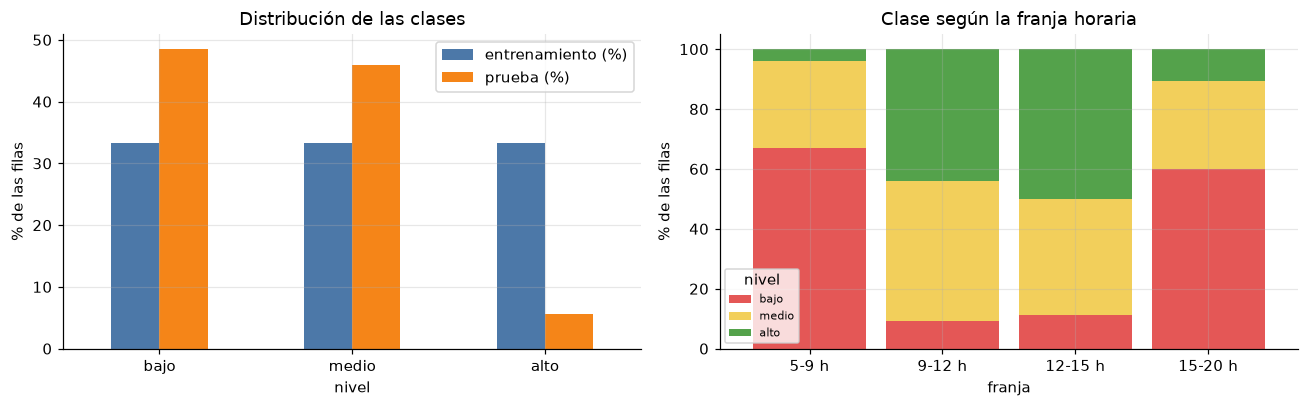

In [43]:
todo = pd.concat([train.assign(conjunto='entrenamiento'), test.assign(conjunto='prueba')])
todo['franja'] = pd.cut(todo.hora, [5, 9, 12, 15, 20], right=False, labels=['5-9 h', '9-12 h', '12-15 h', '15-20 h'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
tabla_cl[['entrenamiento (%)', 'prueba (%)']].plot.bar(ax=ax[0], color=['#4c78a8', '#f58518'], rot=0)
ax[0].set_ylabel('% de las filas'); ax[0].set_title('Distribución de las clases')
ct = pd.crosstab(todo.franja, todo.nivel, normalize='index')[orden_n] * 100
ct.plot.bar(stacked=True, ax=ax[1], color=['#e45756', '#f2cf5b', '#54a24b'], rot=0, width=.85)
ax[1].set_ylabel('% de las filas'); ax[1].set_title('Clase según la franja horaria'); ax[1].legend(title='nivel', fontsize=7)
fig.tight_layout(); fig.savefig('figuras/f3_clases.png', dpi=200, bbox_inches='tight'); plt.show()
mayor = DummyClassifier(strategy='most_frequent').fit(train[['hora']], train.nivel.astype(str)).predict(train[['hora']].head(1))[0]

Las clases quedan equilibradas en entrenamiento (por construcción) y desbalanceadas en prueba: los últimos días son más nublados y los cortes vienen de días más soleados, así que hay menos alto y más bajo. La clase alto tiene pocas filas en prueba y su F1 será inestable; por eso se reportan métricas por clase y F1 macro. El `DummyClassifier` desempata alfabéticamente cuando las tres clases están empatadas, por eso predice una clase que no es la más común en prueba.

### 3.3.3 Cómo entra la hora
La hora en bruto casi no se relaciona linealmente con la potencia (2.3.6) porque la curva diaria es una campana. Se comparan tres formas de usarla con dos modelos sencillos (solo hora y rezagos de potencia) y validación cruzada temporal: `hora` en bruto, `dist_mediodia` (distancia a la hora de máxima potencia media del entrenamiento) y `hora_sen_cos` (seno y coseno del ciclo de 24 h).

In [44]:
NIVEL_A_INT = {'bajo': 0, 'medio': 1, 'alto': 2}; ETIQ = ['bajo', 'medio', 'alto']
H_PICO = train.groupby('hora').AC_PLANTA_KW.mean().idxmax()          # hora de máxima potencia media, solo entrenamiento
def agregar_hora(df):
    df = df.copy()
    df['dist_mediodia'] = (df['hora'] - H_PICO).abs()
    df['hora_sin'] = np.sin(2 * np.pi * df['hora'] / 24); df['hora_cos'] = np.cos(2 * np.pi * df['hora'] / 24)
    return df
train, test = agregar_hora(train), agregar_hora(test)
HV = {'hora': ['hora'], 'dist_mediodia': ['dist_mediodia'], 'hora_sen_cos': ['hora_sin', 'hora_cos']}
ytr = train.nivel.astype(str).map(NIVEL_A_INT).to_numpy(); yte = test.nivel.astype(str).map(NIVEL_A_INT).to_numpy()
cv = TimeSeriesSplit(n_splits=5)
print(f'Hora de máxima potencia media en entrenamiento: {H_PICO:.2f} h | filas train {len(train)}, test {len(test)}')

def metricas(y, p):
    pr, rc, f, _ = precision_recall_fscore_support(y, p, labels=[0, 1, 2], zero_division=0)
    return {'accuracy': accuracy_score(y, p), 'f1_macro': f1_score(y, p, labels=[0, 1, 2], average='macro', zero_division=0),
            'kappa': cohen_kappa_score(y, p), 'f1_bajo': f[0], 'f1_medio': f[1], 'f1_alto': f[2],
            'prec_bajo': pr[0], 'prec_medio': pr[1], 'prec_alto': pr[2], 'rec_bajo': rc[0], 'rec_medio': rc[1], 'rec_alto': rc[2]}

def prec_bajo(y, p, energia):
    """Métrica de negocio: de las veces que se dijo 'bajo' (clase 0), cuántas lo era, y la energía de los falsos 'bajo'."""
    dijo, es = (p == 0), (y == 0)
    tp, n_dijo, n_real = int((dijo & es).sum()), int(dijo.sum()), int(es.sum())
    return {'veces que dijo bajo': n_dijo, 'precisión de bajo': tp / n_dijo if n_dijo else np.nan,
            'recall de bajo (ventanas aprovechadas)': tp / n_real if n_real else np.nan,
            'falsos bajo': n_dijo - tp, 'MWh en falsos bajo (cota)': energia[dijo & ~es].sum() * 0.25 / 1000,
            'MWh en falsos bajo (1 inversor)': energia[dijo & ~es].sum() * 0.25 / 1000 / N_INV,
            'MWh en todos los instantes dichos bajo': energia[dijo].sum() * 0.25 / 1000}

Hora de máxima potencia media en entrenamiento: 12.25 h | filas train 1275, test 340


In [45]:
filas = []
for hv, cols_h in HV.items():
    X = train[cols_h + LAGS_POTENCIA]
    for nombre, est in [('Logística (C=1)', Pipeline([('esc', StandardScaler()), ('m', LogisticRegression(max_iter=5000))])),
                        ('Árbol (prof. 6)', DecisionTreeClassifier(max_depth=6, random_state=SEMILLA))]:
        s = cross_val_score(est, X, ytr, cv=cv, scoring='f1_macro')
        filas.append({'forma de la hora': hv, 'modelo': nombre, 'F1 macro (CV)': s.mean(), 'desv.': s.std()})
tab_hora = pd.DataFrame(filas); display(tab_hora.round(3))
resumen_hora = tab_hora.groupby('forma de la hora')['F1 macro (CV)'].mean().sort_values(ascending=False)
print('F1 macro (CV) promedio de ambos modelos:', resumen_hora.round(3).to_dict())
print('Forma con mayor F1 macro (CV) promedio:', resumen_hora.index[0])

,forma de la hora,modelo,F1 macro (CV),desv.
0,hora,Logística (C=1),0.752,0.071
1,hora,Árbol (prof. 6),0.737,0.085
2,dist_mediodia,Logística (C=1),0.753,0.071
3,dist_mediodia,Árbol (prof. 6),0.743,0.090
4,hora_sen_cos,Logística (C=1),0.764,0.082
5,hora_sen_cos,Árbol (prof. 6),0.725,0.096


F1 macro (CV) promedio de ambos modelos: {'dist_mediodia': 0.748, 'hora': 0.745, 'hora_sen_cos': 0.745}
Forma con mayor F1 macro (CV) promedio: dist_mediodia


Las tres formas dan resultados muy parecidos (las diferencias son menores que la desviación entre pliegues): la hora aporta poco una vez que se conocen los rezagos de potencia. No se encontró en la bibliografía una recomendación que decida entre las tres formas, así que la elección es del equipo y se apoya en esta comparación: se usa la forma con mayor F1 macro promedio, sabiendo que la ventaja es pequeña.

In [46]:
HORA_VAR = resumen_hora.index[0]     # forma de la hora con mayor F1 macro (CV) promedio (decisión 3.3.3)
HORA_ELEGIDA = HORA_VAR
print('Forma de la hora usada:', HORA_ELEGIDA)

Forma de la hora usada: dist_mediodia


### 3.3.4 Conjuntos de variables A, B y C
Para responder si el clima reciente aporta algo más que la historia de la potencia se arman tres conjuntos, todos con la hora y solo con información de t - 1 o antes: A = historia de la potencia (rezagos de `AC_PLANTA_KW`); B = clima reciente del sensor (rezagos de irradiancia y temperaturas); C = ambos.

In [47]:
def cols_conjunto(conj, lags=LAGS, hv=None):
    hcols = HV[hv or HORA_ELEGIDA]
    pot = [f'AC_PLANTA_KW_lag{p}' for p in lags]
    sen_ = [f'{c}_lag{p}' for c in COLS_SENSOR for p in lags]
    return {'A': hcols + pot, 'B': hcols + sen_, 'C': hcols + pot + sen_}[conj]
print({k: len(cols_conjunto(k)) for k in 'ABC'}, '| C =', cols_conjunto('C'))

{'A': 4, 'B': 10, 'C': 13} | C = ['dist_mediodia', 'AC_PLANTA_KW_lag1', 'AC_PLANTA_KW_lag2', 'AC_PLANTA_KW_lag4', 'AMBIENT_TEMPERATURE_lag1', 'AMBIENT_TEMPERATURE_lag2', 'AMBIENT_TEMPERATURE_lag4', 'MODULE_TEMPERATURE_lag1', 'MODULE_TEMPERATURE_lag2', 'MODULE_TEMPERATURE_lag4', 'IRRADIATION_lag1', 'IRRADIATION_lag2', 'IRRADIATION_lag4']


### 3.3.5 Verificación de la construcción
Se comprueba que no haya vacíos inesperados, que los rezagos sean los de la hora correcta en filas de ejemplo, que los cortes salgan solo del entrenamiento y que la prueba sea posterior.

In [48]:
cols_chk = cols_conjunto('C')
assert not train[cols_chk].isna().any().any() and not test[cols_chk].isna().any().any(), 'hay vacíos en los predictores'
assert train.DATE_TIME.max() < test.DATE_TIME.min(), 'la prueba debe ser posterior al entrenamiento'
assert np.allclose([float(train.AC_PLANTA_KW.quantile(q)) for q in (1 / 3, 2 / 3)], cortes), 'los cortes deben salir solo de entrenamiento'
serie_chk = D.set_index('DATE_TIME').AC_PLANTA_KW; ejemplo = train.sample(3, random_state=SEMILLA)
for t_, fila in ejemplo.iterrows():
    for p_ in LAGS:
        esperado = serie_chk.get(fila.DATE_TIME - pd.Timedelta(minutes=15 * p_), np.nan)
        assert np.isclose(fila[f'AC_PLANTA_KW_lag{p_}'], esperado), f'rezago {p_} incorrecto en {fila.DATE_TIME}'
display(ejemplo[['DATE_TIME', 'AC_PLANTA_KW', 'AC_PLANTA_KW_lag1', 'AC_PLANTA_KW_lag2', 'AC_PLANTA_KW_lag4']].round(0))
print(f'OK: sin vacíos en los predictores, rezagos correctos en 3 filas de ejemplo, cortes {cortes[0]:.0f} y {cortes[1]:.0f} kW, prueba posterior al entrenamiento.')
print(f'Filas: entrenamiento {len(train)}, prueba {len(test)}; clases en entrenamiento: {train.nivel.value_counts().to_dict()}')

C:\Users\migu3\AppData\Local\Temp\ipykernel_27696\3100009694.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ejemplo[['DATE_TIME', 'AC_PLANTA_KW', 'AC_PLANTA_KW_lag1', 'AC_PLANTA_KW_lag2', 'AC_PLANTA_KW_lag4']].round(0))


,DATE_TIME,AC_PLANTA_KW,AC_PLANTA_KW_lag1,AC_PLANTA_KW_lag2,AC_PLANTA_KW_lag4
2375,2020-06-08 17:45:00,4601.0,5498.0,6043.0,8961.0
719,2020-05-22 11:45:00,17805.0,17726.0,17432.0,17026.0
1312,2020-05-28 16:00:00,13997.0,15856.0,17463.0,19984.0


OK: sin vacíos en los predictores, rezagos correctos en 3 filas de ejemplo, cortes 9043 y 15466 kW, prueba posterior al entrenamiento.
Filas: entrenamiento 1275, prueba 340; clases en entrenamiento: {'bajo': 425, 'medio': 425, 'alto': 425}


Las tres comprobaciones pasan, y las filas de ejemplo muestran lo esperado en una serie con memoria: los rezagos se alejan del valor actual a medida que se retrocede en el tiempo (el de 15 minutos es el más parecido y el de una hora el más distinto), sin saltos raros que delaten un desfase al construirlos.

### 3.3.6 El dataset final: distribución, entrenamiento frente a prueba
Con el dataset corregido se repiten dos gráficos de la fase 2 (ahora con la potencia corregida y los días marcados como entrenamiento o prueba) y se calculan las correlaciones con los predictores, que alimentan el informe.

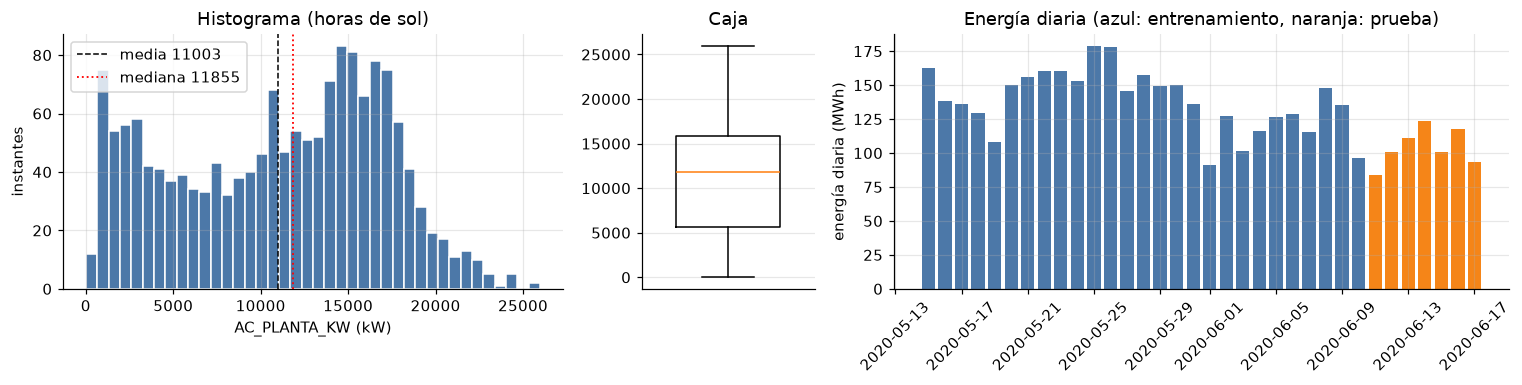

In [49]:
e_dia = D.groupby('fecha').AC_PLANTA_KW.sum() * 0.25 / 1000      # MWh
h_dia = D.groupby('fecha').IRRADIATION.sum() * 0.25              # kWh/m2
es_tr = e_dia.index.isin(dias_train)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={'width_ratios': [1.3, .45, 1.6]})
ax[0].hist(ds.AC_PLANTA_KW, bins=40, color='#4c78a8', edgecolor='white')
ax[0].axvline(ds.AC_PLANTA_KW.mean(), color='k', ls='--', lw=1, label=f'media {ds.AC_PLANTA_KW.mean():.0f}')
ax[0].axvline(ds.AC_PLANTA_KW.median(), color='r', ls=':', lw=1.2, label=f'mediana {ds.AC_PLANTA_KW.median():.0f}')
ax[0].set_xlabel('AC_PLANTA_KW (kW)'); ax[0].set_ylabel('instantes'); ax[0].legend(); ax[0].set_title('Histograma (horas de sol)')
ax[1].boxplot(ds.AC_PLANTA_KW, widths=.6); ax[1].set_xticks([]); ax[1].set_title('Caja')
ax[2].bar(e_dia.index, e_dia, color=np.where(es_tr, '#4c78a8', '#f58518'))
ax[2].set_ylabel('energía diaria (MWh)'); ax[2].set_title('Energía diaria (azul: entrenamiento, naranja: prueba)'); ax[2].tick_params(axis='x', rotation=45)
fig.tight_layout(); fig.savefig('figuras/f3_distribucion_energia.png', dpi=200, bbox_inches='tight'); plt.show()

rend = (e_dia / h_dia)

El gráfico deja ver con claridad el costo de la partición cronológica: los siete días de prueba (naranja) tienen una energía diaria media claramente menor que la de entrenamiento (unos 105 MWh frente a 138) y también menos irradiación (4,0 frente a 6,0 kWh/m² al día). Es decir, el modelo se evalúa en una semana más nublada que las que vio. Eso explica que en la prueba haya menos instantes de nivel alto y que no deba leerse como un fallo del modelo. Otro detalle interesante es que los días de menor energía no son los de menor rendimiento (energía por unidad de irradiación): el 11-06, el de menor energía, simplemente fue nublado, mientras que el 07-06 y el 06-06 rinden poco para la irradiación que reciben, y eso apunta a pérdidas operativas (inversores desconectados) más que a clima.

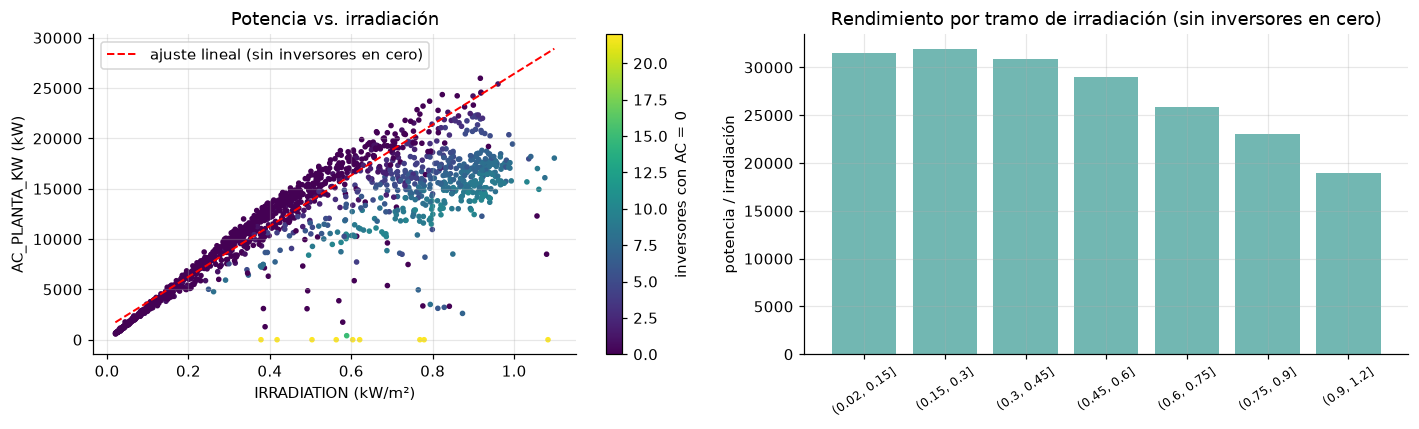

,instantes,kW por kW/m²,temp. módulo media (°C)
tramo,,,
"(0.02, 0.15]",243.0,31456.8,27.7
"(0.15, 0.3]",182.0,31881.6,33.1
"(0.3, 0.45]",201.0,30905.1,36.6
"(0.45, 0.6]",106.0,28992.1,41.6
"(0.6, 0.75]",42.0,25858.1,46.7
"(0.75, 0.9]",15.0,23006.3,49.9
"(0.9, 1.2]",5.0,19005.2,53.9


In [50]:
limpio = ds[(ds.n_inv_cero == 0) & (ds.n_inv == N_INV)]
c_all = np.polyfit(ds.IRRADIATION, ds.AC_PLANTA_KW, 1); c_lim = np.polyfit(limpio.IRRADIATION, limpio.AC_PLANTA_KW, 1)   # pendiente (kW por kW/m²) e intercepto

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sc = ax[0].scatter(ds.IRRADIATION, ds.AC_PLANTA_KW, c=ds.n_inv_cero, s=7, cmap='viridis')
xs = np.linspace(ds.IRRADIATION.min(), ds.IRRADIATION.max(), 50)
ax[0].plot(xs, np.polyval(c_lim, xs), 'r--', lw=1.3, label='ajuste lineal (sin inversores en cero)')
ax[0].set_xlabel('IRRADIATION (kW/m²)'); ax[0].set_ylabel('AC_PLANTA_KW (kW)'); ax[0].legend()
fig.colorbar(sc, ax=ax[0], label='inversores con AC = 0'); ax[0].set_title('Potencia vs. irradiación')
tr = limpio.copy(); tr['tramo'] = pd.cut(tr.IRRADIATION, [UMBRAL_IRR, .15, .3, .45, .6, .75, .9, 1.2])
loc = tr.groupby('tramo', observed=True).apply(lambda g: pd.Series({'instantes': len(g), 'kW por kW/m²': (g.AC_PLANTA_KW / g.IRRADIATION).mean(),
                                                                  'temp. módulo media (°C)': g.MODULE_TEMPERATURE.mean()}), include_groups=False)
ax[1].bar(range(len(loc)), loc['kW por kW/m²'], color='#72b7b2'); ax[1].set_xticks(range(len(loc)))
ax[1].set_xticklabels([str(i) for i in loc.index], rotation=35, fontsize=8)
ax[1].set_ylabel('potencia / irradiación'); ax[1].set_title('Rendimiento por tramo de irradiación (sin inversores en cero)')
fig.tight_layout(); fig.savefig('figuras/f3_potencia_vs_irradiacion.png', dpi=200, bbox_inches='tight'); plt.show()
display(loc.round(1))
caida_obs = 100 * (1 - loc['kW por kW/m²'].iloc[-1] / loc['kW por kW/m²'].iloc[0])
caida_temp = 0.4 * (loc['temp. módulo media (°C)'].iloc[-1] - loc['temp. módulo media (°C)'].iloc[0])

La relación entre potencia e irradiación es fuerte pero no lineal: el rendimiento por kW/m² cae cerca de 40 % del tramo de menos sol al de más sol, mientras que el efecto de la temperatura del módulo (alrededor de 0,4 % por grado) explicaría solo cerca de 10 %. Queda una diferencia grande sin explicar con estos datos; es probable que parte sea el recorte de potencia de los inversores cuando los paneles producen más de lo que pueden convertir y parte la suciedad o los inversores en cero. En el panel izquierdo, de hecho, los instantes con inversores en cero (en color) quedan sistemáticamente por debajo de la tendencia. Para el pronóstico esto significa que la irradiación sola no basta y que la potencia reciente, que ya incluye todos esos efectos, es mejor predictor.

In [51]:
cp = ds[PREDICTORES + ['AC_PLANTA_KW']].corr()['AC_PLANTA_KW'].drop('AC_PLANTA_KW').sort_values(ascending=False)

Con la potencia ya corregida, el predictor más fuerte, la potencia de hace 15 minutos, alcanza una correlación cercana a 0,89; le siguen la irradiación y la potencia de hace 30 minutos, alrededor de 0,8. La hora sigue sin correlación lineal (-0,02) por la forma de campana de la curva diaria, lo que confirma que habrá que transformarla. Un hallazgo curioso es que los inversores en cero aparecen más cuando hay más sol (correlación de 0,68 con la irradiación): las desconexiones no parecen ocurrir al azar sino ligadas a las horas de mayor generación, por protecciones o sobrecarga quizá, una hipótesis que estos datos no permiten verificar. Y la temperatura del módulo y la irradiación casi se solapan (0,91), de modo que los coeficientes de la regresión logística deben interpretarse con cuidado.

## 3.4 Integrar los datos
La generación (22 inversores) y el sensor se unen por `DATE_TIME` sobre la malla completa de instantes de 15 min (`construir_malla`): los instantes ausentes quedan como filas vacías en lugar de desaparecer, así los rezagos por fecha son correctos. La verificación está en el embudo de 3.2.5 (filas por paso) y en 3.3.5.

## 3.5 Dar formato a los datos
El orden temporal se conserva en todas las particiones; el escalado va dentro de un `Pipeline` (se ajusta solo con entrenamiento en cada pliegue, sin fuga) y todas las variables son numéricas. Los modelos basados en árboles no necesitan escalado.

## 3.6 Cierre de la fase

| Elemento | Resultado | Dónde se ve |
|---|---|---|
| Decisiones de limpieza | Cada una con su evidencia y su alternativa analizada | 3.1 y 3.2 |
| Variable objetivo | Construida sin usar información de prueba | 3.3.2 y 3.3.5 |
| Predictores | Todos se conocen a tiempo | 3.1.3 |
| Partición | Cronológica por días | 3.1.4 |
| Formato | Orden temporal conservado, escalado dentro del `Pipeline`, variables numéricas | 3.5 |

El dataset queda listo para el modelado.

<a id="fase4"></a>
# Fase 4: Modelado
El modelado es iterativo: se prueba, se mira qué pasó y se vuelve a probar. Se reportan todos los modelos entrenados, no solo el ganador [16]: una sola competencia de 17 candidatos, líneas base que cualquier modelo debe superar, una regla de selección fijada con el entrenamiento y, al final, un ensamble. El orden de la fase: técnicas (4.1), diseño de la comprobación y líneas base (4.2), competencia y modelo individual (4.3), ensamble (4.4) y K-Means de días (4.5).

## 4.1 Seleccionar las técnicas de modelado
### 4.1.1 Los 17 candidatos
Los seis modelos de partida (regresión logística, KNN, árbol, bosque aleatorio, HistGradientBoosting y XGBoost) ya están dentro de los 17, así que no se presentan como una ronda aparte. Cada técnica se incluye por una razón: cubrir las familias que usa la literatura de pronóstico fotovoltaico [14] y dar al ensamble miembros de tipos distintos (ver 4.4.2) [16].

| Familia | Modelo | Cómo decide | Qué requiere |
|---|---|---|---|
| Lineales | Regresión logística (L2) | Combinación lineal de las variables que se convierte en probabilidad por clase | Escalado; pocas variables |
| | LR L1, LR ElasticNet | Igual, con penalización que descarta variables poco útiles | Escalado; rejilla del peso de la penalización |
| | LR con interacciones | Agrega productos entre pares de variables | Escalado; penalización fuerte por la cantidad de columnas |
| | LR balanceada | Pesa más a la clase pequeña | Escalado |
| | LR ordinal (Frank y Hall) | Aprovecha que bajo < medio < alto: dos logísticas para "mayor que bajo" y "mayor que medio" | Escalado |
| | LDA | Frontera lineal suponiendo clases gaussianas con la misma covarianza | Escalado; encogimiento de covarianza |
| | SVM lineal calibrada | Frontera lineal de margen máximo con puntajes convertidos en probabilidades | Escalado; calibración |
| Árboles, boosting y vecinos | Árbol | Preguntas de sí o no hasta llegar a una clase; fácil de leer | Profundidad máxima |
| | Bosque aleatorio (RF) | Promedia muchos árboles entrenados con muestras distintas | Sin escalado; 200 a 300 árboles |
| | HistGradientBoosting, XGBoost | Árboles pequeños en secuencia, cada uno corrige al anterior | Sin escalado; tasa de aprendizaje |
| | KNN | Vota entre los K instantes de entrenamiento más parecidos | Escalado; K |
| Con agrupamiento | LR + K-Means (k = 6) | Agrega a las variables la distancia a 6 grupos de instantes (K-Means solo con entrenamiento) | Escalado |
| | LR + mezcla gaussiana | Agrega la probabilidad de pertenecer a cada componente de una mezcla gaussiana | Escalado |
| | K-Means por grupos | Agrupa los instantes y predice la frecuencia de cada nivel en el grupo | Número de grupos |
| | Mezcla gaussiana por clase | Una mezcla gaussiana por nivel y regla de Bayes | Número de componentes |

### 4.1.2 Supuestos del modelado
(1) El comportamiento de la planta es estable durante el mes de datos. (2) Los rezagos de la última hora bastan para anunciar el nivel de los próximos 15 minutos. (3) Las clases salen de cuantiles fijos del entrenamiento y no cambian al evaluar. (4) Los hiperparámetros se eligen solo con el entrenamiento.

### 4.1.3 Definición de los candidatos y sus rejillas
Los seis modelos de partida usan una rejilla de hiperparámetros propia y los once restantes la de las pruebas de apoyo del Anexo B. Algunas clases propias (`OrdinalLogit`, `ClusterProb`, `GMMPorClase`, `ClusterAug`, `DistanciasKMeans`, `XGBSeguro`) implementan las ideas de arriba con la interfaz de `scikit-learn`.

In [52]:
class OrdinalLogit(BaseEstimator, ClassifierMixin):
    """Regresión logística ordinal (Frank y Hall): una logística para P(nivel > bajo) y otra para P(nivel > medio)."""
    def __init__(self, C=1.0):
        self.C = C
    def _ajustar(self, X, z):
        return float(z[0]) if len(np.unique(z)) < 2 else LogisticRegression(C=self.C, max_iter=5000).fit(X, z)
    def fit(self, X, y):
        y = np.asarray(y); self.classes_ = np.array([0, 1, 2])
        self.m1_, self.m2_ = self._ajustar(X, (y > 0).astype(int)), self._ajustar(X, (y > 1).astype(int)); return self
    def _g(self, m, X):
        return np.full(len(X), m) if isinstance(m, float) else m.predict_proba(X)[:, 1]
    def predict_proba(self, X):
        g1 = self._g(self.m1_, X); g2 = np.minimum(self._g(self.m2_, X), g1)
        return np.c_[1 - g1, g1 - g2, g2]
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

class ClusterProb(BaseEstimator, ClassifierMixin):
    """Agrupa los instantes con K-Means (solo con sus variables de entrada) y predice la frecuencia de cada nivel dentro del grupo."""
    def __init__(self, k=12, alpha=1.0):
        self.k, self.alpha = k, alpha
    def fit(self, X, y):
        y = np.asarray(y).astype(int); self.classes_ = np.array([0, 1, 2])
        self.esc_ = StandardScaler().fit(X); Z = self.esc_.transform(X)
        self.km_ = KMeans(n_clusters=min(self.k, len(Z)), n_init=5, random_state=SEMILLA).fit(Z)
        prior = np.bincount(y, minlength=3) + 1.0; prior = prior / prior.sum()
        T = np.zeros((self.km_.n_clusters, 3))
        for c_, l_ in zip(self.km_.labels_, y): T[c_, l_] += 1
        self.T_ = (T + 3 * self.alpha * prior) / (T.sum(1, keepdims=True) + 3 * self.alpha)   # suavizado hacia la frecuencia global
        return self
    def predict_proba(self, X):
        return self.T_[self.km_.predict(self.esc_.transform(X))]
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

class GMMPorClase(BaseEstimator, ClassifierMixin):
    """Clasificador generativo: una mezcla gaussiana por nivel y regla de Bayes."""
    def __init__(self, n_comp=2, reg=1e-2):
        self.n_comp, self.reg = n_comp, reg
    def fit(self, X, y):
        y = np.asarray(y).astype(int); self.classes_ = np.array([0, 1, 2])
        self.esc_ = StandardScaler().fit(X); Z = self.esc_.transform(X); self.g_, self.lp_ = {}, np.full(3, -np.inf)
        for c_ in range(3):
            Zc = Z[y == c_]
            if len(Zc) >= 5:
                self.g_[c_] = GaussianMixture(min(self.n_comp, max(1, len(Zc) // 20)), covariance_type='diag', reg_covar=self.reg, random_state=SEMILLA).fit(Zc)
                self.lp_[c_] = np.log(len(Zc) / len(Z))
        return self
    def predict_proba(self, X):
        Z = self.esc_.transform(X); ll = np.full((len(Z), 3), -np.inf)
        for c_, g_ in self.g_.items(): ll[:, c_] = g_.score_samples(Z) + self.lp_[c_]
        ll -= ll.max(axis=1, keepdims=True); p_ = np.exp(ll); return p_ / p_.sum(axis=1, keepdims=True)
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

class ClusterAug(BaseEstimator, TransformerMixin):
    """Agrega a las variables (ya escaladas) la distancia a cada centro de K-Means o la probabilidad de cada componente de una mezcla gaussiana."""
    def __init__(self, k=6, modo='kmeans'):
        self.k, self.modo = k, modo
    def fit(self, X, y=None):
        self.m_ = (KMeans(n_clusters=self.k, n_init=5, random_state=SEMILLA).fit(X) if self.modo == 'kmeans' else
                   GaussianMixture(self.k, covariance_type='diag', reg_covar=1e-2, random_state=SEMILLA).fit(X))
        return self
    def transform(self, X):
        return np.c_[X, self.m_.transform(X) if self.modo == 'kmeans' else self.m_.predict_proba(X)]

class XGBSeguro(BaseEstimator, ClassifierMixin):
    """XGBoost que tolera que falte alguna clase en el entrenamiento (días iniciales de la evaluación día a día)."""
    def __init__(self, max_depth=3, learning_rate=0.1, n_estimators=100):
        self.max_depth, self.learning_rate, self.n_estimators = max_depth, learning_rate, n_estimators
    def fit(self, X, y):
        y = np.asarray(y).astype(int); self.classes_ = np.array([0, 1, 2]); self.pres_ = np.unique(y)
        if len(self.pres_) < 2:
            self.m_ = None; return self
        self.m_ = XGBClassifier(max_depth=self.max_depth, learning_rate=self.learning_rate, n_estimators=self.n_estimators, random_state=SEMILLA,
                                eval_metric='mlogloss', n_jobs=1).fit(X, np.searchsorted(self.pres_, y)); return self
    def predict_proba(self, X):
        P = np.zeros((len(X), 3))
        if self.m_ is None:
            P[:, self.pres_[0]] = 1; return P
        P[:, self.pres_] = self.m_.predict_proba(X); return P
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

class DistanciasKMeans(BaseEstimator, TransformerMixin):
    """Agrega a las variables (ya escaladas) la distancia de cada instante a los k centros de un K-Means ajustado solo con el entrenamiento."""
    def __init__(self, k=6):
        self.k = k
    def fit(self, X, y=None):
        self.m_ = KMeans(n_clusters=self.k, n_init=5, random_state=SEMILLA).fit(X); return self
    def transform(self, X):
        return np.c_[X, self.m_.transform(X)]


def modelos_y_rejillas():
    return {
        'Regresión logística': (Pipeline([('esc', StandardScaler()), ('m', LogisticRegression(max_iter=5000))]), {'m__C': [0.01, 0.1, 1, 10, 100]}),
        'KNN': (Pipeline([('esc', StandardScaler()), ('m', KNeighborsClassifier())]),
                {'m__n_neighbors': list(range(1, 52, 2)), 'm__weights': ['uniform', 'distance']}),
        'Árbol': (DecisionTreeClassifier(random_state=SEMILLA), {'max_depth': list(range(2, 13)), 'min_samples_leaf': [1, 5, 10, 20]}),
        'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=SEMILLA), {'max_depth': [4, 6, 8, None], 'min_samples_leaf': [1, 5]}),
        'HistGradientBoosting': (HistGradientBoostingClassifier(random_state=SEMILLA),
                                 {'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'max_iter': [100, 200]}),
        'XGBoost': (XGBClassifier(random_state=SEMILLA, eval_metric='mlogloss', n_jobs=1),
                    {'max_depth': [3, 5], 'learning_rate': [0.05, 0.1], 'n_estimators': [100, 300]}),
    }


def modelos_nuevos():
    """Los 11 candidatos adicionales: variantes de la logística, LDA, SVM y modelos con agrupamiento."""
    esc = lambda: ('esc', StandardScaler())
    lr = lambda **kw: LogisticRegression(max_iter=5000, **kw)
    return {
        'LR L1': (Pipeline([esc(), ('m', lr(l1_ratio=1, solver='saga'))]), {'m__C': [0.01, 0.1, 1, 10]}),
        'LR ElasticNet': (Pipeline([esc(), ('m', lr(solver='saga'))]), {'m__C': [0.1, 1, 10], 'm__l1_ratio': [0.25, 0.5, 0.75]}),
        'LR interacciones': (Pipeline([esc(), ('poly', PolynomialFeatures(2, interaction_only=True, include_bias=False)), ('esc2', StandardScaler()), ('m', lr())]),
                             {'m__C': [0.0005, 0.002, 0.01, 0.05]}),
        'LR balanceada': (Pipeline([esc(), ('m', lr(class_weight='balanced'))]), {'m__C': [0.01, 0.1, 1, 10]}),
        'LR ordinal': (Pipeline([esc(), ('m', OrdinalLogit())]), {'m__C': [0.01, 0.1, 1, 10]}),
        'LDA': (Pipeline([esc(), ('m', LinearDiscriminantAnalysis(solver='lsqr'))]), {'m__shrinkage': ['auto', 0.1, 0.5]}),
        'SVM lineal calibrada': (Pipeline([esc(), ('m', CalibratedClassifierCV(LinearSVC(max_iter=20000), cv=3))]), {'m__estimator__C': [0.01, 0.1, 1]}),
        'LR + K-Means (k=6)': (Pipeline([esc(), ('cl', ClusterAug(6, 'kmeans')), ('m', lr())]), {'m__C': [0.01, 0.1, 1, 10]}),
        'LR + mezcla gaussiana': (Pipeline([esc(), ('cl', ClusterAug(4, 'gmm')), ('m', lr())]), {'m__C': [0.01, 0.1, 1, 10]}),
        'K-Means por grupos': (ClusterProb(), {'k': [8, 16, 32]}),
        'Mezcla gaussiana por clase': (GMMPorClase(), {'n_comp': [1, 2, 3]}),
    }

COMPETIDORES = {**modelos_y_rejillas(), **modelos_nuevos()}
FAMILIA = {**{n: 'Lineales' for n in ['Regresión logística', 'LR L1', 'LR ElasticNet', 'LR interacciones', 'LR balanceada', 'LR ordinal', 'LDA', 'SVM lineal calibrada']},
           **{n: 'Árboles, boosting y vecinos' for n in ['Árbol', 'Random Forest', 'HistGradientBoosting', 'XGBoost', 'KNN']},
           **{n: 'Con agrupamiento' for n in ['LR + K-Means (k=6)', 'LR + mezcla gaussiana', 'K-Means por grupos', 'Mezcla gaussiana por clase']}}
assert set(FAMILIA) == set(COMPETIDORES) and len(COMPETIDORES) == 17
print(f'{len(COMPETIDORES)} candidatos:', ', '.join(COMPETIDORES))

17 candidatos: Regresión logística, KNN, Árbol, Random Forest, HistGradientBoosting, XGBoost, LR L1, LR ElasticNet, LR interacciones, LR balanceada, LR ordinal, LDA, SVM lineal calibrada, LR + K-Means (k=6), LR + mezcla gaussiana, K-Means por grupos, Mezcla gaussiana por clase


## 4.2 Diseñar la comprobación
### 4.2.1 Diseño
- Partición: entrenamiento y prueba cronológicos (3.1.4). Los hiperparámetros se eligen dentro del entrenamiento con `TimeSeriesSplit(5)` y F1 macro; la prueba se usa una vez para informar.
- Evaluación día a día (walk-forward): para cada día desde el día `WF_DIA_INICIO` se reconstruye todo con los días anteriores (corrección de inversores, terciles, climatología, hiperparámetros) y se predice solo ese día; así hay muchos días de prueba y no siete. Los días anteriores a `WF_DIA_CONFIRMACION` se llaman desarrollo (sirven para ver qué funciona) y los siguientes confirmación (sobre ellos se apoyan las conclusiones). Los intervalos de 95 % salen de un bootstrap que remuestrea días completos, no filas, porque instantes seguidos son casi copias [10].
- Valores elegidos (supuesto del equipo): empezar a predecir en el día 15 (índice 14, con 14 días de historia, cerca del 40 % del mes) y separar desarrollo y confirmación en el día 21 (índice 20), de modo que haya 6 días de desarrollo y 14 de confirmación; 2000 remuestreos del bootstrap. Son supuestos: no hay una regla en la bibliografía para elegirlos.

In [53]:
WF_DIA_INICIO = 14               # primer día que se predice (índice desde 0); los anteriores solo entrenan (supuesto del equipo, 4.2.1)
WF_DIA_CONFIRMACION = 20         # antes de este día: desarrollo; desde este: confirmación (supuesto del equipo, 4.2.1)
N_BOOT = 2000                    # remuestreos de días para los intervalos de 95 % (supuesto del equipo, 4.2.1)
EJECUTAR_WALK_FORWARD = True     # el walk-forward de 5.1.2 tarda unos minutos
def _cm(y, p):
    cm_ = np.zeros((3, 3), int)
    for r_, q_ in zip(y, p): cm_[int(r_), int(q_)] += 1
    return cm_

def _met_cm(cm_):
    cm_ = np.asarray(cm_, float); tot = cm_.sum(); tp = np.diag(cm_)
    pr = np.divide(tp, cm_.sum(0), out=np.zeros(3), where=cm_.sum(0) > 0); rc = np.divide(tp, cm_.sum(1), out=np.zeros(3), where=cm_.sum(1) > 0)
    f = np.divide(2 * pr * rc, pr + rc, out=np.zeros(3), where=(pr + rc) > 0); po = tp.sum() / tot; pe = (cm_.sum(0) * cm_.sum(1)).sum() / tot ** 2
    return {'exactitud': po, 'F1 macro': f.mean(), 'kappa': (po - pe) / (1 - pe), 'precisión de bajo': pr[0], 'recall de bajo': rc[0],
            'veces que dijo bajo': int(cm_[:, 0].sum()), 'falsos bajo': int(cm_[1:, 0].sum())}

### 4.2.2 Líneas base
Antes de probar modelos se mide qué tan bien se puede hacer con algo trivial. Un modelo solo se justifica si supera estas referencias [16]: la clase más frecuente; la persistencia (decir que el nivel va a ser el mismo de hace 15 minutos), que es la referencia seria; la climatología por hora (la mediana de la potencia a esa hora en los días de entrenamiento, que solo conoce el reloj) y la combinación persistencia-climatología $w\cdot P_{t-1}+(1-w)\cdot\text{clim}(h)$ con $w$ estimado con el entrenamiento, que es la referencia que propone la literatura de pronóstico solar [14].

In [54]:
lineas_base = []
# DummyClassifier con las etiquetas de texto, con tres clases empatadas desempata alfabéticamente
dum = DummyClassifier(strategy='most_frequent').fit(train[PREDICTORES], train.nivel.astype(str))
pd_ = lambda df: dum.predict(df[PREDICTORES]).astype(str)
CLASE_DUMMY = pd_(train)[0]
lineas_base.append({'modelo': f'Clase más frecuente (empate: {CLASE_DUMMY})', 'conjunto': '-',
                    **{f'train_{k}': v for k, v in metricas(ytr, pd.Series(pd_(train)).map(NIVEL_A_INT).to_numpy()).items()},
                    **{f'test_{k}': v for k, v in metricas(yte, pd.Series(pd_(test)).map(NIVEL_A_INT).to_numpy()).items()}})
MAYORITARIA_TEST = test.nivel.astype(str).value_counts().idxmax()          # referencia: la clase más común en prueba
lineas_base.append({'modelo': f'Siempre "{MAYORITARIA_TEST}" (la más común en prueba)', 'conjunto': '-',
                    **{f'train_{k}': v for k, v in metricas(ytr, np.full(len(ytr), NIVEL_A_INT[MAYORITARIA_TEST])).items()},
                    **{f'test_{k}': v for k, v in metricas(yte, np.full(len(yte), NIVEL_A_INT[MAYORITARIA_TEST])).items()}})
def persistencia(df):
    return pd.cut(df['AC_PLANTA_KW_lag1'], bins=[-np.inf] + cortes + [np.inf], labels=[0, 1, 2]).astype(int).to_numpy()
lineas_base.append({'modelo': 'Persistencia de la clase', 'conjunto': '-', **{f'train_{k}': v for k, v in metricas(ytr, persistencia(train)).items()},
                    **{f'test_{k}': v for k, v in metricas(yte, persistencia(test)).items()}})
base_df = pd.DataFrame(lineas_base); display(base_df.round(3)[['modelo', 'train_f1_macro', 'test_accuracy', 'test_f1_macro', 'test_f1_bajo', 'test_f1_medio', 'test_f1_alto']])

,modelo,train_f1_macro,test_accuracy,test_f1_macro,test_f1_bajo,test_f1_medio,test_f1_alto
0,Clase más frecuente (empate: alto),0.167,0.056,0.035,0.000,0.000,0.106
1,"Siempre ""bajo"" (la más común en prueba)",0.167,0.485,0.218,0.653,0.000,0.000
2,Persistencia de la clase,0.794,0.756,0.657,0.812,0.737,0.421


In [55]:
def curva_climatologica(df_ref):
    """Mediana de la potencia por hora (solo con df_ref), interpolada a cualquier hora."""
    med = df_ref.groupby('hora').AC_PLANTA_KW.median()
    return lambda h: np.interp(h, med.index.to_numpy(), med.to_numpy())

def peso_convexo(df, clim):
    """w en [0, 1] de la combinación w * persistencia + (1 - w) * climatología, por mínimos cuadrados con el entrenamiento."""
    a, c_, y = df['AC_PLANTA_KW_lag1'].to_numpy(), clim(df['hora'].to_numpy()), df['AC_PLANTA_KW'].to_numpy()
    return float(np.clip(np.sum((y - c_) * (a - c_)) / np.sum((a - c_) ** 2), 0, 1))

clim_tr = curva_climatologica(train); w_conv = peso_convexo(train, clim_tr)
a_clase = lambda x: np.digitize(x, cortes, right=True)
c_te, a_te = clim_tr(test['hora'].to_numpy()), test['AC_PLANTA_KW_lag1'].to_numpy()
pred_clim, pred_conv = a_clase(c_te), a_clase(w_conv * a_te + (1 - w_conv) * c_te)
filas_cb = [{'modelo': n_, **{f'test_{k}': v for k, v in metricas(yte, p_).items()}} for n_, p_ in
            [('Climatología por hora', pred_clim), (f'Combinación persistencia-climatología (w = {w_conv:.2f})', pred_conv)]]
display(pd.DataFrame(filas_cb)[['modelo', 'test_accuracy', 'test_f1_macro', 'test_kappa', 'test_prec_bajo', 'test_rec_bajo']].round(3))
print('Líneas base de clasificación en prueba: persistencia', round(base_df.loc[2, 'test_f1_macro'], 3), '| climatología', round(filas_cb[0]['test_f1_macro'], 3), '| combinación', round(filas_cb[1]['test_f1_macro'], 3), '(F1 macro).')

,modelo,test_accuracy,test_f1_macro,test_kappa,test_prec_bajo,test_rec_bajo
0,Climatología por hora,0.479,0.442,0.256,0.958,0.552
1,Combinación persistencia-climatología (w = 0.73),0.779,0.670,0.603,0.901,0.770


Líneas base de clasificación en prueba: persistencia 0.657 | climatología 0.442 | combinación 0.67 (F1 macro).


Las líneas base ya enseñan cuánto cuesta ganarle a lo simple. Decir siempre la clase más frecuente da un F1 macro cercano a cero, y la climatología por hora sola, que solo conoce el reloj, apenas llega a 0,44: saber qué hora es, sin saber qué está pasando, no sirve. La persistencia, en cambio, es sorprendentemente fuerte (F1 macro de 0,66 y exactitud de 0,76) porque a 15 minutos el nivel casi no cambia. Lo más interesante es la combinación de las dos: mezclar 73 % de lo último que pasó con 27 % de lo típico de esa hora sube el F1 macro a 0,67 y la precisión de bajo a 0,90 (frente a 0,81 de la persistencia). Esa es la vara real que debe superar cualquier modelo, y ya anticipa que habrá poco margen.

Líneas base en kW. Mismo ejercicio con RMSE y MAE: persistencia, regresión lineal simple y lineal múltiple con los conjuntos A, B y C. La habilidad es $1-\text{RMSE}_{modelo}/\text{RMSE}_{persistencia}$: mayor que 0 mejora a la persistencia.

In [56]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
ytr_kw, yte_kw = train.AC_PLANTA_KW.to_numpy(), test.AC_PLANTA_KW.to_numpy()
filas_reg = []
def evaluar_reg(nombre, real, pred, cols=''):
    filas_reg.append({'modelo': nombre, 'predictores': cols, 'RMSE (kW)': float(np.sqrt(mean_squared_error(real, pred))), 'MAE (kW)': float(mean_absolute_error(real, pred))})
evaluar_reg('Persistencia (potencia de hace 15 min)', yte_kw, test.AC_PLANTA_KW_lag1.to_numpy(), 'AC_PLANTA_KW_lag1')
simple = LinearRegression().fit(train[['IRRADIATION_lag1']], ytr_kw)
evaluar_reg('Lineal simple', yte_kw, simple.predict(test[['IRRADIATION_lag1']]), 'IRRADIATION_lag1')
for conj_, etiqueta_ in [('A', 'solo historia de la potencia'), ('B', 'solo clima (sensor)'), ('C', 'historia + clima')]:
    cols_ = cols_conjunto(conj_)
    m_ = Pipeline([('esc', StandardScaler()), ('m', LinearRegression())]).fit(train[cols_], ytr_kw)
    evaluar_reg(f'Lineal múltiple, conjunto {conj_} ({etiqueta_})', yte_kw, m_.predict(test[cols_]), conj_)
    if conj_ == 'C':
        lineal_C, cols_lineal_C = m_, cols_
tabla_reg = pd.DataFrame(filas_reg).set_index('modelo')
tabla_reg['habilidad'] = 1 - tabla_reg['RMSE (kW)'] / tabla_reg['RMSE (kW)'].iloc[0]
display(tabla_reg.round(3))
print(f'Lineal simple: la planta entrega {simple.coef_[0]:,.0f} kW por cada kW/m² de irradiación de hace 15 min (intercepto {simple.intercept_:,.0f} kW).')
hab = tabla_reg['habilidad']
# residuos del lineal múltiple C en la prueba (se miran en el tiempo)
res_C = yte_kw - lineal_C.predict(test[cols_lineal_C])
print(f'Residuos del lineal múltiple C en prueba: media {res_C.mean():,.0f} kW | autocorrelación en el rezago 1: {pd.Series(res_C).autocorr(lag=1):.2f} (banda de significancia: más o menos {1.96 / np.sqrt(len(res_C)):.2f})')

,predictores,RMSE (kW),MAE (kW),habilidad
modelo,,,,
Persistencia (potencia de hace 15 min),AC_PLANTA_KW_lag1,3256.126,2303.831,0.000
Lineal simple,IRRADIATION_lag1,3712.636,2906.341,-0.140
"Lineal múltiple, conjunto A (solo historia de la potencia)",A,3090.976,2185.339,0.051
"Lineal múltiple, conjunto B (solo clima (sensor))",B,3663.476,2742.691,-0.125
"Lineal múltiple, conjunto C (historia + clima)",C,3085.774,2211.502,0.052


Lineal simple: la planta entrega 16,440 kW por cada kW/m² de irradiación de hace 15 min (intercepto 3,379 kW).
Residuos del lineal múltiple C en prueba: media -740 kW | autocorrelación en el rezago 1: -0.21 (banda de significancia: más o menos 0.11)


En kilovatios el resultado es coherente con lo anterior: ningún modelo lineal mejora de forma importante a la persistencia (la mejor habilidad es de apenas 5 %, con la historia de la potencia sola o junto con el clima), y los que usan solo el sensor quedan peor que ella (habilidad negativa). Es otra forma de ver lo mismo: lo que hará la planta en los próximos 15 minutos se parece sobre todo a lo que hizo hace 15 minutos.

### 4.2.3 Métricas
- F1 macro: promedio del F1 de las tres clases; castiga fallar en la clase pequeña (alto).
- kappa de Cohen: acierto descontando lo que se acertaría por azar con las proporciones de cada clase (0 = no sabe más que el azar, 1 = perfecto).
- Precisión de bajo: de las veces que el modelo dijo bajo, cuántas era bajo. Es la métrica de negocio: un falso bajo hace intervenir con la planta produciendo.
- Recall de bajo: de las ventanas realmente bajas, cuántas detectó (cuántas ventanas de mantenimiento se aprovechan).
- En kW: RMSE, MAE y habilidad frente a la persistencia. Las fórmulas están en 1.3.2.

### 4.2.4 Regla de selección del modelo individual
Solo se elige un modelo si aprovecha al menos el 70 % de las ventanas bajas (sin ese mínimo ganaría un modelo que casi nunca dice bajo y tendría precisión alta sin servir de nada); los modelos que quedan a menos de 0,01 de la mejor precisión de bajo se consideran empatados y se desempata con el F1 macro de validación. El modelo y el conjunto se eligen con el entrenamiento, no con la prueba: se calculan predicciones fuera de muestra de cada uno con `TimeSeriesSplit(5)`. Ambos valores son supuestos del equipo con razón de negocio: aprovechar 70 % de las ventanas es un mínimo razonable para programar mantenimientos y 0,01 es el tamaño de diferencia que se considera indistinguible con pocos días. En 4.3.3 se ve que con este mínimo todos los ajustes son elegibles.

In [57]:
RECALL_MIN_BAJO = 0.70       # mínimo de ventanas bajas aprovechadas (recall de bajo) para poder elegir un modelo (supuesto del equipo, 4.2.4)
TOL_EMPATE = 0.01            # a menos de esta distancia de la mejor precisión de bajo los modelos se consideran empatados (supuesto del equipo, 4.2.4)

## 4.3 Construir y evaluar los modelos
### 4.3.1 Competencia de los 17 candidatos con los conjuntos A, B y C
Cada candidato se ajusta con cada conjunto de variables (51 ajustes) con `GridSearchCV(cv=TimeSeriesSplit(5), scoring='f1_macro')` dentro del entrenamiento. Se mide en entrenamiento, validación cruzada y prueba, y se anota el tiempo de cada ajuste.

In [58]:
def ajustar(nombre, conj, lags=LAGS):
    est, rejilla = COMPETIDORES[nombre]
    cols = cols_conjunto(conj, lags)
    t0 = time.perf_counter()
    gs = GridSearchCV(est, rejilla, cv=cv, scoring='f1_macro', n_jobs=6, error_score='raise').fit(train[cols], ytr)
    seg = time.perf_counter() - t0
    tr_m, te_m = metricas(ytr, gs.predict(train[cols])), metricas(yte, gs.predict(test[cols]))
    fila = {'modelo': nombre, 'familia': FAMILIA[nombre], 'conjunto': conj, 'cv_f1_macro': gs.best_score_, 'mejores parámetros': {k.replace('m__', ''): v for k, v in gs.best_params_.items()},
            'segundos': seg, **{f'train_{k}': v for k, v in tr_m.items()}, **{f'test_{k}': v for k, v in te_m.items()}}
    return fila, gs.best_estimator_, cols

RES, AJUSTADOS = [], {}
t_ini = time.perf_counter()
for conj in ['A', 'B', 'C']:
    for nombre in COMPETIDORES:
        fila, est, cols = ajustar(nombre, conj)
        RES.append(fila); AJUSTADOS[(nombre, conj)] = (est, cols)
res = pd.DataFrame(RES)
print(f'{len(res)} modelos ajustados en {time.perf_counter() - t_ini:.0f} s (el más lento: {res.sort_values("segundos").iloc[-1].modelo}, {res.segundos.max():.1f} s).')
display(res.pivot(index='modelo', columns='conjunto', values='test_f1_macro').round(3).rename_axis(columns='F1 macro en prueba'))
display(res.pivot(index='modelo', columns='conjunto', values='cv_f1_macro').round(3).rename_axis(columns='F1 macro en validación cruzada'))

51 modelos ajustados en 48 s (el más lento: Random Forest, 6.6 s).


F1 macro en prueba,A,B,C
modelo,,,
HistGradientBoosting,0.649,0.550,0.647
K-Means por grupos,0.549,0.521,0.578
KNN,0.635,0.508,0.550
LDA,0.627,0.504,0.621
LR + K-Means (k=6),0.670,0.525,0.660
LR + mezcla gaussiana,0.656,0.505,0.632
LR ElasticNet,0.638,0.525,0.650
LR L1,0.638,0.524,0.650
LR balanceada,0.638,0.527,0.654


F1 macro en validación cruzada,A,B,C
modelo,,,
HistGradientBoosting,0.749,0.711,0.757
K-Means por grupos,0.703,0.642,0.687
KNN,0.744,0.694,0.734
LDA,0.736,0.684,0.732
LR + K-Means (k=6),0.758,0.709,0.765
LR + mezcla gaussiana,0.757,0.697,0.762
LR ElasticNet,0.761,0.717,0.755
LR L1,0.761,0.715,0.755
LR balanceada,0.761,0.703,0.769


### 4.3.2 Comparación con las líneas base
La tabla pone todos los candidatos del conjunto C junto a las líneas base; después se muestran el aporte del clima reciente por conjunto, el sobreajuste de cada modelo y un mapa de calor del F1 macro.

In [59]:
t_c = res[res.conjunto == 'C'].copy()
t_c = pd.concat([base_df, t_c], ignore_index=True)
cols_t = ['modelo', 'conjunto', 'cv_f1_macro', 'train_f1_macro', 'test_accuracy', 'test_f1_macro', 'test_kappa', 'test_f1_bajo', 'test_f1_medio', 'test_f1_alto']
tabla_modelos = t_c[cols_t].copy(); tabla_modelos['sobreajuste (train−test F1)'] = tabla_modelos.train_f1_macro - tabla_modelos.test_f1_macro
print('Tabla comparativa (conjunto C: hora + rezagos de potencia y del sensor):')
display(tabla_modelos.round(3))

pc = pd.concat([base_df, res[res.conjunto == 'C']], ignore_index=True)
print('Precisión, recall por clase y kappa de Cohen en prueba (kappa 0 = no sabe más que adivinar con las proporciones):')
display(pc[['modelo', 'conjunto', 'test_kappa', 'test_prec_bajo', 'test_rec_bajo', 'test_prec_medio', 'test_rec_medio', 'test_prec_alto', 'test_rec_alto']].round(3))
p1 = res.pivot(index='modelo', columns='conjunto', values='test_f1_macro')
p1['C − A (aporte del clima)'] = p1['C'] - p1['A']
print('F1 macro en prueba por conjunto y diferencia entre usar todo (C) y solo la historia de la potencia (A):')
display(p1.round(3))
mej_A, mej_B, mej_C = (res[res.conjunto == c].test_f1_macro.max() for c in 'ABC')

Tabla comparativa (conjunto C: hora + rezagos de potencia y del sensor):


,modelo,conjunto,cv_f1_macro,train_f1_macro,test_accuracy,test_f1_macro,test_kappa,test_f1_bajo,test_f1_medio,test_f1_alto,sobreajuste (train−test F1)
0,Clase más frecuente (empate: alto),-,NaN,0.167,0.056,0.035,0.000,0.000,0.000,0.106,0.131
1,"Siempre ""bajo"" (la más común en prueba)",-,NaN,0.167,0.485,0.218,0.000,0.653,0.000,0.000,-0.051
2,Persistencia de la clase,-,NaN,0.794,0.756,0.657,0.557,0.812,0.737,0.421,0.137
3,Regresión logística,C,0.751,0.820,0.750,0.622,0.556,0.825,0.742,0.298,0.198
4,KNN,C,0.734,0.830,0.735,0.550,0.524,0.812,0.742,0.098,0.280
5,Árbol,C,0.767,0.823,0.771,0.582,0.575,0.805,0.787,0.154,0.241
6,Random Forest,C,0.770,0.888,0.782,0.652,0.604,0.827,0.787,0.343,0.235
7,HistGradientBoosting,C,0.757,0.889,0.776,0.647,0.600,0.842,0.773,0.326,0.242
8,XGBoost,C,0.754,0.995,0.771,0.630,0.588,0.842,0.764,0.286,0.364
9,LR L1,C,0.755,0.815,0.759,0.650,0.572,0.826,0.749,0.375,0.165


Precisión, recall por clase y kappa de Cohen en prueba (kappa 0 = no sabe más que adivinar con las proporciones):


,modelo,conjunto,test_kappa,test_prec_bajo,test_rec_bajo,test_prec_medio,test_rec_medio,test_prec_alto,test_rec_alto
0,Clase más frecuente (empate: alto),-,0.000,0.000,0.000,0.000,0.000,0.056,1.000
1,"Siempre ""bajo"" (la más común en prueba)",-,0.000,0.485,1.000,0.000,0.000,0.000,0.000
2,Persistencia de la clase,-,0.557,0.812,0.812,0.737,0.737,0.421,0.421
3,Regresión logística,C,0.556,0.867,0.788,0.728,0.756,0.250,0.368
4,KNN,C,0.524,0.858,0.770,0.712,0.776,0.091,0.105
5,Árbol,C,0.575,0.922,0.715,0.693,0.910,0.286,0.105
6,Random Forest,C,0.604,0.894,0.770,0.731,0.853,0.375,0.316
7,HistGradientBoosting,C,0.600,0.897,0.794,0.741,0.808,0.292,0.368
8,XGBoost,C,0.588,0.881,0.806,0.741,0.788,0.261,0.316
9,LR L1,C,0.572,0.862,0.794,0.742,0.756,0.310,0.474


F1 macro en prueba por conjunto y diferencia entre usar todo (C) y solo la historia de la potencia (A):


conjunto,A,B,C,C − A (aporte del clima)
modelo,,,,
HistGradientBoosting,0.649,0.550,0.647,-0.002
K-Means por grupos,0.549,0.521,0.578,0.030
KNN,0.635,0.508,0.550,-0.084
LDA,0.627,0.504,0.621,-0.007
LR + K-Means (k=6),0.670,0.525,0.660,-0.011
LR + mezcla gaussiana,0.656,0.505,0.632,-0.024
LR ElasticNet,0.638,0.525,0.650,0.012
LR L1,0.638,0.524,0.650,0.012
LR balanceada,0.638,0.527,0.654,0.016


In [60]:
sob = res[res.conjunto == 'C'][['modelo', 'train_f1_macro', 'cv_f1_macro', 'test_f1_macro']].copy().set_index('modelo')
sob.columns = ['F1 entrenamiento', 'F1 validación', 'F1 prueba']
sob['distancia entr.−valid.'] = sob['F1 entrenamiento'] - sob['F1 validación']
sob['distancia entr.−prueba'] = sob['F1 entrenamiento'] - sob['F1 prueba']
display(sob.sort_values('distancia entr.−valid.').round(3))
menor, mayor = sob['distancia entr.−valid.'].idxmin(), sob['distancia entr.−valid.'].idxmax()

,F1 entrenamiento,F1 validación,F1 prueba,distancia entr.−valid.,distancia entr.−prueba
modelo,,,,,
Mezcla gaussiana por clase,0.748,0.712,0.486,0.036,0.261
LR balanceada,0.818,0.769,0.654,0.048,0.163
LR + K-Means (k=6),0.814,0.765,0.660,0.049,0.154
LDA,0.785,0.732,0.621,0.053,0.165
LR + mezcla gaussiana,0.817,0.762,0.632,0.055,0.184
Árbol,0.823,0.767,0.582,0.055,0.241
LR L1,0.815,0.755,0.650,0.060,0.165
LR ordinal,0.817,0.756,0.642,0.061,0.175
LR ElasticNet,0.818,0.755,0.650,0.063,0.168


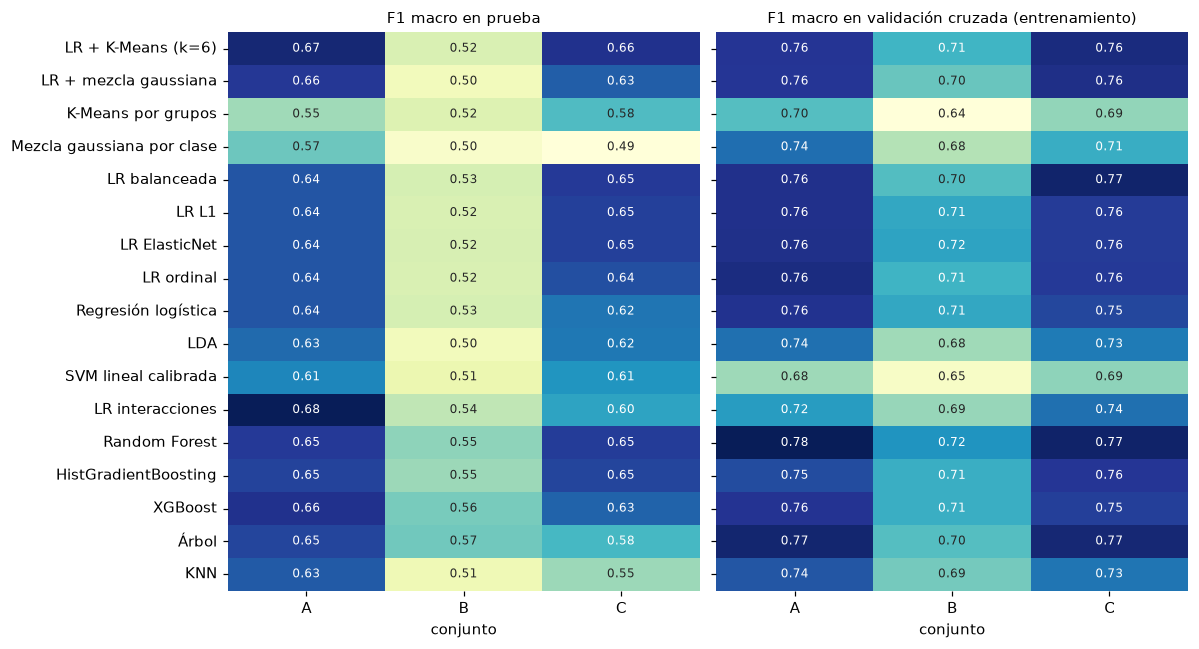

Mejor F1 macro por familia y conjunto:


mejor_prueba               mejor_cv              
conjunto                               A      B      C        A      B      C
familia                                                                      
Con agrupamiento                   0.670  0.525  0.660    0.758  0.709  0.765
Lineales                           0.682  0.538  0.654    0.764  0.717  0.769
Árboles, boosting y vecinos        0.660  0.565  0.652    0.775  0.724  0.770

Persistencia: F1 macro en prueba 0.657 | mejor de los 51 ajustes: 0.682 (LR interacciones, conjunto A).


In [61]:
fig, ax = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
orden_f = res[res.conjunto == 'C'].sort_values(['familia', 'test_f1_macro'], ascending=[True, False]).modelo.tolist()
for a, col, titulo in zip(ax, ['test_f1_macro', 'cv_f1_macro'], ['F1 macro en prueba', 'F1 macro en validación cruzada (entrenamiento)']):
    sns.heatmap(res.pivot(index='modelo', columns='conjunto', values=col).loc[orden_f], annot=True, fmt='.2f', cmap='YlGnBu', cbar=False, ax=a, annot_kws={'size': 8})
    a.set_title(titulo, fontsize=10); a.set_ylabel(''); a.grid(False)
fig.tight_layout(); fig.savefig('figuras/f4_competencia_17.png', dpi=200, bbox_inches='tight'); plt.show()
fam = res.groupby(['familia', 'conjunto']).agg(mejor_prueba=('test_f1_macro', 'max'), mejor_cv=('cv_f1_macro', 'max')).round(3)
print('Mejor F1 macro por familia y conjunto:'); display(fam.unstack('conjunto'))
print(f'Persistencia: F1 macro en prueba {base_df.loc[2, "test_f1_macro"]:.3f} | mejor de los 51 ajustes: {res.test_f1_macro.max():.3f} ({res.loc[res.test_f1_macro.idxmax(), "modelo"]}, conjunto {res.loc[res.test_f1_macro.idxmax(), "conjunto"]}).')

Con siete días de prueba ningún candidato suelto supera con claridad a la persistencia en F1 macro: los mejores la superan por pocos centésimos, dentro de lo que fluctúa de un conjunto a otro (y el mejor de los 51 ajustes lo es en el conjunto A, no en el C). Sí hay diferencias en la precisión de bajo. Agregar el clima reciente (C frente a A) no mejora de forma consistente: la potencia de hace 15 minutos ya trae casi toda la información. Los modelos más flexibles (bosque, boosting, XGBoost) memorizan más el entrenamiento (mayor distancia entre entrenamiento y validación) sin que eso se traduzca en mejores resultados en prueba, y los modelos con agrupamiento puro (K-Means por grupos, mezcla gaussiana por clase) quedan por debajo de los demás.

### 4.3.3 Modelo individual elegido por la regla 4.2.4
Se calculan las predicciones fuera de muestra de cada uno de los 51 ajustes (`TimeSeriesSplit(5)` dentro del entrenamiento), se aplica el mínimo de recall y el empate técnico, y se desempata con el F1 macro de validación. El resultado es el mejor modelo individual; sirve para interpretar y como referencia, no es el modelo final.

In [62]:
MODELO_INDIVIDUAL = None             # None: lo elige la regla de 4.2.4 | (modelo, conjunto) para fijarlo a mano
E_TRAIN = train.AC_PLANTA_KW.to_numpy()
def fuera_de_muestra(est, cols):
    pred = np.full(len(ytr), -1)
    for i_tr, i_va in cv.split(train):
        pred[i_va] = clone(est).fit(train[cols].iloc[i_tr], ytr[i_tr]).predict(train[cols].iloc[i_va])
    ok = pred >= 0                                    # el primer bloque solo se usa para entrenar
    return prec_bajo(ytr[ok], pred[ok], E_TRAIN[ok]), f1_score(ytr[ok], pred[ok], average='macro', zero_division=0)
filas_oof = []
for (nombre, conj), (est, cols) in AJUSTADOS.items():
    m, f1m = fuera_de_muestra(est, cols)
    filas_oof.append({'modelo': nombre, 'conjunto': conj, 'precisión de bajo (VC)': m['precisión de bajo'],
                      'recall de bajo (VC)': m['recall de bajo (ventanas aprovechadas)'], 'veces que dijo bajo': m['veces que dijo bajo'],
                      'falsos bajo': m['falsos bajo'], 'F1 macro (VC)': f1m})
oof = pd.DataFrame(filas_oof)
elegibles = oof[oof['recall de bajo (VC)'] >= RECALL_MIN_BAJO]
print(f'Modelos que aprovechan al menos {RECALL_MIN_BAJO:.0%} de las ventanas bajas en validación: {len(elegibles)} de {len(oof)}')
display(oof.sort_values('precisión de bajo (VC)', ascending=False).round(3).head(8))
if MODELO_INDIVIDUAL is None:
    maxima = elegibles['precisión de bajo (VC)'].max()
    empatados = elegibles[elegibles['precisión de bajo (VC)'] >= maxima - TOL_EMPATE]      # empate técnico con la mejor
    print(f'Mejor precisión de bajo en validación: {maxima:.3f}. Modelos empatados (a menos de {TOL_EMPATE}): {len(empatados)}; se desempata con el F1 macro en validación.')
    mejor = empatados.sort_values('F1 macro (VC)', ascending=False).iloc[0]
    MODELO_INDIVIDUAL = (mejor.modelo, mejor.conjunto)
MEJOR_NOMBRE, MEJOR_CONJ = MODELO_INDIVIDUAL
MEJOR_EST, MEJOR_COLS = AJUSTADOS[MODELO_INDIVIDUAL]
fila_mej = res[(res.modelo == MEJOR_NOMBRE) & (res.conjunto == MEJOR_CONJ)].iloc[0]
pred_arbol = MEJOR_EST.predict(test[MEJOR_COLS])
print(f'Mejor modelo individual: {MEJOR_NOMBRE}, conjunto {MEJOR_CONJ} | parámetros: {fila_mej["mejores parámetros"]}')
print(f'F1 macro: validación cruzada {fila_mej.cv_f1_macro:.3f} | entrenamiento {fila_mej.train_f1_macro:.3f} | prueba {fila_mej.test_f1_macro:.3f}')
print('Ranking por validación cruzada (top 6):')
display(res.sort_values('cv_f1_macro', ascending=False)[['modelo', 'conjunto', 'cv_f1_macro', 'test_f1_macro', 'mejores parámetros']].head(6).round(3))

Modelos que aprovechan al menos 70% de las ventanas bajas en validación: 51 de 51


,modelo,conjunto,precisión de bajo (VC),recall de bajo (VC),veces que dijo bajo,falsos bajo,F1 macro (VC)
42,LR interacciones,C,0.950,0.820,317,16,0.773
19,Árbol,B,0.945,0.798,310,17,0.727
20,Random Forest,B,0.943,0.850,331,19,0.744
35,KNN,C,0.942,0.839,327,19,0.764
1,KNN,A,0.942,0.837,326,19,0.775
26,LR balanceada,B,0.941,0.864,337,20,0.730
37,Random Forest,C,0.940,0.853,333,20,0.806
24,LR ElasticNet,B,0.938,0.872,341,21,0.742


Mejor precisión de bajo en validación: 0.950. Modelos empatados (a menos de 0.01): 7; se desempata con el F1 macro en validación.
Mejor modelo individual: Random Forest, conjunto C | parámetros: {'max_depth': 8, 'min_samples_leaf': 5}
F1 macro: validación cruzada 0.770 | entrenamiento 0.888 | prueba 0.652
Ranking por validación cruzada (top 6):


,modelo,conjunto,cv_f1_macro,test_f1_macro,mejores parámetros
3,Random Forest,A,0.775,0.654,"{'max_depth': 4, 'min_samples_leaf': 5}"
37,Random Forest,C,0.770,0.652,"{'max_depth': 8, 'min_samples_leaf': 5}"
43,LR balanceada,C,0.769,0.654,{'C': 1}
2,Árbol,A,0.769,0.647,"{'max_depth': 3, 'min_samples_leaf': 10}"
36,Árbol,C,0.767,0.582,"{'max_depth': 3, 'min_samples_leaf': 10}"
47,LR + K-Means (k=6),C,0.765,0.660,{'C': 1}


Con el mínimo de recall de 70 % todos los ajustes son elegibles, de modo que la regla se decide por la precisión de bajo en validación y el desempate por F1 macro. Siete modelos quedan empatados técnicamente en el primer puesto y el desempate favorece al bosque aleatorio con el conjunto C. La ampliación cambia el resultado: con solo los seis modelos de partida el elegido era el árbol con el conjunto C, y al ampliar la competencia a 17 candidatos la misma regla elige otro. El árbol se sigue usando para interpretar (4.3.4) y como "árbol individual" de la evaluación día a día (5.1.2), porque es el modelo más fácil de leer.

### 4.3.4 Cómo decide el modelo
Se miran los modelos interpretables: los coeficientes de la regresión logística, las reglas del árbol, la importancia de variables y por qué el árbol queda con profundidad pequeña. Estas gráficas son del conjunto C.

In [63]:
# Regresión logística (conjunto C): coeficientes estandarizados por clase
log_est, log_cols = AJUSTADOS[('Regresión logística', 'C')]
coefs = pd.DataFrame(log_est.named_steps['m'].coef_.T, index=log_cols, columns=ETIQ)
coefs['|efecto| máx.'] = coefs.abs().max(axis=1)
print('Coeficientes estandarizados (efecto de +1 desv. estándar sobre el log-odds de cada clase frente al resto):')
display(coefs.sort_values('|efecto| máx.', ascending=False).round(2).head(10))
print('Colinealidad entre predictores (|r| > 0.9):')
cc = train[log_cols].corr().abs().where(np.triu(np.ones((len(log_cols), len(log_cols))), 1).astype(bool)).stack()
display(cc[cc > .9].sort_values(ascending=False).round(2).rename('|r|').to_frame())

Coeficientes estandarizados (efecto de +1 desv. estándar sobre el log-odds de cada clase frente al resto):


,bajo,medio,alto,|efecto| máx.
AC_PLANTA_KW_lag1,-3.27,-0.27,3.55,3.55
AMBIENT_TEMPERATURE_lag4,1.28,0.92,-2.20,2.20
MODULE_TEMPERATURE_lag2,-0.60,-0.75,1.35,1.35
MODULE_TEMPERATURE_lag1,0.81,0.47,-1.28,1.28
AMBIENT_TEMPERATURE_lag1,-0.75,-0.24,0.99,0.99
IRRADIATION_lag1,-0.75,0.33,0.42,0.75
IRRADIATION_lag2,0.29,0.44,-0.74,0.74
AMBIENT_TEMPERATURE_lag2,-0.03,-0.69,0.72,0.72
dist_mediodia,0.49,-0.00,-0.48,0.49
IRRADIATION_lag4,-0.24,-0.17,0.41,0.41


Colinealidad entre predictores (|r| > 0.9):


|r|
AMBIENT_TEMPERATURE_lag1 AMBIENT_TEMPERATURE_lag2  0.99
AMBIENT_TEMPERATURE_lag2 AMBIENT_TEMPERATURE_lag4  0.98
MODULE_TEMPERATURE_lag1  MODULE_TEMPERATURE_lag2   0.97
AMBIENT_TEMPERATURE_lag1 AMBIENT_TEMPERATURE_lag4  0.97
IRRADIATION_lag1         IRRADIATION_lag2          0.94
MODULE_TEMPERATURE_lag2  MODULE_TEMPERATURE_lag4   0.94
MODULE_TEMPERATURE_lag1  IRRADIATION_lag2          0.93
MODULE_TEMPERATURE_lag4  IRRADIATION_lag4          0.93
MODULE_TEMPERATURE_lag2  IRRADIATION_lag4          0.92
                         IRRADIATION_lag2          0.91
AC_PLANTA_KW_lag1        AC_PLANTA_KW_lag2         0.91
MODULE_TEMPERATURE_lag1  IRRADIATION_lag4          0.91
                         IRRADIATION_lag1          0.91

Parámetros del árbol: {'max_depth': 3, 'min_samples_leaf': 10}
|--- IRRADIATION_lag1 <= 0.29
|   |--- IRRADIATION_lag1 <= 0.21
|   |   |--- IRRADIATION_lag4 <= 0.42
|   |   |   |--- class: 0
|   |   |--- IRRADIATION_lag4 >  0.42
|   |   |   |--- class: 0
|   |--- IRRADIATION_lag1 >  0.21
|   |   |--- MODULE_TEMPERATURE_lag1 <= 34.31
|   |   |   |--- class: 1
|   |   |--- MODULE_TEMPERATURE_lag1 >  34.31
|   |   |   |--- class: 0
|--- IRRADIATION_lag1 >  0.29
|   |--- AC_PLANTA_KW_lag1 <= 15695.67
|   |   |--- AC_PLANTA_KW_lag1 <= 12731.34
|   |   |   |--- class: 1
|   |   |--- AC_PLANTA_KW_lag1 >  12731.34
|   |   |   |--- class: 1
|   |--- AC_PLANTA_KW_lag1 >  15695.67
|   |   |--- IRRADIATION_lag1 <= 0.56
|   |   |   |--- class: 1
|   |   |--- IRRADIATION_lag1 >  0.56
|   |   |   |--- class: 2



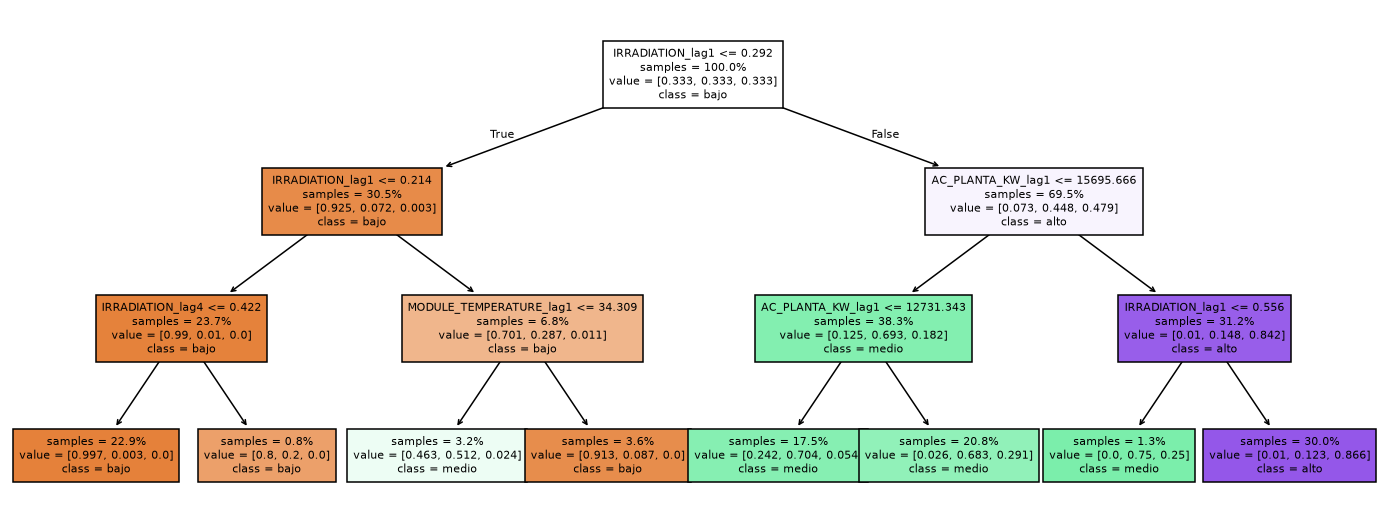

In [64]:
# Árbol de decisión (conjunto C): reglas y sentido físico
arb_est, arb_cols = AJUSTADOS[('Árbol', 'C')]
print('Parámetros del árbol:', res[(res.modelo == 'Árbol') & (res.conjunto == 'C')].iloc[0]['mejores parámetros'])
print(export_text(arb_est, feature_names=arb_cols, max_depth=3))
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(arb_est, feature_names=arb_cols, class_names=ETIQ, max_depth=3, filled=True, fontsize=7, ax=ax, impurity=False, proportion=True)
fig.savefig('figuras/f4_arbol.png', dpi=200, bbox_inches='tight'); plt.show()

,Árbol,Random Forest,XGBoost
IRRADIATION_lag1,0.633,0.203,0.298
AC_PLANTA_KW_lag1,0.349,0.268,0.275
MODULE_TEMPERATURE_lag1,0.017,0.047,0.029
IRRADIATION_lag4,0.001,0.034,0.039
dist_mediodia,0.000,0.124,0.091
AMBIENT_TEMPERATURE_lag1,0.000,0.022,0.039
AC_PLANTA_KW_lag4,0.000,0.031,0.033
AC_PLANTA_KW_lag2,0.000,0.093,0.032
AMBIENT_TEMPERATURE_lag2,0.000,0.021,0.032
MODULE_TEMPERATURE_lag2,0.000,0.023,0.033


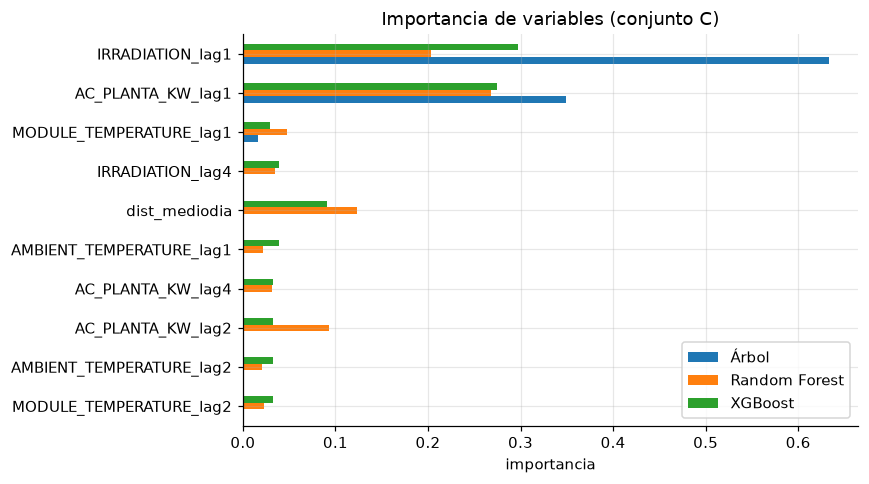

In [65]:
# Importancia de variables: árbol, Random Forest y XGBoost (conjunto C)
imp = pd.DataFrame({'Árbol': AJUSTADOS[('Árbol', 'C')][0].feature_importances_,
                    'Random Forest': AJUSTADOS[('Random Forest', 'C')][0].feature_importances_,
                    'XGBoost': AJUSTADOS[('XGBoost', 'C')][0].feature_importances_,
                    'HistGradientBoosting': np.nan}, index=AJUSTADOS[('Árbol', 'C')][1]).drop(columns='HistGradientBoosting')
imp = imp.sort_values('Árbol', ascending=False)
display(imp.round(3).head(10))
ax = imp.head(10).iloc[::-1].plot.barh(figsize=(8, 4.5)); ax.set_xlabel('importancia'); ax.set_title('Importancia de variables (conjunto C)')
plt.tight_layout(); plt.savefig('figuras/f4_importancias.png', dpi=200, bbox_inches='tight'); plt.show()

profundidad,1,2,3,4,5,6,7,8,9,10,11,12
F1 entrenamiento,0.559,0.820,0.843,0.854,0.862,0.867,0.871,0.873,0.873,0.874,0.874,0.874
F1 validación,0.494,0.757,0.767,0.743,0.743,0.737,0.743,0.742,0.742,0.744,0.745,0.745
distancia,0.065,0.063,0.076,0.110,0.119,0.130,0.128,0.130,0.131,0.130,0.130,0.130


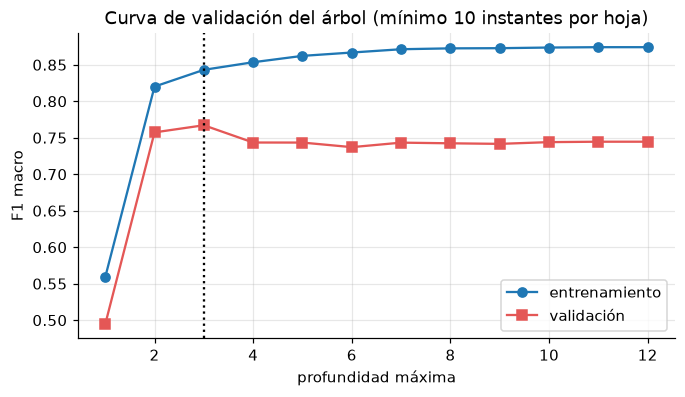

In [66]:
arb_curva, cols_curva = AJUSTADOS[('Árbol', 'C')]
msl = arb_curva.get_params()['min_samples_leaf']; prof_elegida = arb_curva.get_params()['max_depth']
prof = list(range(1, 13))
gs_curva = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA, min_samples_leaf=msl), {'max_depth': prof}, cv=cv, scoring='f1_macro',
                        return_train_score=True, n_jobs=1).fit(train[cols_curva], ytr)
cr = pd.DataFrame(gs_curva.cv_results_)
curva = pd.DataFrame({'profundidad': prof, 'F1 entrenamiento': cr.mean_train_score, 'F1 validación': cr.mean_test_score})
curva['distancia'] = curva['F1 entrenamiento'] - curva['F1 validación']
display(curva.round(3).set_index('profundidad').T)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curva.profundidad, curva['F1 entrenamiento'], 'o-', label='entrenamiento'); ax.plot(curva.profundidad, curva['F1 validación'], 's-', color='#e45756', label='validación')
ax.axvline(prof_elegida, ls=':', c='k'); ax.set_xlabel('profundidad máxima'); ax.set_ylabel('F1 macro'); ax.set_title(f'Curva de validación del árbol (mínimo {msl} instantes por hoja)'); ax.legend()
fig.savefig('figuras/f4_curva_profundidad.png', dpi=200, bbox_inches='tight'); plt.show()
mejor_prof = int(curva.loc[curva['F1 validación'].idxmax(), 'profundidad'])

Las reglas del árbol tienen sentido físico: una irradiancia reciente baja lleva al nivel bajo y una potencia e irradiancia recientes altas, al nivel alto. Las variables más importantes son la potencia y la irradiancia de hace 15 minutos. Con más profundidad el árbol memoriza: el F1 de entrenamiento sube y el de validación deja de mejorar, por eso se queda con profundidad pequeña. La colinealidad entre la temperatura del módulo y la irradiancia (2.3.6) hace que los coeficientes de la logística se interpreten con cautela.

### 4.3.5 Seguimiento de parámetros revisados
La primera prueba (los seis modelos de partida, y luego los 17 candidatos) casi no superó a la persistencia en F1 macro. Por eso se amplió la búsqueda en dos direcciones: una línea base más exigente (climatología y su combinación con la persistencia, 4.2.2) y la combinación de modelos (ensamble), que se prueba en 4.4. Todos los modelos probados quedan reportados en 4.3.1 [16].

## 4.4 El ensamble
### 4.4.0 Variables con climatología y probabilidades de cada modelo
El ensamble recibe las variables del conjunto C más siete variables nuevas que usan la climatología (potencia típica de la hora, cuánto se alejó el último valor de lo normal, cambio entre los dos últimos instantes, etc.); todas se calculan con lo que se conoce un paso antes o con el reloj.

In [67]:
EXTRA_CLIM = ['clim_t', 'd_clim', 'anom1', 'ratio1', 'ramp', 'irr_ramp', 'nz1']   # variables que incorporan la climatología horaria

def agregar_clim(df, clim):
    """Variables con la climatología horaria. Todas usan solo lo que se conoce en t - 1 o el reloj."""
    df = df.copy(); h = df['hora'].to_numpy(); ct, cp = clim(h), clim(h - 0.25)
    df['clim_t'] = ct; df['d_clim'] = ct - cp                              # climatología ahora y cambio esperado
    df['anom1'] = df['AC_PLANTA_KW_lag1'] - cp                              # cuánto se alejó el último valor de lo normal
    df['ratio1'] = np.clip(df['AC_PLANTA_KW_lag1'] / np.maximum(cp, 1.0), 0, 3)
    df['ramp'] = df['AC_PLANTA_KW_lag1'] - df['AC_PLANTA_KW_lag2']
    df['irr_ramp'] = df['IRRADIATION_lag1'] - df['IRRADIATION_lag2']
    df['nz1'] = df['n_inv_cero_lag1'].fillna(0)                             # inversores en cero en el instante anterior
    return df

def probs3(est, X):
    p = est.predict_proba(X); out = np.zeros((len(X), 3))
    for k, c in enumerate(est.classes_): out[:, int(c)] = p[:, k]
    return out

def logit_(p):
    p = np.clip(p, 1e-3, 1 - 1e-3); return np.log(p / (1 - p))

### 4.4.1 Evaluación día a día de los 17 candidatos y combinatoria
Con el procedimiento de 4.2.1 se obtiene, para cada uno de los días desde `WF_DIA_INICIO`, la probabilidad que da cada candidato con rejillas más pequeñas (por costo; las rejillas de los seis de partida se reducen respecto a 4.3.1). Con esas probabilidades se promedian con pesos iguales todos los subconjuntos de 2 a 5 candidatos (9 384 combinaciones) y se evalúan día a día. Las probabilidades se guardan en `figuras/wf_probabilidades.pkl` y se reutilizan; la primera ejecución tarda unos minutos en paralelo.

In [68]:
from threadpoolctl import threadpool_limits
def candidatos_wf():
    """Los 17 candidatos con las rejillas del experimento día a día (más pequeñas que las de 4.3.1 para que el cómputo sea razonable)."""
    esc = lambda: ('esc', StandardScaler())
    nuevos = modelos_nuevos()
    return {
        'LR L2 (base)': (Pipeline([('esc', StandardScaler()), ('m', LogisticRegression(max_iter=5000))]), {'m__C': [0.01, 0.1, 1, 10, 100]}),
        'HGB (base)': (HistGradientBoostingClassifier(random_state=SEMILLA), {'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'max_iter': [100]}),
        'RF (base)': (RandomForestClassifier(n_estimators=200, random_state=SEMILLA), {'max_depth': [4, 8], 'min_samples_leaf': [5]}),
        **{k: v for k, v in nuevos.items()},
        'XGBoost': (XGBSeguro(), {'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}),
        'KNN': (Pipeline([esc(), ('m', KNeighborsClassifier())]), {'m__n_neighbors': [5, 15, 31], 'm__weights': ['uniform', 'distance']}),
        'Árbol': (DecisionTreeClassifier(random_state=SEMILLA), {'max_depth': [3, 5, 8], 'min_samples_leaf': [5, 20]}),
    }
assert len(candidatos_wf()) == 17

def dia_job(j, gen_, sen_, dias_):
    """Reconstruye todo con los días anteriores a j y devuelve las probabilidades de cada candidato para el día j."""
    with threadpool_limits(1):
        warnings.filterwarnings('ignore')
        nd_ = len(dias_)
        ds_j, ctx_j = preparar(gen_, sen_, frac_dias_train=(j + 0.5) / nd_)
        tr_ = ds_j[ds_j.fecha.isin(ctx_j['dias_train'])].sort_values('DATE_TIME').copy()
        te_ = ds_j[ds_j.fecha == dias_[j]].sort_values('DATE_TIME').copy()
        cortes_j = [float(tr_.AC_PLANTA_KW.quantile(q)) for q in (1 / 3, 2 / 3)]
        h_pico_j = tr_.groupby('hora').AC_PLANTA_KW.mean().idxmax()
        for d_ in (tr_, te_): d_['dist_mediodia'] = (d_['hora'] - h_pico_j).abs()
        clim_j = curva_climatologica(tr_); tr_, te_ = agregar_clim(tr_, clim_j), agregar_clim(te_, clim_j)
        y_tr = np.digitize(tr_.AC_PLANTA_KW.to_numpy(), cortes_j, right=True); y_te = np.digitize(te_.AC_PLANTA_KW.to_numpy(), cortes_j, right=True)
        cols = ['dist_mediodia'] + LAGS_POTENCIA + LAGS_SENSOR + EXTRA_CLIM
        w_j = peso_convexo(tr_, clim_j); a_, c_ = te_['AC_PLANTA_KW_lag1'].to_numpy(), clim_j(te_['hora'].to_numpy())
        P = {}
        for nom, (est, rej) in candidatos_wf().items():
            gs = GridSearchCV(clone(est), rej, cv=cv, scoring='f1_macro', n_jobs=1).fit(tr_[cols], y_tr)
            P[nom] = probs3(gs.best_estimator_, te_[cols])
        meta = pd.DataFrame({'dia_idx': j, 'hora': te_['hora'].to_numpy(), 'real': y_te, 'kw': te_['AC_PLANTA_KW'].to_numpy(),
                             'Persistencia': np.digitize(a_, cortes_j, right=True),
                             'Combinación persistencia-climatología': np.digitize(w_j * a_ + (1 - w_j) * c_, cortes_j, right=True)})
        return meta, P

ARCH_PROBS = 'figuras/wf_probabilidades.pkl'
RECALCULAR_PROBS = False         # False: si el archivo existe se carga en lugar de recalcular
if os.path.exists(ARCH_PROBS) and not RECALCULAR_PROBS:
    META, PROB = pickle.load(open(ARCH_PROBS, 'rb')); print('Probabilidades cargadas de', ARCH_PROBS)
else:
    dias_wf = list(range(WF_DIA_INICIO, len(ctx['dias']))); t0 = time.time()
    salidas = joblib.Parallel(n_jobs=12, backend='loky')(joblib.delayed(dia_job)(j, gen, sen, ctx['dias']) for j in dias_wf)
    META = pd.concat([s[0] for s in salidas], ignore_index=True)
    PROB = {nom: np.vstack([s[1][nom] for s in salidas]) for nom in salidas[0][1]}
    pickle.dump((META, PROB), open(ARCH_PROBS, 'wb'))
    print(f'{len(dias_wf)} días x {len(PROB)} candidatos en {time.time() - t0:.0f} s')

DIAS_WF = sorted(META.dia_idx.unique()); DIA_I = META.dia_idx.map({d_: i for i, d_ in enumerate(DIAS_WF)}).to_numpy()
REAL, KW, HORA = META.real.to_numpy(), META.kw.to_numpy(), META.hora.to_numpy()
DES_I = np.array([i for i, d_ in enumerate(DIAS_WF) if d_ < WF_DIA_CONFIRMACION]); CONF_I = np.array([i for i, d_ in enumerate(DIAS_WF) if d_ >= WF_DIA_CONFIRMACION])
print(f'Instantes evaluados: {len(META)} | días de desarrollo: {len(DES_I)} | días de confirmación: {len(CONF_I)} | candidatos: {len(PROB)}')
def cms_por_dia(pred):
    return np.bincount(DIA_I * 9 + REAL * 3 + np.asarray(pred), minlength=len(DIAS_WF) * 9).reshape(len(DIAS_WF), 3, 3)

Probabilidades cargadas de figuras/wf_probabilidades.pkl
Instantes evaluados: 956 | días de desarrollo: 6 | días de confirmación: 14 | candidatos: 17


Cada candidato por separado. Se mide cada uno en los días de desarrollo y de confirmación, junto con la persistencia, la combinación persistencia-climatología y el ensamble previo (regresión logística + HistGradientBoosting + bosque), que fue el primer ensamble que se probó.

,F1 macro (desarrollo),kappa (desarrollo),exactitud (confirmación),F1 macro (confirmación),kappa (confirmación),precisión de bajo (confirmación),recall de bajo (confirmación),falsos bajo (confirmación)
Ensamble previo (LR + HGB + RF),0.755,0.650,0.779,0.678,0.609,0.875,0.799,33.0
LR L2 (base),0.753,0.649,0.771,0.670,0.601,0.860,0.827,39.0
LR + mezcla gaussiana,0.755,0.650,0.771,0.669,0.602,0.863,0.827,38.0
LR balanceada,0.757,0.655,0.773,0.668,0.603,0.860,0.827,39.0
XGBoost,0.747,0.640,0.764,0.667,0.582,0.859,0.782,37.0
LR ElasticNet,0.749,0.644,0.771,0.666,0.600,0.860,0.827,39.0
Combinación persistencia-climatología,0.761,0.654,0.768,0.666,0.593,0.894,0.785,27.0
RF (base),0.762,0.655,0.776,0.665,0.600,0.902,0.768,24.0
LR ordinal,0.750,0.645,0.770,0.665,0.598,0.863,0.827,38.0
LR + K-Means (k=6),0.766,0.670,0.773,0.664,0.599,0.850,0.824,42.0


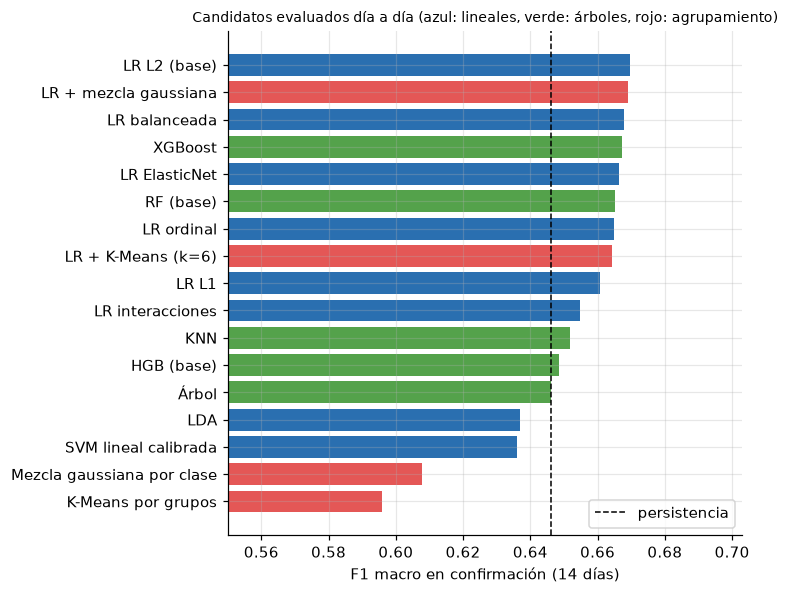

In [69]:
def fila_metricas(cms, idx):
    m = _met_cm(cms[idx].sum(0)); return {k: m[k] for k in ('exactitud', 'F1 macro', 'kappa', 'precisión de bajo', 'recall de bajo', 'falsos bajo')}
PREVIO = ['LR L2 (base)', 'HGB (base)', 'RF (base)']
PRED = {n: PROB[n].argmax(1) for n in PROB}
PRED['Persistencia'] = META['Persistencia'].to_numpy(); PRED['Combinación persistencia-climatología'] = META['Combinación persistencia-climatología'].to_numpy()
PRED['Ensamble previo (LR + HGB + RF)'] = np.mean([PROB[n] for n in PREVIO], axis=0).argmax(1)
CMS = {n: cms_por_dia(p) for n, p in PRED.items()}
t_ind = pd.DataFrame({n: {**{f'{k} (desarrollo)': v for k, v in fila_metricas(c_, DES_I).items() if k in ('F1 macro', 'kappa')},
                          **{f'{k} (confirmación)': v for k, v in fila_metricas(c_, CONF_I).items()}} for n, c_ in CMS.items()}).T.sort_values('F1 macro (confirmación)', ascending=False)
display(t_ind.round(3))
rng_b = np.random.default_rng(SEMILLA); IX_BOOT = rng_b.integers(0, len(CONF_I), (N_BOOT, len(CONF_I)))
def boot_dif(nombre_a, nombre_b, metricas_=('precisión de bajo', 'F1 macro', 'kappa'), idx=None, ix_boot=None):
    idx = CONF_I if idx is None else idx; ix_boot = IX_BOOT if ix_boot is None else ix_boot
    ca, cb = CMS[nombre_a][idx], CMS[nombre_b][idx]; obs_a, obs_b = _met_cm(ca.sum(0)), _met_cm(cb.sum(0)); dif = {k: [] for k in metricas_}
    for ix in ix_boot:
        ma, mb = _met_cm(ca[ix].sum(0)), _met_cm(cb[ix].sum(0))
        for k in metricas_: dif[k].append(ma[k] - mb[k])
    return {k: (obs_a[k] - obs_b[k], np.nanpercentile(dif[k], 2.5), np.nanpercentile(dif[k], 97.5)) for k in metricas_}
fig, ax = plt.subplots(figsize=(7, 5.5))
cand = [n for n in PROB]; vals = [fila_metricas(CMS[n], CONF_I)['F1 macro'] for n in cand]
col_f = {'Lineales': '#2a6fb0', 'Árboles, boosting y vecinos': '#54a24b', 'Con agrupamiento': '#e45756'}
fam_wf = {n: FAMILIA.get(n, FAMILIA.get({'LR L2 (base)': 'Regresión logística', 'HGB (base)': 'HistGradientBoosting', 'RF (base)': 'Random Forest'}.get(n, ''), 'Lineales')) for n in cand}
o_ = np.argsort(vals); ax.barh([cand[i] for i in o_], [vals[i] for i in o_], color=[col_f[fam_wf[cand[i]]] for i in o_])
ax.axvline(fila_metricas(CMS['Persistencia'], CONF_I)['F1 macro'], color='k', ls='--', lw=1, label='persistencia'); ax.set_xlim(.55, None); ax.legend(loc='lower right')
ax.set_xlabel('F1 macro en confirmación (14 días)'); ax.set_title('Candidatos evaluados día a día (azul: lineales, verde: árboles, rojo: agrupamiento)', fontsize=9)
fig.tight_layout(); fig.savefig('figuras/f4_candidatos_dia_a_dia.png', dpi=200, bbox_inches='tight'); plt.show()

Evaluados día a día, los 17 candidatos quedan en una banda muy estrecha: casi todos entre 0,64 y 0,68 de F1 macro en confirmación, con la persistencia en 0,65. Lo llamativo es lo poco que separan a los modelos entre sí, algo que ya se intuía en la competencia de 4.3. Los que se quedan atrás son los más ingenuos (K-Means por grupos y mezcla gaussiana por clase, cerca de 0,60), lo que sugiere que agrupar los instantes sin más no basta; en cambio, usar esos grupos como variables adicionales de una logística sí la deja al nivel de las demás. Este panorama es la razón para probar combinaciones: si ningún modelo se despega, lo que puede aportar es que se equivoquen en momentos distintos.

Combinatoria de ensambles. Con las probabilidades de cada candidato se promedian con pesos iguales todos los subconjuntos de 2 a 5 modelos y se evalúan día a día. Se muestran las 10 mejores en desarrollo (y cómo les fue en confirmación), la mejor de cada tamaño y la relación entre el desempeño en desarrollo y en confirmación.

17 candidatos, 9384 combinaciones de 2 a 5 modelos.
Las 10 mejores combinaciones según los días de DESARROLLO (y cómo les fue en confirmación):


,modelos,tamaño,F1 des,F1 conf,kappa conf,prec bajo conf,recall bajo conf,falsos bajo conf
0,RF (base) + LR L1 + LR balanceada + LR + K-Means (k=6) + K-Means por grupos,5,0.774,0.674,0.615,0.870,0.834,36
1,RF (base) + LR ElasticNet + LR balanceada + LR + K-Means (k=6) + K-Means por grupos,5,0.774,0.677,0.620,0.873,0.834,35
2,RF (base) + LR ElasticNet + Árbol,3,0.774,0.659,0.595,0.891,0.792,28
3,LR L2 (base) + LR ElasticNet + LR balanceada + LDA + LR + K-Means (k=6),5,0.773,0.665,0.598,0.866,0.827,37
4,RF (base) + LR L1 + Árbol,3,0.772,0.665,0.597,0.888,0.792,29
5,HGB (base) + RF (base) + LDA + SVM lineal calibrada + Árbol,5,0.772,0.669,0.608,0.895,0.796,27
6,LR L2 (base) + RF (base) + LR interacciones + LR balanceada + Mezcla gaussiana por clase,5,0.771,0.677,0.608,0.876,0.810,33
7,RF (base) + LR + mezcla gaussiana + XGBoost,3,0.771,0.673,0.606,0.872,0.803,34
8,LR L2 (base) + RF (base) + LR ElasticNet + LR + K-Means (k=6) + K-Means por grupos,5,0.771,0.674,0.612,0.866,0.830,37
9,RF (base) + LR + mezcla gaussiana + Árbol,3,0.770,0.659,0.595,0.888,0.792,29


Mejor combinación de cada tamaño según DESARROLLO:


,modelos,tamaño,F1 des,F1 conf,kappa conf,prec bajo conf,recall bajo conf,falsos bajo conf
0,RF (base) + LR L1 + LR balanceada + LR + K-Means (k=6) + K-Means por grupos,5,0.774,0.674,0.615,0.870,0.834,36
2,RF (base) + LR ElasticNet + Árbol,3,0.774,0.659,0.595,0.891,0.792,28
11,RF (base) + LR + K-Means (k=6),2,0.770,0.688,0.620,0.864,0.817,37
13,HGB (base) + RF (base) + LR + mezcla gaussiana + Árbol,4,0.770,0.667,0.599,0.891,0.789,28


Correlación de Spearman entre desarrollo y confirmación (todas las combinaciones): F1 macro +0.28, kappa +0.27
La mejor en desarrollo queda en el percentil 65 de F1 macro en confirmación.


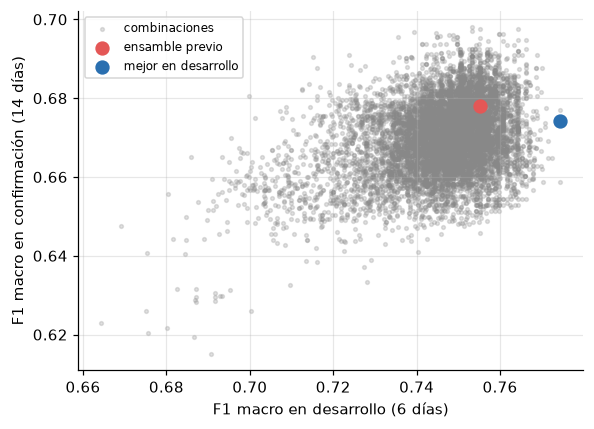

In [70]:
POOL = list(PROB); S = np.stack([PROB[n] for n in POOL])                    # (modelos, instantes, 3)
TAM_MAX = 5
DES2_I = np.array([i for i, d_ in enumerate(DIAS_WF) if d_ < WF_DIA_INICIO + 10]); CONF2_I = np.array([i for i, d_ in enumerate(DIAS_WF) if d_ >= WF_DIA_INICIO + 10])
filas_c = []
for r_ in range(2, TAM_MAX + 1):
    for ix in itertools.combinations(range(len(POOL)), r_):
        cms_ = cms_por_dia(S[list(ix)].mean(0).argmax(1)); md_, mc_, m2d_, m2c_ = (_met_cm(cms_[i].sum(0)) for i in (DES_I, CONF_I, DES2_I, CONF2_I))
        filas_c.append({'comb': ix, 'tamaño': r_, 'F1 des': md_['F1 macro'], 'kappa des': md_['kappa'], 'F1 conf': mc_['F1 macro'], 'kappa conf': mc_['kappa'],
                        'prec bajo conf': mc_['precisión de bajo'], 'recall bajo conf': mc_['recall de bajo'], 'falsos bajo conf': mc_['falsos bajo'],
                        'F1 des2': m2d_['F1 macro'], 'kappa des2': m2d_['kappa'], 'F1 conf2': m2c_['F1 macro'], 'kappa conf2': m2c_['kappa']})
COMB = pd.DataFrame(filas_c); COMB['modelos'] = COMB.comb.map(lambda ix: ' + '.join(POOL[i] for i in ix))
ix_previo = tuple(sorted(POOL.index(n) for n in PREVIO)); fila_previo = COMB[COMB.comb.map(lambda t: t == ix_previo)].iloc[0]
print(f'{len(POOL)} candidatos, {len(COMB)} combinaciones de 2 a {TAM_MAX} modelos.')
orden_des = COMB.sort_values(['F1 des', 'kappa des'], ascending=False).reset_index(drop=True)
cols_t = ['modelos', 'tamaño', 'F1 des', 'F1 conf', 'kappa conf', 'prec bajo conf', 'recall bajo conf', 'falsos bajo conf']
print('Las 10 mejores combinaciones según los días de DESARROLLO (y cómo les fue en confirmación):'); display(orden_des[cols_t].head(10).round(3))
print('Mejor combinación de cada tamaño según DESARROLLO:'); display(orden_des.groupby('tamaño').head(1)[cols_t].round(3))
rho = COMB[['F1 des', 'F1 conf']].corr(method='spearman').iloc[0, 1]; rho_k = COMB[['kappa des', 'kappa conf']].corr(method='spearman').iloc[0, 1]
print(f'Correlación de Spearman entre desarrollo y confirmación (todas las combinaciones): F1 macro {rho:+.2f}, kappa {rho_k:+.2f}')
print(f'La mejor en desarrollo queda en el percentil {100 * (COMB["F1 conf"] <= orden_des.loc[0, "F1 conf"]).mean():.0f} de F1 macro en confirmación.')
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(COMB['F1 des'], COMB['F1 conf'], s=6, alpha=.25, color='#888888', label='combinaciones')
ax.scatter(fila_previo['F1 des'], fila_previo['F1 conf'], s=70, color='#e45756', zorder=3, label='ensamble previo')
ax.scatter(orden_des.loc[0, 'F1 des'], orden_des.loc[0, 'F1 conf'], s=70, color='#2a6fb0', zorder=3, label='mejor en desarrollo')
ax.set_xlabel('F1 macro en desarrollo (6 días)'); ax.set_ylabel('F1 macro en confirmación (14 días)'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('figuras/f4_combinatoria_dev_conf.png', dpi=200, bbox_inches='tight'); plt.show()
COMB.drop(columns=['comb']).to_csv('figuras/res_combinatoria.csv', index=False, encoding='utf-8-sig')

La nube de puntos es probablemente la gráfica más instructiva del modelado. Si el desempeño en los 6 días de desarrollo predijera el de los 14 de confirmación, los puntos formarían una diagonal; en cambio forman una nube dispersa (correlación de Spearman de apenas 0,28). La combinación que gana en desarrollo cae en el percentil 65 en confirmación, es decir, un lugar bastante normal: con tan pocos días, el primer puesto entre 9 384 combinaciones es en buena medida suerte. Esa es la advertencia de fondo sobre el sesgo de selección, y la razón por la que en lo que sigue no se confía en un solo ranking.

Regla fijada de antemano y qué pasó. La regla que se fijó antes de ver los resultados fue: elegir la mejor combinación en desarrollo y reemplazar el ensamble previo solo si mejora en confirmación, con un intervalo que excluya 0 en F1 macro o kappa y sin empeorar la precisión de bajo. Se aplica a continuación.

In [71]:
elegida = orden_des.iloc[0]; nombre_elegida = f'Elegida: {elegida["modelos"]}'
PRED[nombre_elegida] = S[list(elegida.comb)].mean(0).argmax(1); CMS[nombre_elegida] = cms_por_dia(PRED[nombre_elegida])
filas_dec = []
for ref_ in ('Ensamble previo (LR + HGB + RF)', 'Persistencia', 'Combinación persistencia-climatología'):
    for k, (d_, lo, hi) in boot_dif(nombre_elegida, ref_, ('precisión de bajo', 'recall de bajo', 'F1 macro', 'kappa')).items():
        filas_dec.append({'elegida frente a': ref_, 'métrica': k, 'diferencia': d_, 'IC95 inferior': lo, 'IC95 superior': hi, 'el IC excluye 0': (lo > 0) or (hi < 0)})
t_dec = pd.DataFrame(filas_dec); display(t_dec.round(3))
v_ = t_dec[t_dec['elegida frente a'] == 'Ensamble previo (LR + HGB + RF)'].set_index('métrica')
mejora = bool(v_.loc['F1 macro', 'IC95 inferior'] > 0 or v_.loc['kappa', 'IC95 inferior'] > 0); no_peor_prec = bool(v_.loc['precisión de bajo', 'IC95 superior'] >= 0)
print(f'Combinación elegida en desarrollo: {elegida["modelos"]}')
print(f'Regla: mejora al ensamble previo con IC que excluye 0 en F1 macro o kappa -> {mejora}; no empeora la precisión de bajo -> {no_peor_prec}.')

,elegida frente a,métrica,diferencia,IC95 inferior,IC95 superior,el IC excluye 0
0,Ensamble previo (LR + HGB + RF),precisión de bajo,-0.005,-0.017,0.008,False
1,Ensamble previo (LR + HGB + RF),recall de bajo,0.035,0.020,0.050,True
2,Ensamble previo (LR + HGB + RF),F1 macro,-0.004,-0.029,0.017,False
3,Ensamble previo (LR + HGB + RF),kappa,0.006,-0.014,0.027,False
4,Persistencia,precisión de bajo,0.064,0.037,0.092,True
5,Persistencia,recall de bajo,0.028,0.004,0.051,True
6,Persistencia,F1 macro,0.028,0.006,0.047,True
7,Persistencia,kappa,0.070,0.047,0.094,True
8,Combinación persistencia-climatología,precisión de bajo,-0.024,-0.058,0.014,False
9,Combinación persistencia-climatología,recall de bajo,0.048,0.027,0.070,True


Combinación elegida en desarrollo: RF (base) + LR L1 + LR balanceada + LR + K-Means (k=6) + K-Means por grupos
Regla: mejora al ensamble previo con IC que excluye 0 en F1 macro o kappa -> False; no empeora la precisión de bajo -> True.


¿Generaliza la búsqueda? Selección anidada. Con 6 días de desarrollo el primer puesto entre 9 384 combinaciones es casi azar. Para medir el procedimiento completo (buscar entre miles de combinaciones) y no una combinación escogida mirando la respuesta, se parten los días en bloques: para cada bloque se elige la mejor combinación con los demás días y se evalúa en el bloque que no se usó; cada día se evalúa una sola vez [10]. Después se buscan las combinaciones que quedan arriba a la vez en las cuatro evaluaciones (6 días de desarrollo, 14 de confirmación, primeros 10 días y últimos 10).

In [72]:
SUBS = [ix for r_ in range(2, TAM_MAX + 1) for ix in itertools.combinations(range(len(POOL)), r_)]
CM_SUB = np.array([cms_por_dia(S[list(ix)].mean(0).argmax(1)) for ix in SUBS])                  # (combinaciones, días, 3, 3)
REF_CM = {n: CMS[n] for n in ('Ensamble previo (LR + HGB + RF)', 'Persistencia', 'Combinación persistencia-climatología')}
def f1_macro_vec(cm_sum):
    tp = np.einsum('sii->si', cm_sum); pr = tp / np.maximum(cm_sum.sum(1), 1); rc = tp / np.maximum(cm_sum.sum(2), 1)
    return (2 * pr * rc / np.maximum(pr + rc, 1e-12)).mean(1)
ND_ = len(DIAS_WF); filas_a, ELEGIDAS = [], {}
for nb_ in (5, 4, 10):
    por_dia_el = np.zeros((ND_, 3, 3)); nombres_el = []
    for b_ in np.array_split(np.arange(ND_), nb_):
        resto_ = np.setdiff1d(np.arange(ND_), b_); k_ = int(np.argmax(f1_macro_vec(CM_SUB[:, resto_].sum(1))))
        por_dia_el[b_] = CM_SUB[k_][b_]; nombres_el.append(' + '.join(POOL[i] for i in SUBS[k_]))
    ELEGIDAS[nb_] = nombres_el; obs = _met_cm(por_dia_el.sum(0))
    ix_a = np.random.default_rng(SEMILLA).integers(0, ND_, (N_BOOT, ND_))
    for ref_n, ref_c in REF_CM.items():
        oref = _met_cm(ref_c.sum(0)); dif = {m: [] for m in ('precisión de bajo', 'recall de bajo', 'F1 macro', 'kappa')}
        for ix in ix_a:
            a_, r_ = _met_cm(por_dia_el[ix].sum(0)), _met_cm(ref_c[ix].sum(0))
            for m in dif: dif[m].append(a_[m] - r_[m])
        for m, v in dif.items():
            filas_a.append({'bloques': nb_, 'frente a': ref_n, 'métrica': m, 'procedimiento': obs[m], 'referencia': oref[m], 'diferencia': obs[m] - oref[m],
                            'IC95 inferior': np.percentile(v, 2.5), 'IC95 superior': np.percentile(v, 97.5), 'el IC excluye 0': (np.percentile(v, 2.5) > 0) or (np.percentile(v, 97.5) < 0)})
t_anid = pd.DataFrame(filas_a); t_anid.to_csv('figuras/res_seleccion_anidada.csv', index=False, encoding='utf-8-sig')
print('Selección anidada, 5 bloques de 4 días (el procedimiento elige con los demás días y se evalúa en el bloque no usado):'); display(t_anid[t_anid.bloques == 5].round(3))
print('Con 4 y con 10 bloques (diferencias frente al ensamble previo):'); display(t_anid[(t_anid.bloques != 5) & (t_anid['frente a'].str.startswith('Ensamble previo'))].round(3))
print('Combinación que eligió cada bloque (5 bloques):'); [print(f'  bloque {i + 1}: {n}') for i, n in enumerate(ELEGIDAS[5])]
pc = lambda s: s.rank(pct=True)
COMB['consistencia'] = np.minimum.reduce([pc(COMB['F1 des']), pc(COMB['F1 conf']), pc(COMB['F1 des2']), pc(COMB['F1 conf2'])])
print('\nLas 8 combinaciones más consistentes (mínimo percentil de F1 macro en las cuatro evaluaciones):'); display(COMB.sort_values('consistencia', ascending=False)[cols_t + ['consistencia']].head(8).round(3))

Selección anidada, 5 bloques de 4 días (el procedimiento elige con los demás días y se evalúa en el bloque no usado):


,bloques,frente a,métrica,procedimiento,referencia,diferencia,IC95 inferior,IC95 superior,el IC excluye 0
0,5,Ensamble previo (LR + HGB + RF),precisión de bajo,0.888,0.889,-0.001,-0.017,0.012,False
1,5,Ensamble previo (LR + HGB + RF),recall de bajo,0.839,0.813,0.026,0.011,0.042,True
2,5,Ensamble previo (LR + HGB + RF),F1 macro,0.740,0.729,0.011,-0.001,0.022,False
3,5,Ensamble previo (LR + HGB + RF),kappa,0.650,0.630,0.020,0.004,0.034,True
4,5,Persistencia,precisión de bajo,0.888,0.825,0.062,0.042,0.084,True
5,5,Persistencia,recall de bajo,0.839,0.825,0.014,-0.005,0.034,False
6,5,Persistencia,F1 macro,0.740,0.707,0.034,0.018,0.050,True
7,5,Persistencia,kappa,0.650,0.583,0.067,0.044,0.091,True
8,5,Combinación persistencia-climatología,precisión de bajo,0.888,0.910,-0.023,-0.052,0.011,False
9,5,Combinación persistencia-climatología,recall de bajo,0.839,0.792,0.047,0.029,0.063,True


Con 4 y con 10 bloques (diferencias frente al ensamble previo):


,bloques,frente a,métrica,procedimiento,referencia,diferencia,IC95 inferior,IC95 superior,el IC excluye 0
12,4,Ensamble previo (LR + HGB + RF),precisión de bajo,0.887,0.889,-0.002,-0.018,0.011,False
13,4,Ensamble previo (LR + HGB + RF),recall de bajo,0.832,0.813,0.019,0.005,0.032,True
14,4,Ensamble previo (LR + HGB + RF),F1 macro,0.740,0.729,0.010,-0.002,0.023,False
15,4,Ensamble previo (LR + HGB + RF),kappa,0.646,0.630,0.016,0.001,0.029,True
24,10,Ensamble previo (LR + HGB + RF),precisión de bajo,0.887,0.889,-0.002,-0.018,0.012,False
25,10,Ensamble previo (LR + HGB + RF),recall de bajo,0.832,0.813,0.019,0.007,0.032,True
26,10,Ensamble previo (LR + HGB + RF),F1 macro,0.738,0.729,0.009,-0.004,0.020,False
27,10,Ensamble previo (LR + HGB + RF),kappa,0.644,0.630,0.015,-0.001,0.028,False


Combinación que eligió cada bloque (5 bloques):
  bloque 1: RF (base) + LR balanceada + SVM lineal calibrada + LR + K-Means (k=6)
  bloque 2: RF (base) + LR balanceada + SVM lineal calibrada + LR + K-Means (k=6)
  bloque 3: RF (base) + LR ElasticNet + SVM lineal calibrada + LR + K-Means (k=6)
  bloque 4: RF (base) + LR balanceada + SVM lineal calibrada + LR + K-Means (k=6)
  bloque 5: HGB (base) + RF (base) + LR + K-Means (k=6) + LR + mezcla gaussiana + KNN

Las 8 combinaciones más consistentes (mínimo percentil de F1 macro en las cuatro evaluaciones):


,modelos,tamaño,F1 des,F1 conf,kappa conf,prec bajo conf,recall bajo conf,falsos bajo conf,consistencia
1947,RF (base) + LR ElasticNet + SVM lineal calibrada + LR + K-Means (k=6),4,0.766,0.695,0.635,0.875,0.827,34,0.985
984,LR L2 (base) + RF (base) + SVM lineal calibrada + LR + K-Means (k=6),4,0.764,0.695,0.635,0.875,0.827,34,0.980
2047,RF (base) + LR balanceada + SVM lineal calibrada + LR + K-Means (k=6),4,0.764,0.698,0.640,0.876,0.830,34,0.980
3963,LR L2 (base) + RF (base) + SVM lineal calibrada + LR + K-Means (k=6) + KNN,5,0.765,0.691,0.631,0.875,0.827,34,0.973
7120,RF (base) + LR balanceada + SVM lineal calibrada + LR + K-Means (k=6) + KNN,5,0.769,0.691,0.631,0.875,0.827,34,0.973
7204,RF (base) + LR ordinal + SVM lineal calibrada + LR + K-Means (k=6) + KNN,5,0.764,0.691,0.631,0.875,0.827,34,0.973
6835,RF (base) + LR ElasticNet + SVM lineal calibrada + LR + K-Means (k=6) + KNN,5,0.764,0.692,0.633,0.879,0.827,33,0.973
6615,RF (base) + LR L1 + SVM lineal calibrada + LR + K-Means (k=6) + KNN,5,0.764,0.692,0.633,0.879,0.827,33,0.973


Cuando el procedimiento completo se evalúa con selección anidada aparece algo mucho más estable que en el ranking simple: cuatro de los cinco bloques eligen casi la misma familia (un bosque, una SVM lineal calibrada, una logística con distancias a K-Means y otra logística), y en la lista de combinaciones consistentes dominan variantes de esa misma receta. La mejora sobre el ensamble previo es modesta pero real en kappa y en el recall de bajo (los intervalos excluyen 0); en F1 macro es pequeña y su intervalo incluye 0, y la precisión de bajo queda igual. Es una ventaja genuina, aunque más chica que la que mostraba la comparación directa.

### 4.4.2 Justificación del ensamble
- Combinar pronósticos mejora la exactitud, y los métodos de combinación sencillos funcionan tan bien como los complejos [17]; la literatura reciente lo confirma y lo extiende a pronósticos probabilísticos [18]. En pronóstico fotovoltaico de corto plazo, un ensamble supera a un modelo solo [19].
- Funciona mejor si los miembros son precisos y se equivocan de forma distinta: un ensamble de clasificadores precisos y diversos, combinados por votación, es más preciso que cada uno [20]. Por eso se mezclan familias distintas (un bosque, dos fronteras lineales y una logística con agrupamiento) y no cuatro variantes del mismo modelo.
- Pesos iguales: promediar con pesos iguales le gana con frecuencia a estimar los pesos, porque estimarlos agrega error [21]. Con pocos días, esto pesa más.
- Reportar la búsqueda completa y vigilar el sesgo de selección: se reportan las 9 384 combinaciones y la selección anidada [16][10].

Sobre el alcance de las fuentes: Zhu et al. se leyó en su resumen y ahí no se detalla la regla de combinación; Wang et al. y Smith y Wallis se leyeron en su resumen. Ninguna sostiene por sí sola la composición concreta de este ensamble: esa composición sale de la búsqueda de 4.4.1.

### 4.4.3 Composición elegida
Esta composición sale de la combinatoria y la selección anidada de 4.4.1. La regla fijada de antemano no habría elegido esta combinación, y esto debe decirse con claridad: esta combinación se adoptó después de ver que una familia queda en el 98 % superior en las cuatro evaluaciones y de la prueba anidada, en la que cuatro de cinco bloques eligieron la misma familia (bosque + SVM lineal calibrada + logística con distancias a K-Means + una logística). Es una desviación de la regla y su ganancia es pequeña (4.4.5). Entre las tres variantes de la logística se tomó ElasticNet por ser la mejor en desarrollo.

In [73]:
ENS_MODELOS = ['Random Forest', 'Regresión logística (ElasticNet)', 'SVM lineal calibrada', 'Regresión logística + K-Means']   # cuatro modelos, pesos iguales (decisión 4.4.3)
ENS_WF = {'Random Forest': 'RF (base)', 'Regresión logística (ElasticNet)': 'LR ElasticNet', 'SVM lineal calibrada': 'SVM lineal calibrada', 'Regresión logística + K-Means': 'LR + K-Means (k=6)'}
ix_ens = tuple(sorted(POOL.index(ENS_WF[n]) for n in ENS_MODELOS)); fila_ens = COMB[COMB.comb.map(lambda t: t == ix_ens)].iloc[0]
print('Percentil de F1 macro del ensamble en cada evaluación (1 = la mejor de las 9 384):',
      {k: round(float((COMB[k] <= fila_ens[k]).mean()), 3) for k in ['F1 des', 'F1 conf', 'F1 des2', 'F1 conf2']})
print(f'Ensamble: F1 des {fila_ens["F1 des"]:.3f}, F1 conf {fila_ens["F1 conf"]:.3f}, kappa conf {fila_ens["kappa conf"]:.3f}, precisión de bajo {fila_ens["prec bajo conf"]:.3f}, recall de bajo {fila_ens["recall bajo conf"]:.3f}')
print(f'Ensamble previo: F1 des {fila_previo["F1 des"]:.3f}, F1 conf {fila_previo["F1 conf"]:.3f}, kappa conf {fila_previo["kappa conf"]:.3f}, precisión de bajo {fila_previo["prec bajo conf"]:.3f}, recall de bajo {fila_previo["recall bajo conf"]:.3f}')

Percentil de F1 macro del ensamble en cada evaluación (1 = la mejor de las 9 384): {'F1 des': 0.992, 'F1 conf': 0.998, 'F1 des2': 0.985, 'F1 conf2': 0.998}
Ensamble: F1 des 0.766, F1 conf 0.695, kappa conf 0.635, precisión de bajo 0.875, recall de bajo 0.827
Ensamble previo: F1 des 0.755, F1 conf 0.678, kappa conf 0.609, precisión de bajo 0.875, recall de bajo 0.799


El ensamble elegido queda en el 98 % superior de las 9 384 combinaciones en las cuatro evaluaciones, y no en una sola, que es lo que lo distingue de un primer puesto por casualidad. Frente al ensamble previo (logística, boosting y bosque) mejora el F1 macro y el kappa de confirmación y aprovecha más ventanas bajas (recall de bajo de 0,83 frente a 0,80), con la misma precisión de bajo.

### 4.4.4 Umbral para bajo y calibración
Dos variantes opcionales del ensamble se prueban en la partición principal: (1) un umbral `tau` para anunciar bajo solo si su probabilidad promedio lo supera, elegido con predicciones fuera de muestra del entrenamiento (máxima precisión con recall mínimo `RECALL_MIN_BAJO`); (2) una calibración de Platt de P(bajo). Primero se definen las funciones y se ajusta el ensamble con y sin calibración.

In [74]:
ENS_REJILLAS = {
    'Random Forest': (RandomForestClassifier(n_estimators=200, random_state=SEMILLA), {'max_depth': [4, 8], 'min_samples_leaf': [5]}),
    'Regresión logística (ElasticNet)': (Pipeline([('esc', StandardScaler()), ('m', LogisticRegression(solver='saga', max_iter=5000))]),
                                         {'m__C': [0.1, 1, 10], 'm__l1_ratio': [0.25, 0.5, 0.75]}),
    'SVM lineal calibrada': (Pipeline([('esc', StandardScaler()), ('m', CalibratedClassifierCV(LinearSVC(max_iter=20000), cv=3))]), {'m__estimator__C': [0.01, 0.1, 1]}),
    'Regresión logística + K-Means': (Pipeline([('esc', StandardScaler()), ('cl', DistanciasKMeans(6)), ('m', LogisticRegression(max_iter=5000))]), {'m__C': [0.01, 0.1, 1, 10]}),
}
def elegir_tau(p0, y):
    """Umbral con la máxima precisión de bajo y recall >= RECALL_MIN_BAJO, con predicciones fuera de muestra del entrenamiento."""
    mejor, tau_sel = -1, 0.5
    for tau in np.arange(0.40, 0.951, 0.025):
        dijo = p0 >= tau
        if dijo.sum() == 0: continue
        tp = (dijo & (y == 0)).sum(); prec, rec = tp / dijo.sum(), tp / max((y == 0).sum(), 1)
        if rec >= RECALL_MIN_BAJO and prec > mejor + 1e-12: mejor, tau_sel = prec, tau
    return tau_sel

def decidir(p0, P, tau):
    """'bajo' si P(bajo) >= tau; si no, la más probable entre medio y alto."""
    return np.where(p0 >= tau, 0, 1 + np.argmax(P[:, 1:], axis=1))

def ensamble_predecir(tr_, y_tr_, te_, cols, calibrar, tau_modo, tau_fijo):
    """Ajusta los modelos del ensamble (validación cruzada temporal, F1 macro), promedia sus probabilidades y elige el umbral con el entrenamiento."""
    P_te, P_oof = [], []
    for nom in ENS_MODELOS:
        est, rej = ENS_REJILLAS[nom]
        gs = GridSearchCV(clone(est), rej, cv=cv, scoring='f1_macro', n_jobs=1).fit(tr_[cols], y_tr_)
        P_te.append(probs3(gs.best_estimator_, te_[cols]))
        oof_ = np.full((len(tr_), 3), np.nan)
        for i_tr, i_va in cv.split(tr_):
            oof_[i_va] = probs3(clone(gs.best_estimator_).fit(tr_[cols].iloc[i_tr], y_tr_[i_tr]), tr_[cols].iloc[i_va])
        P_oof.append(oof_)
    ok = ~np.isnan(P_oof[0][:, 0]); y_ok = y_tr_[ok]                         # el primer bloque solo se usa para entrenar
    Pt = np.mean(P_te, axis=0); Po = np.mean([o[ok] for o in P_oof], axis=0)
    p0_te, p0_oof = Pt[:, 0], Po[:, 0]
    if calibrar:
        cal_te, cal_oof = [], []
        for pt, po in zip(P_te, P_oof):
            x = logit_(po[ok, 0]).reshape(-1, 1)
            cal = LogisticRegression(C=1e6, max_iter=1000).fit(x, (y_ok == 0).astype(int))
            cal_te.append(cal.predict_proba(logit_(pt[:, 0]).reshape(-1, 1))[:, 1]); cal_oof.append(cal.predict_proba(x)[:, 1])
        p0_te, p0_oof = np.mean(cal_te, axis=0), np.mean(cal_oof, axis=0)
    tau = tau_fijo if tau_modo == 'fijo' else elegir_tau(p0_oof, y_ok)
    return {'P': Pt, 'p0': p0_te, 'tau': tau, 'sin_umbral': np.argmax(Pt, axis=1), 'con_umbral': decidir(p0_te, Pt, tau)}

def tabla_metodos(y, preds, energia, mask=None):
    m_ = np.ones(len(y), bool) if mask is None else mask
    filas_ = []
    for nom, p in preds.items():
        mt, nb_ = metricas(y[m_], np.asarray(p)[m_]), prec_bajo(y[m_], np.asarray(p)[m_], energia[m_])
        filas_.append({'método': nom, 'exactitud': mt['accuracy'], 'F1 macro': mt['f1_macro'], 'kappa': mt['kappa'], 'F1 bajo': mt['f1_bajo'], 'F1 medio': mt['f1_medio'], 'F1 alto': mt['f1_alto'],
                       'precisión de bajo': nb_['precisión de bajo'], 'recall de bajo': nb_['recall de bajo (ventanas aprovechadas)'],
                       'veces que dijo bajo': nb_['veces que dijo bajo'], 'falsos bajo': nb_['falsos bajo'],
                       'MWh en falsos bajo (cota)': nb_['MWh en falsos bajo (cota)']})
    return pd.DataFrame(filas_).set_index('método')

In [75]:
train_d, test_d = agregar_clim(train, clim_tr), agregar_clim(test, clim_tr)
COLS_D = cols_conjunto('C') + EXTRA_CLIM
ENERGIA = test.AC_PLANTA_KW.to_numpy()          # kW en cada instante de prueba; x 0.25 h = kWh
ens_prueba = {cal: ensamble_predecir(train_d, ytr, test_d, COLS_D, calibrar=cal, tau_modo='oof', tau_fijo=0.5) for cal in (False, True)}
variantes = {'Sin umbral, sin calibrar': ens_prueba[False]['sin_umbral'], f'Con umbral (tau = {ens_prueba[False]["tau"]:.3f}), sin calibrar': ens_prueba[False]['con_umbral'],
             'Sin umbral, calibrado (Platt)': ens_prueba[True]['sin_umbral'], f'Con umbral (tau = {ens_prueba[True]["tau"]:.3f}), calibrado': ens_prueba[True]['con_umbral']}
display(tabla_metodos(yte, variantes, ENERGIA).round(3))

,exactitud,F1 macro,kappa,F1 bajo,F1 medio,F1 alto,precisión de bajo,recall de bajo,veces que dijo bajo,falsos bajo,MWh en falsos bajo (cota)
método,,,,,,,,,,,
"Sin umbral, sin calibrar",0.785,0.670,0.613,0.847,0.774,0.39,0.872,0.824,156,20,57.453
"Con umbral (tau = 0.775), sin calibrar",0.724,0.626,0.506,0.739,0.749,0.39,0.961,0.600,103,4,11.018
"Sin umbral, calibrado (Platt)",0.785,0.670,0.613,0.847,0.774,0.39,0.872,0.824,156,20,57.453
"Con umbral (tau = 0.825), calibrado",0.724,0.626,0.506,0.737,0.751,0.39,0.970,0.594,101,3,8.497


El umbral sube la precisión de bajo (menos falsos bajo) a cambio de aprovechar menos ventanas bajas (menor recall) y de bajar el F1 macro y el kappa; la calibración de Platt no mejora de forma apreciable. El umbral es una decisión de negocio (cuánto pesa un falso bajo frente a una ventana perdida) y por eso depende de un supuesto del equipo: el modelo final no usa umbral ni calibración, pero el umbral queda disponible como opción (`USAR_UMBRAL = True`) para una empresa que prefiera no intervenir nunca con producción, a cambio de aprovechar menos ventanas. La evaluación día a día de 5.1.2 lo mide de nuevo con intervalos.

In [76]:
USAR_UMBRAL = False                  # False: gana la clase de mayor probabilidad | True: 'bajo' solo si P(bajo) >= tau (decisión 4.4.4)
CALIBRAR = False                     # True: corrige P(bajo) con Platt (se probó y no mejoró)
TAU_MODO = 'oof'                     # 'oof': tau da la máxima precisión de bajo con recall >= RECALL_MIN_BAJO en el entrenamiento | 'fijo': usa TAU_FIJO
TAU_FIJO = 0.5
ens_80 = ensamble_predecir(train_d, ytr, test_d, COLS_D, CALIBRAR, TAU_MODO, TAU_FIJO)
pred_te = ens_80['con_umbral'] if USAR_UMBRAL else ens_80['sin_umbral']        # predicción del modelo final: la usan las secciones siguientes
FINAL_NOMBRE = f'Ensamble de {len(ENS_MODELOS)} modelos' + (f' + umbral (tau = {ens_80["tau"]:.3f})' if USAR_UMBRAL else '')
cmp_final = pd.DataFrame([{'método': n_, **{k_: metricas(yte, p_)[k_] for k_ in ('accuracy', 'f1_macro', 'kappa')}} for n_, p_ in {
    'Persistencia de la clase': persistencia(test),
    f'Mejor modelo individual ({MEJOR_NOMBRE}, conjunto {MEJOR_CONJ})': pred_arbol,
    f'Modelo final: {FINAL_NOMBRE}': pred_te}.items()]).set_index('método')
print(f'Modelo final: {FINAL_NOMBRE} | variables: {len(COLS_D)} ({len(EXTRA_CLIM)} con climatología)')
display(cmp_final.round(3))

Modelo final: Ensamble de 4 modelos | variables: 20 (7 con climatología)


,accuracy,f1_macro,kappa
método,,,
Persistencia de la clase,0.756,0.657,0.557
"Mejor modelo individual (Random Forest, conjunto C)",0.782,0.652,0.604
Modelo final: Ensamble de 4 modelos,0.785,0.670,0.613


### 4.4.5 Sesgo de selección
La composición del ensamble se eligió mirando los mismos días en que luego se reporta su desempeño; por eso la ventaja que muestra la comparación directa en confirmación está inflada [10]. La selección anidada de 4.4.1 mide la ventaja real del procedimiento: elegir con unos días y evaluar en otros deja una mejora menor que la de la comparación directa (la tabla de 5 bloques de 4.4.1 da las diferencias con sus intervalos). En esa prueba el procedimiento mejora al ensamble previo en el kappa y en el recall de bajo con intervalos que excluyen 0, mejora poco el F1 macro (el intervalo incluye 0) y deja igual la precisión de bajo. Por esa razón las conclusiones (6.7.1) describen la mejora del ensamble como pequeña, y el informe debe decir que la composición salió de una búsqueda sobre los mismos días.

## 4.5 K-Means de días
Un registro por día con su perfil (energía, irradiación, rendimiento, hora pico, variabilidad de la irradiación e inversores en cero). El escalado y K-Means se ajustan solo con los días de entrenamiento; los días de prueba se asignan con `predict`. K se elige con el método del codo y el coeficiente de silhouette, siguiendo el uso de agrupamiento de días por perfil [22]. `K_MAX = 6` es un tope de diseño (supuesto del equipo): con unos 27 días de entrenamiento, más de seis grupos deja grupos de 2 o 3 días.

,energia_MWh,irr_kWh_m2,rendimiento_MWh_por_kWhm2,hora_pico,variabilidad_irr,inv_cero_prom
fecha,,,,,,
2020-05-15,162.86,7.14,22.81,9.25,0.05,2.83
2020-05-16,138.56,5.92,23.41,9.50,0.09,2.20
2020-05-17,136.10,5.31,25.64,9.25,0.07,1.19
2020-05-18,129.75,5.37,24.14,12.50,0.07,2.83
2020-05-19,108.39,5.09,21.31,14.25,0.08,2.90
2020-05-20,149.87,6.70,22.38,15.00,0.04,3.18
2020-05-21,156.23,6.80,22.98,13.75,0.05,2.67
2020-05-22,160.49,7.13,22.50,15.00,0.04,3.52


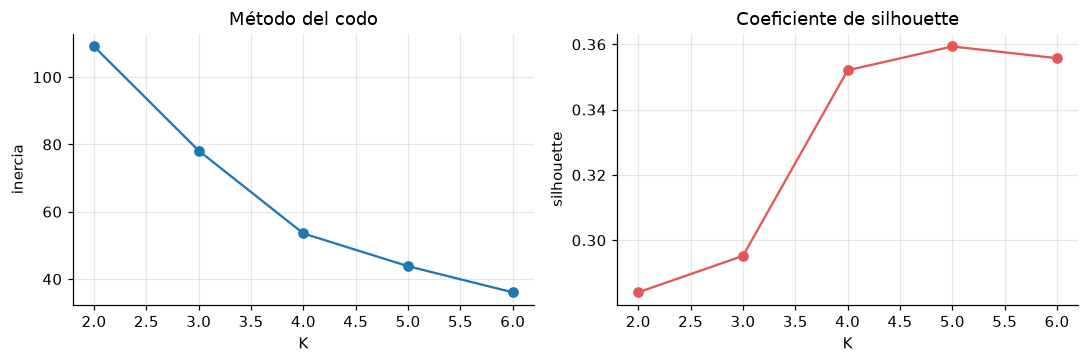

Silhouette por K: {2: np.float64(0.284), 3: np.float64(0.295), 4: np.float64(0.352), 5: np.float64(0.359), 6: np.float64(0.356)}


In [77]:
K_MAX = 6                            # con ~27 días de entrenamiento, más de 6 grupos deja grupos de 2 o 3 días (supuesto del equipo, 4.5)
def tabla_dias(D):
    x = D[~D.imputado]
    g = x.groupby('fecha')
    out = pd.DataFrame({'energia_MWh': g.AC_PLANTA_KW.sum() * 0.25 / 1000, 'irr_kWh_m2': g.IRRADIATION.sum() * 0.25})
    out['rendimiento_MWh_por_kWhm2'] = out.energia_MWh / out.irr_kWh_m2
    s = x[x.IRRADIATION > UMBRAL_IRR]; gs = s.groupby('fecha')
    out['hora_pico'] = gs.apply(lambda q: q.loc[q.AC_PLANTA_KW.idxmax(), 'hora'], include_groups=False)
    out['variabilidad_irr'] = gs.IRRADIATION.apply(lambda q: q.diff().abs().mean())
    out['inv_cero_prom'] = gs.n_inv_cero.mean()
    return out
dias_df = tabla_dias(D)
VARS_K = list(dias_df.columns)
dtr, dte = dias_df.loc[dias_train], dias_df.loc[dias_test]
esc_k = StandardScaler().fit(dtr[VARS_K]); Xk_tr, Xk_te = esc_k.transform(dtr[VARS_K]), esc_k.transform(dte[VARS_K])
display(dias_df.round(2).head(8))

ks = range(2, K_MAX + 1); inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xk_tr)
    inercia.append(km.inertia_); sil.append(silhouette_score(Xk_tr, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(list(ks), inercia, 'o-'); ax[0].set_xlabel('K'); ax[0].set_ylabel('inercia'); ax[0].set_title('Método del codo')
ax[1].plot(list(ks), sil, 'o-', color='#e45756'); ax[1].set_xlabel('K'); ax[1].set_ylabel('silhouette'); ax[1].set_title('Coeficiente de silhouette')
fig.tight_layout(); fig.savefig('figuras/f4_codo_silhouette.png', dpi=200, bbox_inches='tight'); plt.show()
print('Silhouette por K:', dict(zip(ks, np.round(sil, 3))))

El silhouette cambia poco entre K = 4 y K = 5 y el codo no marca un punto único; con pocos días ambos criterios son inestables. Se elige K = 4: no deja grupos de 2 días, tiene un silhouette casi igual al de K = 5 y da el mismo resultado de error por tipo de día (5.1.6 muestra la alternativa). Es una decisión del equipo apoyada en esos criterios, no un resultado único de los datos.

In [78]:
K_ELEGIDO = 4                        # decisión del equipo: K = 4; None = el de mayor silhouette entre 2 y K_MAX (decisión 4.5.1)
K = K_ELEGIDO or list(ks)[int(np.argmax(sil))]
print('K usado:', K)

K usado: 4


K = 4. Grupos numerados de menor a mayor energía; los nombres se leen de los centroides.
Centroides en unidades originales:


,energia_MWh,irr_kWh_m2,rendimiento_MWh_por_kWhm2,hora_pico,variabilidad_irr,inv_cero_prom,días entrenamiento,días prueba,nombre
grupo,,,,,,,,,
1,109.51,4.10,26.62,13.33,0.11,0.64,3,4,"nublado, pocas pérdidas"
2,122.30,5.63,21.78,10.85,0.09,3.18,10,3,parcialmente nublado con pérdidas
3,153.38,6.88,22.30,14.93,0.05,3.31,7,0,despejado con pérdidas moderadas
4,158.93,6.39,24.97,10.07,0.05,1.75,7,0,despejado con pocas pérdidas


Grupo 1: 31-05, 01-06, 03-06, 11-06*, 12-06*, 16-06*, 17-06* (* = día de prueba)
Grupo 2: 16-05, 18-05, 19-05, 02-06, 04-06, 05-06, 06-06, 07-06, 09-06, 10-06, 13-06*, 14-06*, 15-06* (* = día de prueba)
Grupo 3: 20-05, 21-05, 22-05, 23-05, 24-05, 27-05, 08-06 (* = día de prueba)
Grupo 4: 15-05, 17-05, 25-05, 26-05, 28-05, 29-05, 30-05 (* = día de prueba)


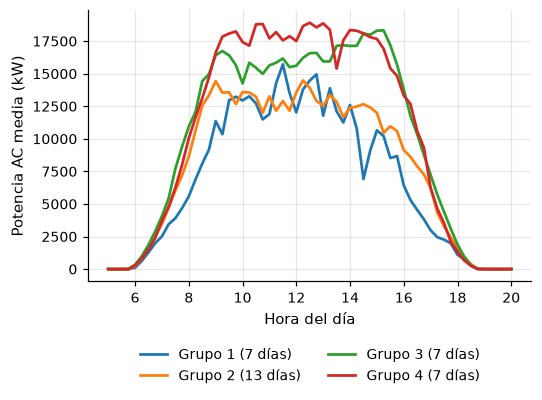

In [79]:
def ajustar_kmeans(k):
    # K-Means con los días de entrenamiento; grupos numerados de 1 a k de menor a mayor energía, para que el número no dependa de la versión
    km_ = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xk_tr)
    cent_crudo = pd.DataFrame(esc_k.inverse_transform(km_.cluster_centers_), columns=VARS_K)
    orden = list(cent_crudo.sort_values(['energia_MWh', 'irr_kWh_m2']).index)
    nuevo = {viejo: i + 1 for i, viejo in enumerate(orden)}
    crudo = pd.Series(np.r_[km_.labels_, km_.predict(Xk_te)], index=list(dtr.index) + list(dte.index)).sort_index()
    grp_ = crudo.map(nuevo).rename('grupo')
    cent_ = cent_crudo.rename(index=nuevo).sort_index().round(2); cent_.index.name = 'grupo'
    cent_['días entrenamiento'] = [int(((grp_ == g) & grp_.index.isin(dias_train)).sum()) for g in cent_.index]
    cent_['días prueba'] = [int(((grp_ == g) & grp_.index.isin(dias_test)).sum()) for g in cent_.index]
    return km_, grp_, cent_

def listar_dias(grp_, k):
    for g_ in range(1, k + 1):
        print(f'Grupo {g_}: ' + ', '.join(f'{d_.strftime("%d-%m")}{"*" if d_ in dias_test else ""}' for d_ in grp_.index[grp_ == g_]), '(* = día de prueba)')

def graficar_perfiles(grp_, k, nombres, archivo):
    # leyenda corta (número y días); los nombres de los grupos están en la tabla de centroides de arriba
    fig, ax = plt.subplots(figsize=(5.2, 3.2))
    for g_ in range(1, k + 1):
        dg = grp_.index[grp_ == g_]
        p_ = D[D.fecha.isin(dg) & ~D.imputado & D.hora.between(5, 20)].groupby('hora').AC_PLANTA_KW.mean()
        ax.plot(p_.index, p_.values, lw=1.8, label=f'Grupo {g_} ({len(dg)} días)')
    ax.set_xlabel('Hora del día', fontsize=10); ax.set_ylabel('Potencia AC media (kW)', fontsize=10)
    ax.tick_params(labelsize=9); ax.grid(alpha=.3)
    ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)  # fuera de las curvas
    fig.savefig(archivo, dpi=300, bbox_inches='tight'); plt.show()

km, grp, cent = ajustar_kmeans(K)
dias_df['grupo'] = grp
# Nombres leídos de los centroides (irradiación, rendimiento = MWh por kWh/m² e inversores en cero), no del dibujo de los perfiles
NOMBRES_POR_K = {4: {1: 'nublado, pocas pérdidas', 2: 'parcialmente nublado con pérdidas', 3: 'despejado con pérdidas moderadas', 4: 'despejado con pocas pérdidas'},
                 5: {1: 'nublado, pocas pérdidas', 2: 'buen sol con pérdidas fuertes', 3: 'parcialmente nublado con pérdidas', 4: 'despejado con pérdidas moderadas', 5: 'despejado con pocas pérdidas'}}
NOMBRES_GRUPOS = NOMBRES_POR_K.get(K, {})
print(f'K = {K}. Grupos numerados de menor a mayor energía; los nombres se leen de los centroides.')
print('Centroides en unidades originales:'); display(cent.assign(nombre=[NOMBRES_GRUPOS.get(g, '') for g in cent.index]))
listar_dias(grp, K)
graficar_perfiles(grp, K, NOMBRES_GRUPOS, 'figuras/f4_grupos_dias.png')

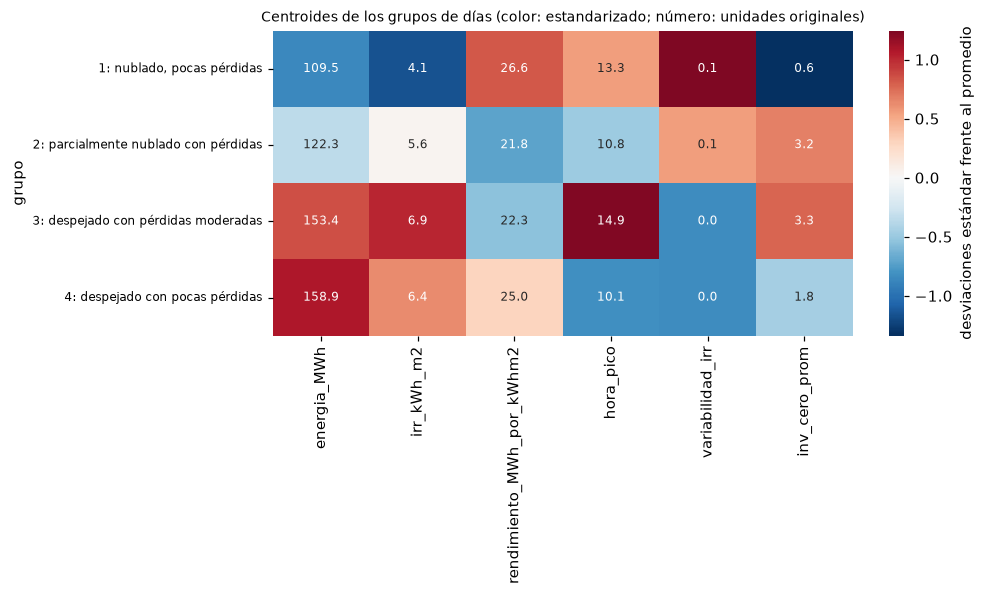

In [80]:
cz = (cent[VARS_K] - dias_df[VARS_K].mean()) / dias_df[VARS_K].std()
fig, ax = plt.subplots(figsize=(8.5, 3.6))
sns.heatmap(cz, annot=cent[VARS_K].round(1), fmt='', cmap='RdBu_r', center=0, cbar_kws={'label': 'desviaciones estándar frente al promedio'}, ax=ax, annot_kws={'size': 8})
ax.set_yticklabels([f'{g_}: {NOMBRES_GRUPOS.get(g_, "")}' for g_ in cent.index], rotation=0, fontsize=8); ax.grid(False)
ax.set_title('Centroides de los grupos de días (color: estandarizado; número: unidades originales)', fontsize=9)
fig.savefig('figuras/f4_perfil_grupos.png', dpi=200, bbox_inches='tight'); plt.show()

Los grupos se ordenan de menos a más energía y se nombran leyendo sus centroides (irradiación, rendimiento e inversores en cero), no el dibujo de los perfiles: separan días nublados, días parcialmente nublados con pérdidas y días despejados con más o menos pérdidas. El grupo de día no se usa como predictor, así que no hay fuga de información.

## 4.6 Evaluación técnica
Ranking por criterios objetivos. Ningún modelo suelto supera con claridad a la persistencia en F1 macro; el ensamble sí mejora el F1 macro y el kappa frente a la persistencia y a la combinación persistencia-climatología en la evaluación día a día (5.1.2), con una ventaja pequeña. Criterios subjetivos. Interpretabilidad: el árbol y la logística son fáciles de explicar, el ensamble menos, pero sus miembros lineales y el bosque pueden inspeccionarse. Facilidad de despliegue: el ensamble usa solo información disponible a tiempo, se reentrena con datos nuevos sin cambiar nada más y la predicción de un instante es inmediata (6.3).

| Elemento | Resultado |
|---|---|
| Técnicas probadas | 17 candidatos y 9 384 combinaciones, todos reportados |
| Líneas base | Clase más frecuente, persistencia, climatología y su combinación |
| Selección | Con datos de entrenamiento, con la excepción declarada del ensamble (4.4.3) |
| Estabilidad | Resultados modestos, que se evalúan con intervalos en la fase 5 |

<a id="fase5"></a>
# Fase 5: Evaluación
La fase 4 midió los modelos con criterios técnicos (F1, kappa, precisión de bajo). Aquí se mide con criterios de negocio: dónde acierta y falla el modelo final, cuánta energía cuesta equivocarse, qué tan sensible es el resultado a las decisiones de limpieza y si hay fuga de información. De aquí en adelante "el modelo" es el ensamble de cuatro modelos (`pred_te`).

## 5.1 Evaluar los resultados frente a los criterios de negocio
### 5.1.1 Horas centrales
Precisión de bajo por hora del día en la partición principal. Al amanecer y al atardecer la potencia ya es baja y bajo se acierta casi siempre, incluso con la persistencia.

,instantes,% realmente bajo,precisión de bajo (persistencia),precisión de bajo (ensamble)
h_int,,,,
6,17,100.00,1.00,1.00
7,28,92.86,0.93,0.96
8,28,57.14,0.78,1.00
9,28,32.14,0.40,0.80
10,28,25.00,0.67,0.67
11,28,17.86,0.43,0.50
12,28,10.71,0.33,0.33
13,28,21.43,0.60,0.50
14,28,25.00,0.43,0.50


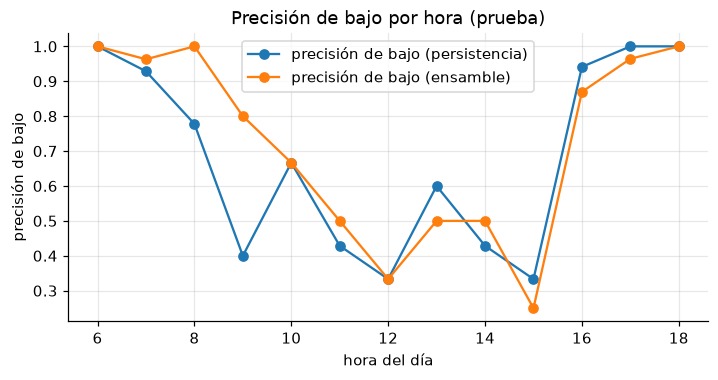

In [81]:
te_h = test.assign(real=yte, pred_ens=pred_te, pred_pers=persistencia(test)); te_h['h_int'] = te_h.hora.astype(int)
def prec_h(g, col):
    dijo = g[col] == 0
    return (dijo & (g.real == 0)).sum() / dijo.sum() if dijo.sum() else np.nan
por_h = pd.DataFrame({'instantes': te_h.groupby('h_int').size(), '% realmente bajo': 100 * te_h.groupby('h_int').apply(lambda g: (g.real == 0).mean(), include_groups=False),
                      'precisión de bajo (persistencia)': te_h.groupby('h_int').apply(lambda g: prec_h(g, 'pred_pers'), include_groups=False),
                      'precisión de bajo (ensamble)': te_h.groupby('h_int').apply(lambda g: prec_h(g, 'pred_ens'), include_groups=False)})
display(por_h.round(2))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
por_h[['precisión de bajo (persistencia)', 'precisión de bajo (ensamble)']].plot(ax=ax, marker='o'); ax.set_xlabel('hora del día'); ax.set_ylabel('precisión de bajo'); ax.set_title('Precisión de bajo por hora (prueba)')
fig.savefig('figuras/f5_precision_bajo_por_hora.png', dpi=200, bbox_inches='tight'); plt.show()

En las primeras y últimas horas del día casi todo lo que se anuncia como bajo lo es, con cualquier método; en las horas centrales (cerca del mediodía) es donde la precisión de bajo baja y la decisión es difícil. Por eso las cifras de todo el día inflan el desempeño y se reporta también la tabla de horas centrales. Con base en esa tabla, el equipo fija las horas centrales de 9 a 17 h.

In [82]:
HORAS_CENTRALES = (9, 17)            # fuera de este rango (amanecer y atardecer) 'bajo' es casi trivial (decisión 5.1.1)
w_conv = peso_convexo(train_d, clim_tr)
a_te, c_te = test_d['AC_PLANTA_KW_lag1'].to_numpy(), clim_tr(test_d['hora'].to_numpy())
a_clase = lambda x: np.digitize(x, cortes, right=True)
preds_80 = {
    'Persistencia de la clase': persistencia(test_d),
    'Climatología por hora': a_clase(c_te),
    f'Combinación persistencia-climatología (w = {w_conv:.2f})': a_clase(w_conv * a_te + (1 - w_conv) * c_te),
    f'Mejor modelo individual ({MEJOR_NOMBRE}, conjunto {MEJOR_CONJ})': pred_arbol,
}
preds_80['Ensamble (sin umbral)'] = ens_80['sin_umbral']
preds_80[f'Ensamble + umbral para bajo (tau = {ens_80["tau"]:.3f})'] = ens_80['con_umbral']
mask_centrales = ((test_d['hora'] >= HORAS_CENTRALES[0]) & (test_d['hora'] < HORAS_CENTRALES[1])).to_numpy()

print('Partición principal, todo el día:')
t80 = tabla_metodos(yte, preds_80, ENERGIA); display(t80.round(3))
print(f'Partición principal, solo horas centrales ({HORAS_CENTRALES[0]} a {HORAS_CENTRALES[1]} h; {int(mask_centrales.sum())} de {len(yte)} instantes):')
t80c = tabla_metodos(yte, preds_80, ENERGIA, mask_centrales); display(t80c.round(3))
t80.to_csv('figuras/res_parteD_80_20.csv', encoding='utf-8-sig'); t80c.to_csv('figuras/res_parteD_80_20_centrales.csv', encoding='utf-8-sig')
f_pers, f_conv, f_ens = t80.iloc[0], t80.iloc[2], t80.iloc[4]
g_c = t80c.iloc[0]

Partición principal, todo el día:


,exactitud,F1 macro,kappa,F1 bajo,F1 medio,F1 alto,precisión de bajo,recall de bajo,veces que dijo bajo,falsos bajo,MWh en falsos bajo (cota)
método,,,,,,,,,,,
Persistencia de la clase,0.756,0.657,0.557,0.812,0.737,0.421,0.812,0.812,165,31,89.023
Climatología por hora,0.479,0.442,0.256,0.700,0.437,0.189,0.958,0.552,95,4,9.969
Combinación persistencia-climatología (w = 0.73),0.779,0.670,0.603,0.830,0.778,0.400,0.901,0.770,141,14,38.444
"Mejor modelo individual (Random Forest, conjunto C)",0.782,0.652,0.604,0.827,0.787,0.343,0.894,0.770,142,15,43.506
Ensamble (sin umbral),0.785,0.670,0.613,0.847,0.774,0.390,0.872,0.824,156,20,57.453
Ensamble + umbral para bajo (tau = 0.800),0.724,0.626,0.506,0.737,0.751,0.390,0.970,0.594,101,3,8.497


Partición principal, solo horas centrales (9 a 17 h; 224 de 340 instantes):


,exactitud,F1 macro,kappa,F1 bajo,F1 medio,F1 alto,precisión de bajo,recall de bajo,veces que dijo bajo,falsos bajo,MWh en falsos bajo (cota)
método,,,,,,,,,,,
Persistencia de la clase,0.670,0.580,0.353,0.576,0.744,0.421,0.590,0.562,61,25,73.581
Climatología por hora,0.295,0.257,0.023,0.169,0.413,0.189,0.857,0.094,7,1,2.521
Combinación persistencia-climatología (w = 0.73),0.696,0.581,0.369,0.563,0.780,0.400,0.744,0.453,39,10,28.912
"Mejor modelo individual (Random Forest, conjunto C)",0.688,0.552,0.338,0.533,0.779,0.343,0.683,0.438,41,13,38.528
Ensamble (sin umbral),0.692,0.592,0.394,0.622,0.764,0.390,0.673,0.578,55,18,52.475
Ensamble + umbral para bajo (tau = 0.800),0.652,0.488,0.218,0.308,0.766,0.390,0.857,0.188,14,2,6.173


En la partición principal el ensamble mejora a la persistencia en exactitud, F1 macro, kappa y precisión de bajo; frente a la combinación persistencia-climatología el F1 macro es parecido y la precisión de bajo queda por debajo en las horas centrales. Con solo 7 días de prueba eso no alcanza para concluir, y por eso viene la evaluación día a día.

### 5.1.2 Evaluación día a día (walk-forward)
Para cada día desde `WF_DIA_INICIO` se reconstruye todo con los días anteriores (corrección de inversores, terciles, climatología, hiperparámetros y umbral) y se predice solo ese día (4.2.1). Se compara el ensamble con la persistencia, la combinación persistencia-climatología y un árbol individual, y con el umbral para bajo como variante. El bootstrap remuestrea días completos: si el intervalo de 95 % incluye 0, la diferencia no se distingue del azar con estos días.

In [83]:
def _cm(y, p):
    cm_ = np.zeros((3, 3), int)
    for r_, q_ in zip(y, p): cm_[int(r_), int(q_)] += 1
    return cm_

def _met_cm(cm_):
    cm_ = np.asarray(cm_, float); tot = cm_.sum(); tp = np.diag(cm_)
    pr = np.divide(tp, cm_.sum(0), out=np.zeros(3), where=cm_.sum(0) > 0); rc = np.divide(tp, cm_.sum(1), out=np.zeros(3), where=cm_.sum(1) > 0)
    f = np.divide(2 * pr * rc, pr + rc, out=np.zeros(3), where=(pr + rc) > 0); po = tp.sum() / tot; pe = (cm_.sum(0) * cm_.sum(1)).sum() / tot ** 2
    return {'exactitud': po, 'F1 macro': f.mean(), 'kappa': (po - pe) / (1 - pe), 'precisión de bajo': pr[0], 'recall de bajo': rc[0],
            'veces que dijo bajo': int(cm_[:, 0].sum()), 'falsos bajo': int(cm_[1:, 0].sum())}

def walk_forward(dia_inicio):
    dias_ = ctx['dias']; nd_ = len(dias_); filas_ = []
    for j in range(dia_inicio, nd_):
        ds_j, ctx_j = preparar(gen, sen, frac_dias_train=(j + 0.5) / nd_)
        tr_ = ds_j[ds_j.fecha.isin(ctx_j['dias_train'])].sort_values('DATE_TIME').copy()
        te_ = ds_j[ds_j.fecha == dias_[j]].sort_values('DATE_TIME').copy()
        if len(te_) == 0: continue
        cortes_j = [float(tr_.AC_PLANTA_KW.quantile(q)) for q in (1 / 3, 2 / 3)]
        h_pico_j = tr_.groupby('hora').AC_PLANTA_KW.mean().idxmax()
        for d_ in (tr_, te_): d_['dist_mediodia'] = (d_['hora'] - h_pico_j).abs()
        clim_j = curva_climatologica(tr_); tr_, te_ = agregar_clim(tr_, clim_j), agregar_clim(te_, clim_j)
        y_tr = np.digitize(tr_.AC_PLANTA_KW.to_numpy(), cortes_j, right=True); y_te = np.digitize(te_.AC_PLANTA_KW.to_numpy(), cortes_j, right=True)
        cols_c = ['dist_mediodia'] + LAGS_POTENCIA + LAGS_SENSOR
        w_j = peso_convexo(tr_, clim_j); a_, c_ = te_['AC_PLANTA_KW_lag1'].to_numpy(), clim_j(te_['hora'].to_numpy())
        g_arbol = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), {'max_depth': list(range(2, 13)), 'min_samples_leaf': [1, 5, 10, 20]},
                               cv=cv, scoring='f1_macro', n_jobs=1).fit(tr_[cols_c], y_tr)
        ens_j = ensamble_predecir(tr_, y_tr, te_, cols_c + EXTRA_CLIM, CALIBRAR, TAU_MODO, TAU_FIJO)
        preds_ = {'Persistencia': np.digitize(a_, cortes_j, right=True),
                  'Combinación persistencia-climatología': np.digitize(w_j * a_ + (1 - w_j) * c_, cortes_j, right=True),
                  'Árbol individual': g_arbol.predict(te_[cols_c]),
                  'Ensamble (sin umbral)': ens_j['sin_umbral'], 'Ensamble + umbral para bajo': ens_j['con_umbral']}
        filas_.append(pd.DataFrame({'dia_idx': j, 'hora': te_['hora'].to_numpy(), 'real': y_te, 'kw': te_['AC_PLANTA_KW'].to_numpy(), **preds_}))
        print(f'  día {j + 1} de {nd_} listo (tau = {ens_j["tau"]:.3f})', flush=True)
    return pd.concat(filas_, ignore_index=True)

METODOS_WF = ['Persistencia', 'Combinación persistencia-climatología', 'Árbol individual', 'Ensamble (sin umbral)', 'Ensamble + umbral para bajo']
if EJECUTAR_WALK_FORWARD:
    wf = walk_forward(WF_DIA_INICIO)
    wf.to_csv('figuras/res_walkforward_filas.csv', index=False, encoding='utf-8-sig')

    def tabla_wf(g):
        t = pd.DataFrame({m: _met_cm(_cm(g.real.to_numpy(), g[m].to_numpy())) for m in METODOS_WF}).T
        t['MWh en falsos bajo (cota)'] = [g.kw[(g[m] == 0) & (g.real != 0)].sum() * 0.25 / 1000 for m in METODOS_WF]
        return t
    wf_des, wf_conf = wf[wf.dia_idx < WF_DIA_CONFIRMACION], wf[wf.dia_idx >= WF_DIA_CONFIRMACION]
    wf_cen = wf_conf[(wf_conf.hora >= HORAS_CENTRALES[0]) & (wf_conf.hora < HORAS_CENTRALES[1])]
    t_des, t_conf, t_cen = tabla_wf(wf_des), tabla_wf(wf_conf), tabla_wf(wf_cen)
    for nom_, t_ in (('Desarrollo', t_des), ('Confirmación', t_conf), (f'Confirmación, solo horas centrales ({HORAS_CENTRALES[0]} a {HORAS_CENTRALES[1]} h)', t_cen)):
        print(f'\n{nom_}:'); display(t_.round(3))
    t_des.to_csv('figuras/res_walkforward_desarrollo.csv', encoding='utf-8-sig'); t_conf.to_csv('figuras/res_walkforward_confirmacion.csv', encoding='utf-8-sig')
    t_cen.to_csv('figuras/res_walkforward_centrales.csv', encoding='utf-8-sig')

    # bootstrap de días (confirmación)
    rng_ = np.random.default_rng(SEMILLA); dias_c = sorted(wf_conf.dia_idx.unique())
    cms_ = {m: np.array([_cm(wf_conf[wf_conf.dia_idx == d].real.to_numpy(), wf_conf[wf_conf.dia_idx == d][m].to_numpy()) for d in dias_c]) for m in METODOS_WF}
    cols_boot = ['precisión de bajo', 'recall de bajo', 'F1 macro', 'kappa']; filas_b = []
    for a_m in ('Árbol individual', 'Ensamble (sin umbral)', 'Ensamble + umbral para bajo'):
        for b_m in ('Persistencia', 'Combinación persistencia-climatología'):
            dif = {k: [] for k in cols_boot}
            for _ in range(N_BOOT):
                ix = rng_.integers(0, len(dias_c), len(dias_c)); m1, m2 = _met_cm(cms_[a_m][ix].sum(0)), _met_cm(cms_[b_m][ix].sum(0))
                for k in cols_boot: dif[k].append(m1[k] - m2[k])
            o1, o2 = _met_cm(cms_[a_m].sum(0)), _met_cm(cms_[b_m].sum(0))
            for k in cols_boot:
                filas_b.append({'A': a_m, 'frente a B': b_m, 'métrica': k, 'diferencia (A − B)': o1[k] - o2[k],
                                'IC95 inferior': np.nanpercentile(dif[k], 2.5), 'IC95 superior': np.nanpercentile(dif[k], 97.5)})
    boot_wf = pd.DataFrame(filas_b); boot_wf['el IC excluye 0'] = (boot_wf['IC95 inferior'] > 0) | (boot_wf['IC95 superior'] < 0)
    print(f'\nBootstrap por días (confirmación, {len(dias_c)} días, {N_BOOT} remuestreos):'); display(boot_wf.round(3))
    boot_wf.to_csv('figuras/res_walkforward_bootstrap.csv', index=False, encoding='utf-8-sig')

else:
    print('Walk-forward desactivado (EJECUTAR_WALK_FORWARD = False).')

  día 15 de 34 listo (tau = 0.800)


  día 16 de 34 listo (tau = 0.800)


  día 17 de 34 listo (tau = 0.825)


  día 18 de 34 listo (tau = 0.800)


  día 19 de 34 listo (tau = 0.750)


  día 20 de 34 listo (tau = 0.750)


... (18 outputs left out)


Confirmación, solo horas centrales (9 a 17 h):


,exactitud,F1 macro,kappa,precisión de bajo,recall de bajo,veces que dijo bajo,falsos bajo,MWh en falsos bajo (cota)
Persistencia,0.663,0.562,0.321,0.547,0.515,95.0,43.0,126.424
Combinación persistencia-climatología,0.683,0.566,0.331,0.694,0.426,62.0,19.0,54.946
Árbol individual,0.674,0.519,0.263,0.681,0.317,47.0,15.0,42.495
Ensamble (sin umbral),0.712,0.607,0.403,0.654,0.525,81.0,28.0,79.297
Ensamble + umbral para bajo,0.676,0.489,0.232,0.778,0.139,18.0,4.0,10.654



Bootstrap por días (confirmación, 14 días, 2000 remuestreos):


,A,frente a B,métrica,diferencia (A − B),IC95 inferior,IC95 superior,el IC excluye 0
0,Árbol individual,Persistencia,precisión de bajo,0.101,0.063,0.136,True
1,Árbol individual,Persistencia,recall de bajo,-0.066,-0.092,-0.036,True
2,Árbol individual,Persistencia,F1 macro,-0.004,-0.041,0.026,False
3,Árbol individual,Persistencia,kappa,0.024,-0.013,0.062,False
4,Árbol individual,Combinación persistencia-climatología,precisión de bajo,0.013,-0.027,0.050,False
5,Árbol individual,Combinación persistencia-climatología,recall de bajo,-0.045,-0.077,-0.019,True
6,Árbol individual,Combinación persistencia-climatología,F1 macro,-0.023,-0.061,0.005,False
7,Árbol individual,Combinación persistencia-climatología,kappa,-0.023,-0.063,0.015,False
8,Ensamble (sin umbral),Persistencia,precisión de bajo,0.069,0.040,0.097,True
9,Ensamble (sin umbral),Persistencia,recall de bajo,0.021,-0.007,0.047,False


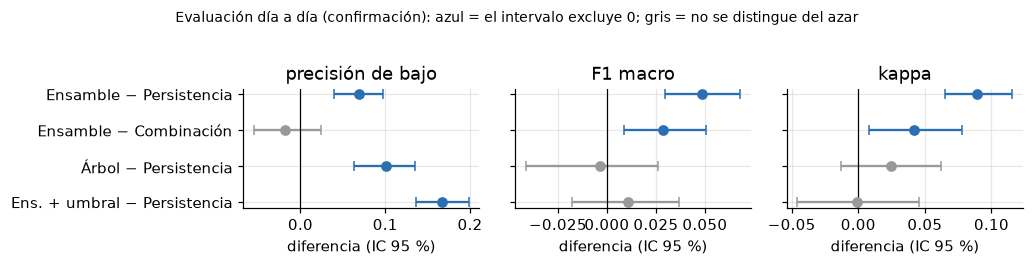

In [84]:
if EJECUTAR_WALK_FORWARD:
    comp = [('Ensamble (sin umbral)', 'Persistencia', 'Ensamble − Persistencia'),
            ('Ensamble (sin umbral)', 'Combinación persistencia-climatología', 'Ensamble − Combinación'),
            ('Árbol individual', 'Persistencia', 'Árbol − Persistencia'),
            ('Ensamble + umbral para bajo', 'Persistencia', 'Ens. + umbral − Persistencia')]
    fig, ax = plt.subplots(1, 3, figsize=(9.5, 2.3), sharey=True)
    for a, k in zip(ax, ['precisión de bajo', 'F1 macro', 'kappa']):
        for j, (A_, B_, _) in enumerate(comp):
            r_ = boot_wf[(boot_wf.A == A_) & (boot_wf['frente a B'] == B_) & (boot_wf['métrica'] == k)].iloc[0]
            d_ = r_['diferencia (A − B)']
            a.errorbar(d_, j, xerr=[[d_ - r_['IC95 inferior']], [r_['IC95 superior'] - d_]], fmt='o', capsize=3,
                       color='#2a6fb0' if r_['el IC excluye 0'] else '#999999')
        a.axvline(0, color='k', lw=.8); a.set_title(k); a.set_xlabel('diferencia (IC 95 %)')
    ax[0].set_yticks(range(len(comp))); ax[0].set_yticklabels([c[2] for c in comp]); ax[0].invert_yaxis()
    fig.suptitle('Evaluación día a día (confirmación): azul = el intervalo excluye 0; gris = no se distingue del azar', fontsize=9, y=1.03)
    fig.tight_layout(); fig.savefig('figuras/f5_walk_forward_ic.png', dpi=200, bbox_inches='tight'); plt.show()

Control cruzado. El ensamble de 4.4.1 (probabilidades de los candidatos, rejillas del experimento) y el de este paso (reconstruido por `ensamble_predecir`) usan los mismos modelos y las mismas rejillas, así que deben dar las mismas predicciones.

In [85]:
if EJECUTAR_WALK_FORWARD:
    pred_candidatos = np.mean([PROB[ENS_WF[n]] for n in ENS_MODELOS], axis=0).argmax(1)
    coincide = (wf['Ensamble (sin umbral)'].to_numpy() == pred_candidatos).mean() if len(wf) == len(pred_candidatos) else np.nan
    print(f'El ensamble de la combinatoria coincide con el del walk-forward en {100 * coincide:.2f} % de los {len(wf)} instantes.')

El ensamble de la combinatoria coincide con el del walk-forward en 99.90 % de los 956 instantes.


Los resultados anteriores se resumen así (las cifras exactas están en las tablas de arriba y se exportan en 6.8).
- El ensamble supera a la persistencia en precisión de bajo, F1 macro y kappa, con intervalos de 95 % que no incluyen 0.
- Frente a la combinación persistencia-climatología, el ensamble mejora el F1 macro y el kappa con intervalos que excluyen 0; la precisión de bajo no se distingue. Es una ventaja pequeña y está inflada porque la composición del ensamble se eligió mirando estos mismos días (4.4.5).
- El árbol solo supera a la persistencia en precisión de bajo, y lo paga con menos recall; en F1 macro y kappa no se distingue de ella.
- El umbral sube mucho la precisión de bajo pero baja el recall, el F1 macro y el kappa: no es una mejora gratis.
- En las horas centrales todas las precisiones de bajo bajan; las horas de amanecer y atardecer inflan las cifras de todo el día.

Por qué se eligió el ensamble. Con estos datos ningún método gana en todo. Se eligió porque (1) es el único que supera a la persistencia y a la combinación en F1 macro y kappa con respaldo estadístico; (2) mezcla modelos con errores distintos, lo que lo hace más estable que un modelo suelto con pocos días (4.4.2); y (3) usa solo información que se conoce a tiempo y se reentrena con datos nuevos sin cambiar nada más. Su límite es que la composición se eligió buscando entre 9 384 ensambles con estos mismos días.

### 5.1.3 Dónde acierta y dónde falla

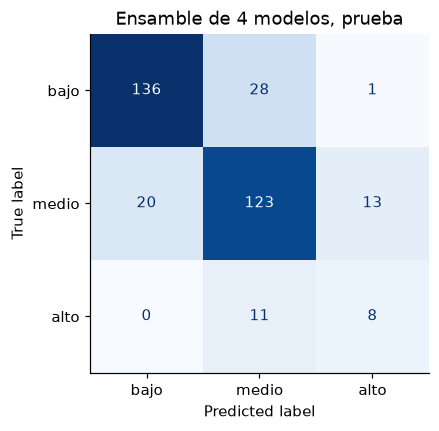

              precision    recall  f1-score   support

        bajo      0.872     0.824     0.847       165
       medio      0.759     0.788     0.774       156
        alto      0.364     0.421     0.390        19

    accuracy                          0.785       340
   macro avg      0.665     0.678     0.670       340
weighted avg      0.792     0.785     0.788       340

Kappa de Cohen del modelo final: 0.613
Tasa de error por clase real: {'bajo': 0.176, 'medio': 0.212, 'alto': 0.579}
Errores por tipo (real a predicho): {'bajo a medio': 28, 'medio a bajo': 20, 'medio a alto': 13, 'alto a medio': 11, 'bajo a alto': 1, 'alto a bajo': 0}
Condiciones medias de los instantes por (real, predicho); IRRADIATION es la de t, solo para describir:


IRRADIATION  MODULE_TEMPERATURE  IRRADIATION_lag1  AC_PLANTA_KW_lag1  n_inv_cero
real  pred                                                                                   
alto  alto          0.61               42.02              0.56           16818.02        1.00
      medio         0.58               40.76              0.41           12381.49        1.09
bajo  alto          0.62               45.40              0.58           15431.14       22.00
      bajo          0.14               28.74              0.14            3842.99        0.42
      medio         0.33               36.72              0.45           11414.61        2.07
medio alto          0.52               41.08              0.62           16587.43        2.15
      bajo          0.40               35.20              0.30            6333.92        0.80
      medio         0.47               38.32              0.46           11746.23        2.41

In [86]:
cm = confusion_matrix(yte, pred_te, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(cm, display_labels=ETIQ).plot(ax=ax, cmap='Blues', colorbar=False); ax.grid(False)
ax.set_title(f'{FINAL_NOMBRE}, prueba'); fig.savefig('figuras/f5_matriz_confusion.png', dpi=200, bbox_inches='tight'); plt.show()
print(classification_report(yte, pred_te, target_names=ETIQ, digits=3, zero_division=0))
print('Kappa de Cohen del modelo final:', round(cohen_kappa_score(yte, pred_te), 3))

te = test.assign(real=pd.Series(yte, index=test.index).map(dict(enumerate(ETIQ))), pred=pd.Series(pred_te, index=test.index).map(dict(enumerate(ETIQ))))
err = te[te.real != te.pred]
conf = pd.crosstab(te.real, te.pred).reindex(index=ETIQ, columns=ETIQ, fill_value=0)
tasa = (1 - np.diag(cm) / cm.sum(axis=1)).round(3)
print('Tasa de error por clase real:', {k: float(v) for k, v in zip(ETIQ, tasa)})
pares = pd.Series({f'{r} a {p}': int(conf.loc[r, p]) for r in ETIQ for p in ETIQ if r != p}).sort_values(ascending=False)
print('Errores por tipo (real a predicho):', pares.to_dict())
cond = te.groupby(['real', 'pred'])[['IRRADIATION', 'MODULE_TEMPERATURE', 'IRRADIATION_lag1', 'AC_PLANTA_KW_lag1', 'n_inv_cero']].mean().round(2)
print('Condiciones medias de los instantes por (real, predicho); IRRADIATION es la de t, solo para describir:')
display(cond)

Casi todo el error está entre niveles vecinos (bajo con medio y medio con alto), y alto es la clase más difícil: es la más pequeña y la que más depende de picos que la potencia anterior no anuncia. Los instantes realmente bajo en que el modelo anunció medio o alto tienen, en promedio, más inversores en cero que los bajo bien anunciados: son pérdidas que el pronóstico por sí solo no puede ver (6.3.2 las convierte en alertas).

### 5.1.4 Costo de los falsos bajo
La empresa solo hace mantenimiento cuando el modelo anuncia bajo. Si dice bajo y el nivel real era medio o alto, se interviene en una hora con producción y esa energía se pierde. La métrica de negocio es la precisión de bajo y la energía de los falsos bajo. La energía se estima con la potencia de la planta en esos instantes (x 0,25 h): es una cota superior si se desconectara toda la planta; la columna "1 inversor" la divide entre los 22 inversores. Los datos no traen el tamaño de un string, así que la parte que se desconecta es un supuesto del equipo.

In [87]:
filas = [{'modelo': 'Persistencia de la clase', 'conjunto': '-', **prec_bajo(yte, persistencia(test), ENERGIA)},
         {'modelo': 'Siempre "bajo"', 'conjunto': '-', **prec_bajo(yte, np.zeros(len(yte), int), ENERGIA)}]
for (nombre, conj), (est, cols) in AJUSTADOS.items():
    filas.append({'modelo': nombre, 'conjunto': conj, **prec_bajo(yte, est.predict(test[cols]), ENERGIA)})
filas.append({'modelo': FINAL_NOMBRE, 'conjunto': 'C + clima', **prec_bajo(yte, pred_te, ENERGIA)})
tabla_costo = pd.DataFrame(filas)
tabla_costo['final'] = tabla_costo.modelo == FINAL_NOMBRE
display(tabla_costo.sort_values('precisión de bajo', ascending=False).round(3))
fb = tabla_costo[tabla_costo.final].iloc[0]; pers = tabla_costo.iloc[0]

,modelo,conjunto,veces que dijo bajo,precisión de bajo,recall de bajo (ventanas aprovechadas),falsos bajo,MWh en falsos bajo (cota),MWh en falsos bajo (1 inversor),MWh en todos los instantes dichos bajo,final
38,Árbol,C,128,0.922,0.715,10,29.944,1.361,135.877,False
10,LR interacciones,A,132,0.917,0.733,11,29.111,1.323,140.798,False
49,LR + K-Means (k=6),C,141,0.915,0.782,12,33.702,1.532,155.286,False
3,KNN,A,140,0.914,0.776,12,33.510,1.523,151.713,False
34,K-Means por grupos,B,128,0.914,0.709,11,29.335,1.333,134.421,False
21,Árbol,B,135,0.911,0.745,12,35.680,1.622,149.543,False
32,LR + K-Means (k=6),B,135,0.911,0.745,12,33.686,1.531,148.716,False
40,HistGradientBoosting,C,146,0.897,0.794,15,43.286,1.968,170.368,False
39,Random Forest,C,142,0.894,0.770,15,43.506,1.978,164.477,False
17,K-Means por grupos,A,141,0.894,0.764,15,40.111,1.823,154.462,False


Ejemplo en pesos. Es una ilustración con supuestos, no un resultado del modelo: la planta vende a `PRECIO_COP_KWH` pesos por kWh y cada instante elegido para intervenir deja de producir lo que habría generado. Se comparan cinco formas de elegir la hora: sin criterio, una regla de horario sin modelo (los mismos instantes, pero tomando los más lejanos del mediodía), la persistencia, el modelo final y un ideal. La regla de horario separa lo que gana el modelo de lo que se gana con solo evitar el mediodía. El precio de 350 COP/kWh es un supuesto del equipo; no proviene de las fuentes.

In [88]:
PRECIO_COP_KWH = 350                 # precio de venta supuesto por el equipo (COP por kWh); es un supuesto, no un dato (decisión 5.1.4)
n_final = int((pred_te == 0).sum())
orden_dist = np.argsort(-test['dist_mediodia'].to_numpy(), kind='stable')            # los más lejos del mediodía primero
elige = {'Sin criterio (cualquier hora de sol)': np.ones(len(test), bool),
         f'Regla de horario ({n_final} instantes más lejos del mediodía)': np.isin(np.arange(len(test)), orden_dist[:n_final]),
         'Persistencia de la clase': persistencia(test) == 0,
         f'Modelo final ({FINAL_NOMBRE})': pred_te == 0,
         'Ideal (solo instantes realmente bajos)': yte == 0}
filas = []
for nombre, m in elige.items():
    kwh = ENERGIA[m] * 0.25
    falsos = m & (yte != 0)
    filas.append({'cómo se elige la hora': nombre, 'instantes elegidos': int(m.sum()), 'precisión de bajo': float((m & (yte == 0)).sum() / m.sum()),
                  'falsos bajo': int(falsos.sum()), 'kWh perdidos por instante': kwh.mean(),
                  'COP por instante (planta completa)': kwh.mean() * PRECIO_COP_KWH,
                  'COP por instante (1 inversor)': kwh.mean() * PRECIO_COP_KWH / N_INV,
                  'COP en falsos bajo (planta completa)': ENERGIA[falsos].sum() * 0.25 * PRECIO_COP_KWH})
tabla_pesos = pd.DataFrame(filas)
base_cop = tabla_pesos.iloc[0]['COP por instante (planta completa)']
tabla_pesos['ahorro frente a sin criterio (%)'] = 100 * (1 - tabla_pesos['COP por instante (planta completa)'] / base_cop)
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')
display(tabla_pesos.set_index('cómo se elige la hora'))
pd.reset_option('display.float_format')
fila_reg, fila_mod, fila_per = tabla_pesos.iloc[1], tabla_pesos.iloc[3], tabla_pesos.iloc[2]
print(f'Precio supuesto: {PRECIO_COP_KWH} COP/kWh | energía de la prueba: {ENERGIA.sum() * 0.25 / 1000:.0f} MWh = {ENERGIA.sum() * 0.25 * PRECIO_COP_KWH / 1e6:.0f} millones COP (planta completa, {len(dias_test)} días)')

,instantes elegidos,precisión de bajo,falsos bajo,kWh perdidos por instante,COP por instante (planta completa),COP por instante (1 inversor),COP en falsos bajo (planta completa),ahorro frente a sin criterio (%)
cómo se elige la hora,,,,,,,,
Sin criterio (cualquier hora de sol),340,0.5,175,"2,146.9","751,407.1","34,154.9","193,527,165.0",0.0
Regla de horario (156 instantes más lejos del mediodía),156,0.8,31,"1,313.7","459,793.1","20,899.7","30,465,310.3",38.8
Persistencia de la clase,165,0.8,31,"1,321.5","462,509.3","21,023.1","31,158,134.1",38.4
Modelo final (Ensamble de 4 modelos),156,0.9,20,"1,213.8","424,834.3","19,310.6","20,108,451.1",43.5
Ideal (solo instantes realmente bajos),165,1.0,0,"1,072.7","375,462.2","17,066.5",0.0,50.0


Precio supuesto: 350 COP/kWh | energía de la prueba: 730 MWh = 255 millones COP (planta completa, 7 días)


Casi todo el ahorro de pesos viene de evitar el mediodía, no del modelo: una regla de horario sin modelo ahorra casi tanto, aunque con más falsos bajo. El valor del modelo está en reducir los falsos bajo (intervenir con producción) y en aprovechar las ventanas bajas reales, no en ahorrar más pesos que una regla simple. Límites: el precio y la parte de la planta intervenida son supuestos; solo hay 7 días de prueba, más nublados que el entrenamiento; no se modela la duración real del mantenimiento.

### 5.1.5 Con y sin inversores en cero
Cuando hay inversores no disponibles, la norma IEC 61724-1 (cláusula 15.3) permite excluir esos periodos, incluirlos o analizar de las dos formas [15]. Se reportan ambas. El número de inversores en cero en el instante evaluado no se conoce de antemano: es una descripción, no un predictor.

In [89]:
sub = {'todos los instantes': np.ones(len(te), bool), 'sin inversores en cero': (te.n_inv_cero == 0).to_numpy(),
       'con inversores en cero': (te.n_inv_cero > 0).to_numpy()}
modelos_cmp = [(FINAL_NOMBRE, pred_te), ('Persistencia de la clase', persistencia(test))]
filas = []
for nombre, m in sub.items():
    for mod, p in modelos_cmp:
        pb = prec_bajo(yte[m], p[m], ENERGIA[m])
        filas.append({'instantes': nombre, 'n': int(m.sum()), 'modelo': mod, 'exactitud': accuracy_score(yte[m], p[m]),
                      'F1 macro': f1_score(yte[m], p[m], average='macro', zero_division=0),
                      'precisión de bajo': pb['precisión de bajo'], 'falsos bajo': pb['falsos bajo']})
tabla_iec = pd.DataFrame(filas)
display(tabla_iec.round(3))

,instantes,n,modelo,exactitud,F1 macro,precisión de bajo,falsos bajo
0,todos los instantes,340,Ensamble de 4 modelos,0.785,0.670,0.872,20
1,todos los instantes,340,Persistencia de la clase,0.756,0.657,0.812,31
2,sin inversores en cero,276,Ensamble de 4 modelos,0.801,0.692,0.880,18
3,sin inversores en cero,276,Persistencia de la clase,0.764,0.668,0.832,26
4,con inversores en cero,64,Ensamble de 4 modelos,0.719,0.483,0.667,2
5,con inversores en cero,64,Persistencia de la clase,0.719,0.503,0.500,5


Con inversores en cero el desempeño de todos los métodos cae (el F1 macro del ensamble baja de 0,69 a 0,48), lo cual es natural: son instantes donde la potencia se desploma sin que nada en el pasado inmediato lo anuncie. Aun así, el ensamble comete menos falsos bajo que la persistencia en ese subconjunto (2 frente a 5) y mantiene una precisión de bajo mayor, aunque con solo 64 instantes la comparación es indicativa y no concluyente. Para la empresa la lectura útil es otra: en esos momentos el pronóstico es menos confiable y es justo donde la alerta de inversores en cero (6.3) agrega más valor.

### 5.1.6 Error por tipo de día
Se usa el K-Means de días de 4.5. Por grupo se reportan el error, la exactitud y el kappa del modelo final. Se eligió K = 4: sin grupos de 2 días, con silhouette casi igual al de K = 5 y el mismo resultado en esta tabla (abajo se muestra la alternativa). Con pocos instantes por grupo, una diferencia pequeña puede ser azar.

In [90]:
def resumen_grupo(g):
    kap = cohen_kappa_score(g.real, g.pred) if (g.real.nunique() > 1 or g.pred.nunique() > 1) else np.nan
    return pd.Series({'días': g.fecha.nunique(), 'instantes': len(g), 'error %': 100 * (g.real != g.pred).mean(), 'accuracy': (g.real == g.pred).mean(), 'kappa': kap,
                      'F1 macro': f1_score(g.real, g.pred, average='macro', zero_division=0),
                      'bajo %': 100 * (g.real == 'bajo').mean(), 'alto %': 100 * (g.real == 'alto').mean(), 'inversores en cero (prom.)': g.n_inv_cero.mean()})
def error_por_grupo(grp_, nombres):
    tab = te.assign(grupo=te.fecha.map(grp_)).groupby('grupo').apply(resumen_grupo, include_groups=False).round(2)
    tab.index = [f'{g_}' + (f', {nombres[g_]}' if g_ in nombres else '') for g_ in tab.index]
    return tab
por_grupo = error_por_grupo(grp, NOMBRES_GRUPOS)
print(f'K = {K}: error del modelo final por tipo de día en la prueba'); display(por_grupo)
ausentes_prueba = [g_ for g_ in range(1, K + 1) if g_ not in set(te.fecha.map(grp))]
print('Grupos que no aparecen en los días de prueba:', ausentes_prueba or 'ninguno')
peor = por_grupo['error %'].idxmax()

# Alternativa (la otra opción que se evaluó)
K_ALT = 5 if K == 4 else 4
km_alt, grp_alt, cent_alt = ajustar_kmeans(K_ALT)
print(f'K = {K_ALT}: error del modelo final por tipo de día en la prueba'); display(error_por_grupo(grp_alt, NOMBRES_POR_K.get(K_ALT, {})))

K = 4: error del modelo final por tipo de día en la prueba


,días,instantes,error %,accuracy,kappa,F1 macro,bajo %,alto %,inversores en cero (prom.)
"1, nublado, pocas pérdidas",4.0,192.0,18.75,0.81,0.67,0.71,52.08,7.29,0.29
"2, parcialmente nublado con pérdidas",3.0,148.0,25.00,0.75,0.53,0.58,43.92,3.38,2.98


Grupos que no aparecen en los días de prueba: [3, 4]
K = 5: error del modelo final por tipo de día en la prueba


,días,instantes,error %,accuracy,kappa,F1 macro,bajo %,alto %,inversores en cero (prom.)
"1, nublado, pocas pérdidas",4.0,192.0,18.75,0.81,0.67,0.71,52.08,7.29,0.29
"3, parcialmente nublado con pérdidas",3.0,148.0,25.00,0.75,0.53,0.58,43.92,3.38,2.98


En la prueba solo aparecen dos de los cuatro grupos (los otros dos son de días despejados que quedaron en entrenamiento). El error del modelo es mayor en el grupo de días parcialmente nublados con pérdidas, que tiene muchos más inversores en cero en promedio, que en el de días nublados con pocas pérdidas. Con tan pocos instantes la diferencia es una tendencia, no una regla; tampoco se puede decir nada de los días despejados con este conjunto de prueba.

### 5.1.7 Criterios de éxito frente a resultados
Los criterios son los de 1.1.6 y 1.3.3; la columna "resultado" sale del código de esta fase.

In [91]:
def _b(a_m, b_m, k):
    return boot_wf[(boot_wf.A == a_m) & (boot_wf['frente a B'] == b_m) & (boot_wf['métrica'] == k)].iloc[0]
E_ = 'Ensamble (sin umbral)'; filas_ce = []
for ref_ in ('Persistencia', 'Combinación persistencia-climatología'):
    for k_ in ('F1 macro', 'kappa'):
        r_ = _b(E_, ref_, k_)
        filas_ce.append((f'Minería: {k_} del ensamble > {ref_.lower()}, IC95 excluye 0', f'{r_["diferencia (A − B)"]:+.3f} [{r_["IC95 inferior"]:+.3f}, {r_["IC95 superior"]:+.3f}]', 'Sí' if r_['IC95 inferior'] > 0 else 'No'))
r_ = _b(E_, 'Persistencia', 'precisión de bajo')
filas_ce.append(('Negocio y minería: precisión de bajo mayor o igual a persistencia', f'{r_["diferencia (A − B)"]:+.3f} [{r_["IC95 inferior"]:+.3f}, {r_["IC95 superior"]:+.3f}]', 'Sí' if r_['IC95 inferior'] > 0 else ('Parcial' if r_['diferencia (A − B)'] >= 0 else 'No')))
rec_ = t_conf.loc[E_, 'recall de bajo']
filas_ce.append((f'Negocio: recall de bajo mayor o igual a {RECALL_MIN_BAJO:.0%} (ventanas aprovechadas, confirmación)', f'{rec_:.3f}', 'Sí' if rec_ >= RECALL_MIN_BAJO else 'No'))
filas_ce.append(('Negocio: energía de los falsos bajo reportada en MWh y COP', f'{tabla_costo[tabla_costo.final].iloc[0]["MWh en falsos bajo (cota)"]:.1f} MWh (cota) en la prueba', 'Sí (5.1.4)'))
filas_ce.append(('Negocio: alertas con hora y causa probable', 'ver 6.3.2', 'Se muestra en 6.3.2'))
filas_ce.append(('Minería: la prueba de fuga no da un resultado casi perfecto', 'ver 5.3.2', 'Ver 5.3.2'))
pd.set_option('display.max_colwidth', 100); display(pd.DataFrame(filas_ce, columns=['criterio', 'resultado', '¿se cumple?']))

,criterio,resultado,¿se cumple?
0,"Minería: F1 macro del ensamble > persistencia, IC95 excluye 0","+0.049 [+0.030, +0.068]",Sí
1,"Minería: kappa del ensamble > persistencia, IC95 excluye 0","+0.089 [+0.065, +0.116]",Sí
2,"Minería: F1 macro del ensamble > combinación persistencia-climatología, IC95 excluye 0","+0.029 [+0.009, +0.051]",Sí
3,"Minería: kappa del ensamble > combinación persistencia-climatología, IC95 excluye 0","+0.042 [+0.008, +0.078]",Sí
4,Negocio y minería: precisión de bajo mayor o igual a persistencia,"+0.069 [+0.040, +0.097]",Sí
5,"Negocio: recall de bajo mayor o igual a 70% (ventanas aprovechadas, confirmación)",0.827,Sí
6,Negocio: energía de los falsos bajo reportada en MWh y COP,57.5 MWh (cota) en la prueba,Sí (5.1.4)
7,Negocio: alertas con hora y causa probable,ver 6.3.2,Se muestra en 6.3.2
8,Minería: la prueba de fuga no da un resultado casi perfecto,ver 5.3.2,Ver 5.3.2


El balance de los criterios es favorable: el ensamble supera a la persistencia y a la combinación persistencia-climatología en F1 macro y kappa con intervalos que excluyen 0, mejora la precisión de bajo frente a la persistencia y aprovecha más del 80 % de las ventanas bajas, por encima del mínimo del 70 %. Conviene leerlo con cautela: la ventaja sobre la combinación es de pocas centésimas, la composición del ensamble se eligió mirando estos mismos días y el costo de los falsos bajo sigue siendo de varias decenas de MWh en la semana de prueba.

## 5.2 Descubrimientos
- El clima reciente casi no aporta sobre la historia de la potencia: casi toda la información está en la potencia de hace 15 minutos y en la hora típica del día.
- La dificultad está en las horas centrales: al amanecer y al atardecer bajo es casi trivial.
- Alto es la clase difícil: es la más pequeña y la que más depende de picos.
- Hay tipos de día con distinto error, y los días con inversores en cero son los más difíciles de anunciar.
- Casi todo el ahorro de pesos viene de evitar el mediodía: el valor del modelo está en reducir los falsos bajo y en señalar desvíos.

## 5.3 Revisar el proceso
### 5.3.1 Sensibilidad a la limpieza
¿Cambia la conclusión si se decide distinto en la limpieza? Se repite el modelo individual elegido cambiando una decisión a la vez (excluir o mantener incompletos, excluir la planta en cero, otro umbral de irradiancia). Las pruebas no son del todo comparables entre filas (cambian las filas y los cortes), pero muestran qué tanto depende el resultado de cada decisión.

In [92]:
def evaluar_config(umbral=UMBRAL_IRR, inc=TRATAR_INCOMPLETOS, cero=TRATAR_PLANTA_EN_CERO):
    ds_k, ctx_k = preparar(gen, sen, umbral=umbral, tratar_incompletos=inc, tratar_planta_en_cero=cero)
    tr_k, te_k = ds_k[ds_k.fecha.isin(ctx_k['dias_train'])], ds_k[ds_k.fecha.isin(ctx_k['dias_test'])]
    with contextlib.redirect_stdout(io.StringIO()):
        tr_k, te_k, cortes_k = crear_niveles(tr_k, te_k, 'AC_PLANTA_KW')
    tr_k, te_k = agregar_hora(tr_k), agregar_hora(te_k)
    y1 = tr_k.nivel.astype(str).map(NIVEL_A_INT).to_numpy(); y2 = te_k.nivel.astype(str).map(NIVEL_A_INT).to_numpy()
    est = clone(MEJOR_EST).fit(tr_k[MEJOR_COLS], y1); m = metricas(y2, est.predict(te_k[MEJOR_COLS]))
    return {'filas train/test': f'{len(tr_k)}/{len(te_k)}', 'corte bajo-medio (kW)': round(cortes_k[0]), 'corte medio-alto (kW)': round(cortes_k[1]),
            'accuracy': m['accuracy'], 'F1 macro': m['f1_macro'], 'F1 alto': m['f1_alto']}

configs = [('Base (decisiones adoptadas)', {}), ('Incompletos: excluir', {'inc': 'excluir'}), ('Incompletos: mantener', {'inc': 'mantener'}),
           ('Planta en cero: excluir', {'cero': 'excluir'}), ('Umbral 0.01', {'umbral': 0.01}), ('Umbral 0.05', {'umbral': 0.05})]
sens = pd.DataFrame([{'configuración': n, **evaluar_config(**kw)} for n, kw in configs]).set_index('configuración')
display(sens.round(3))

,filas train/test,corte bajo-medio (kW),corte medio-alto (kW),accuracy,F1 macro,F1 alto
configuración,,,,,,
Base (decisiones adoptadas),1275/340,9043,15466,0.782,0.652,0.343
Incompletos: excluir,811/340,7899,14273,0.729,0.682,0.517
Incompletos: mantener,1275/340,8224,13525,0.688,0.650,0.508
Planta en cero: excluir,1269/337,9115,15481,0.772,0.645,0.343
Umbral 0.01,1318/349,8460,15397,0.782,0.646,0.316
Umbral 0.05,1202/317,10210,15679,0.716,0.603,0.333


Las configuraciones no son comparables fila a fila (cambian las filas y los cortes), pero muestran dónde pesa cada decisión: excluir los instantes incompletos deja menos de dos tercios de las filas de entrenamiento y mueve los cortes; un umbral de 0,05 baja el F1 macro porque descarta instantes con potencia apreciable; mantener o excluir la planta en cero y bajar el umbral a 0,01 casi no cambian el resultado. Conclusión: el resultado es razonablemente robusto a esas dos últimas decisiones y sensible a cómo se tratan los instantes con inversores ausentes: excluirlos mejora el F1 macro pero deja menos de dos tercios de las filas de entrenamiento, y mantenerlos sin corregir baja la exactitud de 0,78 a 0,69 y cambia los cortes. Es justo la decisión que la validación de 3.2.1 respalda.

### 5.3.2 Fuga de información
Controles: que solo entren valores pasados y la hora, que el escalado esté dentro del `Pipeline`, que los terciles salgan solo del entrenamiento y que la prueba sea posterior. Después, una prueba que hace trampa a propósito: se agrega la potencia DC del mismo instante (no existe al predecir) y se mide cuánto mejora el árbol. Si el resultado es casi perfecto, no hay modelo: hay copia.

In [93]:
prohibidas = {'DC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'AC_PLANTA_KW', 'AC_OBS_KW', 'IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'n_inv', 'n_inv_cero', 'nivel'}
usadas = set().union(*[set(c) for _, c in AJUSTADOS.values()])
assert not (usadas & prohibidas), f'Predictores con fuga: {usadas & prohibidas}'
assert all(('_lag' in c) or c in {'hora', 'dist_mediodia', 'hora_sin', 'hora_cos'} for c in usadas), 'Solo rezagos y hora'
for nombre in ['Regresión logística', 'KNN']:
    assert isinstance(AJUSTADOS[(nombre, 'C')][0], Pipeline) and 'esc' in AJUSTADOS[(nombre, 'C')][0].named_steps, 'El escalado debe estar en el Pipeline'
cortes_check = [float(train.AC_PLANTA_KW.quantile(q)) for q in (1 / 3, 2 / 3)]
assert np.allclose(cortes_check, cortes), 'Los terciles deben salir solo de entrenamiento'
assert train.DATE_TIME.max() < test.DATE_TIME.min(), 'La prueba debe ser posterior al entrenamiento'
print('OK: solo rezagos y hora; escalado dentro del Pipeline; terciles solo con entrenamiento; prueba posterior al entrenamiento.')

OK: solo rezagos y hora; escalado dentro del Pipeline; terciles solo con entrenamiento; prueba posterior al entrenamiento.


In [94]:
dc_planta = ctx['dc'].sum(axis=1, min_count=1)
fuga_tr = train.assign(DC_PLANTA_KW=train.DATE_TIME.map(dc_planta)); fuga_te = test.assign(DC_PLANTA_KW=test.DATE_TIME.map(dc_planta))
est_arb, cols_arb = AJUSTADOS[('Árbol', 'C')]
m_sin = metricas(yte, clone(est_arb).fit(train[cols_arb], ytr).predict(test[cols_arb]))
m_con = metricas(yte, clone(est_arb).fit(fuga_tr[cols_arb + ['DC_PLANTA_KW']], ytr).predict(fuga_te[cols_arb + ['DC_PLANTA_KW']]))
display(pd.DataFrame({'sin fuga (solo pasado y hora)': m_sin, 'con fuga (DC del mismo instante)': m_con}).loc[['accuracy', 'f1_macro', 'kappa']].round(3))

,sin fuga (solo pasado y hora),con fuga (DC del mismo instante)
accuracy,0.771,0.956
f1_macro,0.582,0.905
kappa,0.575,0.922


Esta es la prueba más contundente de por qué hay que cuidar la información que entra. Con la potencia continua del mismo instante, el árbol salta de 0,77 a 0,96 de exactitud y de 0,58 a 0,92 de kappa: un resultado casi perfecto que sería un espejismo, porque en la operación real esa variable no existe cuando se predice. El modelo de este proyecto, con sus resultados modestos, es el honesto; unos resultados espectaculares habrían sido la señal de una fuga.

### 5.3.3 Revisión del proceso por fase
| Fase | Qué aportó | Callejones sin salida y sorpresas | Qué se haría distinto |
|---|---|---|---|
| 1. Negocio | Un uso concreto (mantenimientos y alertas) que guía qué métrica importa | Se tardó en separar "precisión de bajo" de F1 macro | Definir desde el inicio la métrica de negocio |
| 2. Datos | `missingno` mostró que los faltantes son bloques de inversores, no ruido | Los episodios de planta en cero no se pueden explicar con los datos | Pedir a la planta el registro de mantenimientos y paradas |
| 3. Preparación | Corregir la suma evitó perder cientos de horas con sol | Ordenar las decisiones: la partición debe decidirse antes de la corrección | Documentar el orden de decisiones desde el principio |
| 4. Modelado | 17 candidatos y un ensamble reproducible | Los modelos sueltos casi no superaron a la persistencia; el sesgo de selección del ensamble | Reservar días de "selección" y días de "reporte" desde el inicio |
| 5. Evaluación | El walk-forward y los intervalos por días evitaron sobrevender | Con 7 días de prueba una sola partición es poco confiable | Conseguir más meses y otras plantas |

Alternativas no seguidas: regresión en kW (la decisión es por nivel), partición aleatoria (infla el resultado), interpolar instantes ausentes (cambia la clase) y estimar pesos de los ensambles (agrega error con pocos días).

## 5.4 Pasos siguientes
Pasar a despliegue (fase 6) con la advertencia de que las cifras miden el método con datos de otra planta y otro país. Para refinar: más meses y más plantas, registros de mantenimiento y pronósticos de irradiación como entrada, y fijar el umbral de bajo con los costos reales de la empresa.

<a id="fase6"></a>
# Fase 6: Despliegue (estrategia)
Aquí el despliegue es una estrategia, no un despliegue real: se propone una arquitectura en AWS para una empresa de O&M con varias plantas en Colombia y se muestra funcionando con una simulación local que reproduce el conjunto de prueba como si llegara en tiempo real, fila a fila.

## 6.1 Resultados desplegables
- El modelo: el ensamble de cuatro modelos (bosque, logística ElasticNet, SVM lineal calibrada y logística con distancias a K-Means), que usa solo información disponible a tiempo.
- Los descubrimientos: los tipos de día (K-Means), la dificultad de las horas centrales y las causas probables de un desvío (inversores en cero; suciedad, sombras y strings cuando no hay inversores en cero).

## 6.2 Arquitectura propuesta
### 6.2.1 Capas
| Capa | Servicio | Qué hace |
|---|---|---|
| Ingesta | SCADA o datalogger de cada planta, luego AWS IoT Core, luego Kinesis Data Streams | Recibe las lecturas cada 15 min de los inversores y del sensor |
| Almacenamiento | Amazon S3 (datos crudos y limpios) + AWS Glue; ventana reciente en Timestream o DynamoDB | Conserva el histórico para reentrenar y la serie reciente para calcular los rezagos |
| Inferencia | AWS Lambda aplica la misma limpieza que `preparar_planta2` y los rezagos, luego endpoint de SageMaker con el ensamble | Devuelve el nivel predicho a t + 15 min y sus probabilidades |
| Acción | Amazon SNS (alerta al técnico) y Amazon QuickSight (tablero) | Alerta si se predijo alto o medio y el real sale bajo, o si hay inversores en cero con sol (posible MPPT, suciedad, sombra o robo); el tablero muestra los niveles y las ventanas de mantenimiento |
| Operación | Amazon CloudWatch y SageMaker Pipelines | Vigila la deriva (distribución de irradiancia y de clases, precisión de bajo) y reentrena cada mes; los cortes por cuantiles se recalculan por planta |

Nota de honestidad. Una planta que reporta cada 15 minutos no es big data. La arquitectura se justifica por escalar a muchas plantas e inversores en Colombia (cada planta aporta cientos de miles de lecturas al año), no por la planta de este proyecto. Con una sola planta bastaría una tarea programada con el mismo código.

### 6.2.2 Diagrama

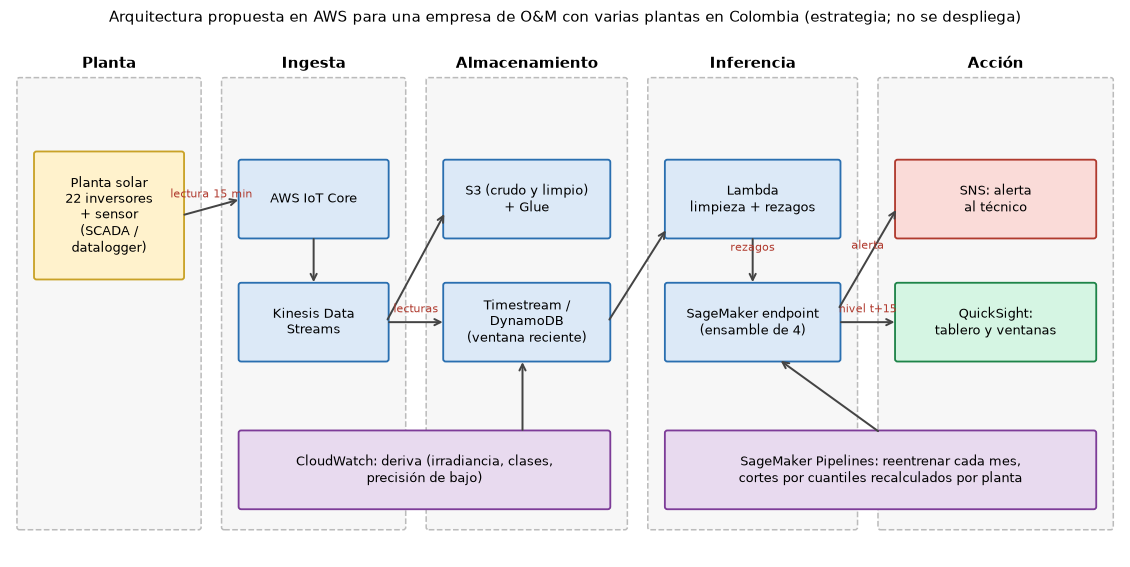

In [95]:
import matplotlib.patches as mp
fig, ax = plt.subplots(figsize=(13, 6.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 6.4); ax.axis('off')
def caja(x, y, w, h, texto, fc='#dce9f7', ec='#2a6fb0', fs=8.5):
    ax.add_patch(mp.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.03', fc=fc, ec=ec, lw=1.2)); ax.text(x + w / 2, y + h / 2, texto, ha='center', va='center', fontsize=fs)
def capa(x, w, titulo):
    ax.add_patch(mp.FancyBboxPatch((x, .35), w, 5.45, boxstyle='round,pad=0.03', fc='#f7f7f7', ec='#bbbbbb', lw=1, ls='--')); ax.text(x + w / 2, 5.95, titulo, ha='center', fontsize=9.5, weight='bold')
def flecha(p, q, texto='', dy=.12):
    ax.annotate('', xy=q, xytext=p, arrowprops=dict(arrowstyle='->', color='#444', lw=1.3, shrinkA=2, shrinkB=2))
    if texto: ax.text((p[0] + q[0]) / 2, (p[1] + q[1]) / 2 + dy, texto, ha='center', fontsize=7.5, color='#b03a2e')
capa(.1, 2.1, 'Planta'); capa(2.5, 2.1, 'Ingesta'); capa(4.9, 2.3, 'Almacenamiento'); capa(7.5, 2.4, 'Inferencia'); capa(10.2, 2.7, 'Acción')
caja(.3, 3.4, 1.7, 1.5, 'Planta solar\n22 inversores\n+ sensor\n(SCADA /\ndatalogger)', '#fff2cc', '#c9a227')
caja(2.7, 3.9, 1.7, .9, 'AWS IoT Core'); caja(2.7, 2.4, 1.7, .9, 'Kinesis Data\nStreams')
caja(5.1, 3.9, 1.9, .9, 'S3 (crudo y limpio)\n+ Glue'); caja(5.1, 2.4, 1.9, .9, 'Timestream /\nDynamoDB\n(ventana reciente)')
caja(7.7, 3.9, 2.0, .9, 'Lambda\nlimpieza + rezagos'); caja(7.7, 2.4, 2.0, .9, 'SageMaker endpoint\n(ensamble de 4)')
caja(10.4, 3.9, 2.3, .9, 'SNS: alerta\nal técnico', '#fadbd8', '#b03a2e'); caja(10.4, 2.4, 2.3, .9, 'QuickSight:\ntablero y ventanas', '#d5f5e3', '#1e8449')
caja(2.7, .6, 4.3, .9, 'CloudWatch: deriva (irradiancia, clases,\nprecisión de bajo)', '#e8daef', '#7d3c98'); caja(7.7, .6, 5.0, .9, 'SageMaker Pipelines: reentrenar cada mes,\ncortes por cuantiles recalculados por planta', '#e8daef', '#7d3c98')
flecha((2.0, 4.15), (2.7, 4.35), 'lectura 15 min'); flecha((3.55, 3.9), (3.55, 3.3)); flecha((4.4, 2.85), (5.1, 4.2)); flecha((4.4, 2.85), (5.1, 2.85), 'lecturas')
flecha((7.0, 2.85), (7.7, 4.0)); flecha((8.7, 3.9), (8.7, 3.3), 'rezagos'); flecha((9.7, 2.85), (10.4, 2.85), 'nivel t+15'); flecha((9.7, 3.0), (10.4, 4.25), 'alerta')
flecha((6.0, 1.5), (6.0, 2.4), '', 0); flecha((10.2, 1.5), (9.0, 2.4), '', 0); 
ax.set_title('Arquitectura propuesta en AWS para una empresa de O&M con varias plantas en Colombia (estrategia; no se despliega)', fontsize=10)
fig.savefig('figuras/f6_arquitectura_aws.png', dpi=200, bbox_inches='tight'); plt.show()

El diagrama separa tres ritmos distintos. La ingesta y el almacenamiento corren de forma continua, con una lectura cada 15 minutos por planta; la inferencia es la parte liviana (limpieza, rezagos y cuatro modelos, que responden de inmediato); y la operación, con la vigilancia de la deriva y el reentrenamiento mensual, es lo que evita que el modelo envejezca en silencio. La alerta al técnico sale directamente de la inferencia y no del tablero, porque es lo que necesita respuesta rápida.

## 6.3 Simulación local del flujo en tiempo real
### 6.3.1 `predecir_nivel(ventana)`
Es la función que ejecutaría el endpoint: recibe las últimas lecturas ya limpias de la planta (la potencia de la planta con la corrección de inversores ausentes, el sensor y los inversores en cero), calcula los rezagos y la hora del instante siguiente y devuelve el nivel y las probabilidades del ensamble. Para probarla, el ensamble se reajusta con el entrenamiento (mismas rejillas) y se comprueba que da las mismas predicciones que `pred_te`.

In [96]:
def ajustar_ensamble(tr_, y_tr_, cols):
    """Ajusta los modelos del ensamble final (mismas rejillas y validación cruzada que `ensamble_predecir`) y devuelve los estimadores."""
    modelos = []
    for nom in ENS_MODELOS:
        est, rej = ENS_REJILLAS[nom]
        modelos.append(GridSearchCV(clone(est), rej, cv=cv, scoring='f1_macro', n_jobs=6).fit(tr_[cols], y_tr_).best_estimator_)
    return modelos
ENS_FINAL = ajustar_ensamble(train_d, ytr, COLS_D)

def predecir_nivel(ventana, modelos=None):
    """Nivel (bajo, medio o alto) del instante siguiente al último de `ventana`, con las probabilidades del ensamble.
    `ventana`: DataFrame indexado por DATE_TIME con AC_PLANTA_KW, las variables del sensor y n_inv_cero (al menos la última hora)."""
    modelos = ENS_FINAL if modelos is None else modelos
    t1 = ventana.index[-1] + pd.Timedelta('15min')
    fila = {'DATE_TIME': t1, 'hora': t1.hour + t1.minute / 60}
    for col in ['AC_PLANTA_KW'] + COLS_SENSOR:
        for p in LAGS: fila[f'{col}_lag{p}'] = ventana[col].get(t1 - pd.Timedelta(minutes=15 * p), np.nan)
    fila['n_inv_cero_lag1'] = ventana['n_inv_cero'].get(t1 - pd.Timedelta('15min'), np.nan)
    X = agregar_clim(agregar_hora(pd.DataFrame([fila])), clim_tr)
    if X[COLS_D].isna().any(axis=None):
        return None                                                     # sin historia suficiente: se usaría persistencia o climatología
    P = np.mean([probs3(m, X[COLS_D]) for m in modelos], axis=0)[0]
    return {'instante': t1, 'nivel': ETIQ[int(P.argmax())], 'prob_bajo': float(P[0]), 'probs': P}

print('Estimadores del ensamble final:', [type(m).__name__ for m in ENS_FINAL])

Estimadores del ensamble final: ['RandomForestClassifier', 'Pipeline', 'Pipeline', 'Pipeline']


### 6.3.2 Simulación del flujo
Se recorre el conjunto de prueba en orden temporal, una lectura cada vez (como llegaría de Kinesis). Para cada instante se llama a `predecir_nivel` con la última hora de lecturas, se anuncia el nivel del instante siguiente y, cuando llega la lectura real, se generan las alertas:
- Ventana de mantenimiento sugerida si se predijo bajo.
- (a) Desvío: se predijo medio o alto y el real fue bajo. Causa probable: si hay inversores en cero, se revisa el MPPT, la comunicación o las protecciones del inversor; si no los hay, la suciedad de los paneles [5][6], las sombras [7], los strings desconectados o con desajuste [8], o el robo o vandalismo.
- (b) Inversores en cero con sol: se lista cuáles.

In [97]:
Dv = ctx['D'].set_index('DATE_TIME')[['AC_PLANTA_KW'] + COLS_SENSOR + ['n_inv_cero']]
nombre_inv = {col: f'inv{i + 1:02d}' for i, col in enumerate(ctx['inv'])}
ac_total = ctx['ac']
filas_ev = []
for k_, t1 in enumerate(test.DATE_TIME):                     # llega la lectura de t0 y se anuncia el nivel de t1
    t0 = t1 - pd.Timedelta('15min')
    r_ = predecir_nivel(Dv.loc[t0 - pd.Timedelta('1h'):t0])
    real_ = ETIQ[yte[k_]]; ceros = [nombre_inv[col] for col in ctx['inv'] if ac_total.at[t1, col] == 0] if t1 in ac_total.index else []
    alerta, causa = '', ''
    if r_ is not None and r_['nivel'] in ('medio', 'alto') and real_ == 'bajo':
        alerta = 'desvío: se esperaba ' + r_['nivel'] + ' y fue bajo'
        causa = ('inversores en cero (' + ', '.join(ceros) + '): revisar MPPT, comunicación o protecciones' if ceros else
                 'sin inversores en cero: revisar suciedad, sombras, strings o robo')
    if ceros:
        alerta = (alerta + ' | ' if alerta else '') + f'{len(ceros)} inversores en cero con sol'
        causa = causa or 'revisar los inversores en cero: ' + ', '.join(ceros)
    filas_ev.append({'instante': t1, 'predicho': r_['nivel'] if r_ else None, 'prob_bajo': r_['prob_bajo'] if r_ else np.nan, 'real': real_,
                     'ventana_mantenimiento': bool(r_ and r_['nivel'] == 'bajo'), 'n_inv_cero': len(ceros), 'alerta': alerta, 'causa_probable': causa})
eventos = pd.DataFrame(filas_ev)
igual = (eventos.predicho.to_numpy() == np.array([ETIQ[i] for i in pred_te])).mean()
print(f'Instantes simulados: {len(eventos)} | coinciden con las predicciones por lotes (pred_te): {100 * igual:.1f} %')
print(f'Instantes con ventana de mantenimiento sugerida: {int(eventos.ventana_mantenimiento.sum())} | de ellos, realmente bajo: {int((eventos.ventana_mantenimiento & (eventos.real == "bajo")).sum())}')
print(f'Alertas de desvío (predicho medio/alto y real bajo): {int(eventos.alerta.str.contains("desvío").sum())} | con inversores en cero: {int((eventos.alerta.str.contains("desvío") & (eventos.n_inv_cero > 0)).sum())}')
print(f'Instantes con inversores en cero con sol: {int((eventos.n_inv_cero > 0).sum())}')
pd.set_option('display.max_colwidth', 90); display(eventos[eventos.alerta != ''].assign(instante=lambda t: t.instante.dt.strftime('%d-%m %H:%M')).head(15).round(2))

Instantes simulados: 340 | coinciden con las predicciones por lotes (pred_te): 100.0 %
Instantes con ventana de mantenimiento sugerida: 156 | de ellos, realmente bajo: 136
Alertas de desvío (predicho medio/alto y real bajo): 29 | con inversores en cero: 9
Instantes con inversores en cero con sol: 64


,instante,predicho,prob_bajo,real,ventana_mantenimiento,n_inv_cero,alerta,causa_probable
11,11-06 09:30,medio,0.21,bajo,False,0,desvío: se esperaba medio y fue bajo,"sin inversores en cero: revisar suciedad, sombras, strings o robo"
21,11-06 12:00,alto,0.03,bajo,False,22,desvío: se esperaba alto y fue bajo | 22 inversores en cero con sol,"inversores en cero (inv01, inv02, inv03, inv04, inv05, inv06, inv07, inv08, inv09, inv..."
31,11-06 14:30,medio,0.27,bajo,False,0,desvío: se esperaba medio y fue bajo,"sin inversores en cero: revisar suciedad, sombras, strings o robo"
35,11-06 15:30,medio,0.12,bajo,False,0,desvío: se esperaba medio y fue bajo,"sin inversores en cero: revisar suciedad, sombras, strings o robo"
58,12-06 09:15,medio,0.15,bajo,False,0,desvío: se esperaba medio y fue bajo,"sin inversores en cero: revisar suciedad, sombras, strings o robo"
61,12-06 10:00,medio,0.45,bajo,False,0,desvío: se esperaba medio y fue bajo,"sin inversores en cero: revisar suciedad, sombras, strings o robo"
73,12-06 13:00,medio,0.21,bajo,False,0,desvío: se esperaba medio y fue bajo,"sin inversores en cero: revisar suciedad, sombras, strings o robo"
75,12-06 13:30,medio,0.06,medio,False,5,5 inversores en cero con sol,"revisar los inversores en cero: inv01, inv04, inv08, inv11, inv16"
105,13-06 08:30,medio,0.12,bajo,False,0,desvío: se esperaba medio y fue bajo,"sin inversores en cero: revisar suciedad, sombras, strings o robo"
108,13-06 09:15,medio,0.03,bajo,False,0,desvío: se esperaba medio y fue bajo,"sin inversores en cero: revisar suciedad, sombras, strings o robo"


La función da las mismas predicciones que el cálculo por lotes, así que el flujo en tiempo real y la evaluación miden lo mismo. Las ventanas sugeridas son, en su gran mayoría, instantes realmente bajos. De las alertas de desvío, solo una parte menor coincide con inversores en cero, que es la única causa que los datos permiten identificar; el resto no tiene explicación en los datos. Las demás causas (suciedad, sombras, strings, robo) no se pueden confirmar con estos datos: la alerta las propone como lista de revisión para el técnico, no como diagnóstico.

### 6.3.3 Tablero simulado
Potencia real de la planta con el fondo coloreado por el nivel predicho, las ventanas de mantenimiento marcadas y las alertas, para dos días de la prueba (el de más alertas y el de menos).

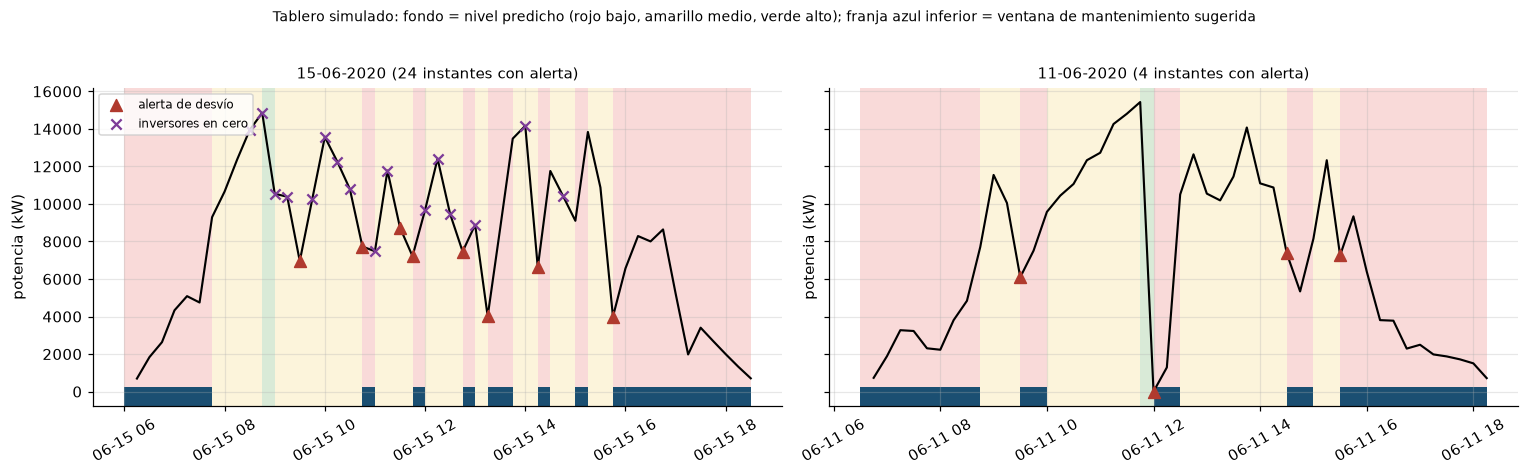

In [98]:
eventos['fecha'] = eventos.instante.dt.normalize()
n_alertas = eventos.groupby('fecha').apply(lambda g: int((g.alerta != '').sum()), include_groups=False)
dias_dash = [n_alertas.idxmax(), n_alertas.idxmin()]
col_n = {'bajo': '#e45756', 'medio': '#f2cf5b', 'alto': '#54a24b'}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for a, dia in zip(ax, dias_dash):
    g = eventos[eventos.fecha == dia]; kw = test.set_index('DATE_TIME').loc[g.instante, 'AC_PLANTA_KW']
    for _, f in g.dropna(subset=['predicho']).iterrows():
        a.axvspan(f.instante - pd.Timedelta('15min'), f.instante, color=col_n[f.predicho], alpha=.22, lw=0)
        if f.ventana_mantenimiento: a.axvspan(f.instante - pd.Timedelta('15min'), f.instante, ymin=0, ymax=.06, color='#1b4f72', lw=0)
    a.plot(g.instante, kw.values, color='k', lw=1.4)
    dev = g[g.alerta.str.contains('desvío')]; cero = g[(g.n_inv_cero > 0) & ~g.alerta.str.contains('desvío')]
    a.scatter(dev.instante, kw.loc[dev.instante], marker='^', s=60, color='#b03a2e', zorder=3, label='alerta de desvío')
    a.scatter(cero.instante, kw.loc[cero.instante], marker='x', s=45, color='#7d3c98', zorder=3, label='inversores en cero')
    a.set_title(f'{dia:%d-%m-%Y} ({int(n_alertas[dia])} instantes con alerta)', fontsize=10); a.set_ylabel('potencia (kW)'); a.tick_params(axis='x', rotation=30)
ax[0].legend(loc='upper left', fontsize=8)
fig.suptitle('Tablero simulado: fondo = nivel predicho (rojo bajo, amarillo medio, verde alto); franja azul inferior = ventana de mantenimiento sugerida', fontsize=9, y=1.02)
fig.tight_layout(); fig.savefig('figuras/f6_tablero_simulado.png', dpi=200, bbox_inches='tight'); plt.show()

El tablero muestra lo que vería un gerente de O&M. En el día con más alertas (a la izquierda), casi todas son inversores en cero repartidos por las horas centrales: la potencia real oscila bruscamente mientras el modelo, que solo conoce el pasado, anuncia niveles medios; es el tipo de día en que un pronóstico puro no basta y la alerta sí. En el día de menos alertas (a la derecha), el fondo predicho acompaña bien la curva real y la franja azul marca justo las horas de amanecer y atardecer, que son las ventanas naturales de mantenimiento.

## 6.4 Control y mantenimiento del modelo
- Qué vigilar (CloudWatch): la distribución de la irradiancia y de las clases (si cambia la estación o la planta, los cortes dejan de representar "bajo, medio, alto"), la precisión de bajo semanal frente a la de la persistencia y la fracción de instantes con inversores en cero.
- Cuándo expira el modelo: cuando la precisión de bajo queda por debajo de la de la persistencia dos semanas seguidas, o cuando la distribución de la irradiancia se aleja de la de entrenamiento (criterio del equipo, sin respaldo en las fuentes: es un punto de partida a calibrar).
- Reentrenamiento: mensual con SageMaker Pipelines, con los mismos pasos de este análisis (limpieza, rezagos, cortes por cuantiles de entrenamiento, ensamble); los cortes se recalculan por planta.
- Si expira: se vuelve a la persistencia o a la combinación persistencia-climatología hasta reentrenar, y se avisa al gerente de O&M.

## 6.5 Contingencias
| Situación | Qué se hace |
|---|---|
| Caída de comunicaciones | La ventana de rezagos queda incompleta: `predecir_nivel` no responde y se usa la última predicción válida con una marca de "sin dato" |
| Sensor dañado o congelado | Se detecta con la prueba de lecturas congeladas (2.4.9); se usa un modelo solo con la historia de la potencia (conjunto A) |
| Planta nueva sin historia | Persistencia y climatología hasta tener al menos unas semanas de datos para calcular cortes y entrenar |
| Inversores ausentes | Se corrige la suma con el aporte estimado (3.2.1) |

## 6.6 Tabla-resumen de decisiones
Cada constante, su valor (leído de la variable), dónde se decidió, la evidencia y la fuente. "Supuesto del equipo" significa que ninguna fuente fija el valor y que la razón está en la sección indicada.

In [99]:
dec = [('SEMILLA', '0.3', 'reproducibilidad', 'no es una decisión analítica'),
       ('UMBRAL_IRR', '3.1.1', 'histograma y tabla de potencia por irradiancia (2.4.11)', 'datos (IEC 61724-1 no fija el valor)'),
       ('LAGS', '3.1.2', 'ACF y PACF (2.3.5)', 'práctica de ACF/PACF [Cantillo-Luna et al.]; la ventana de 1 h es supuesto del equipo'),
       ('FRAC_DIAS_TRAIN', '3.1.4', 'partición cronológica frente a aleatoria', 'práctica en series de tiempo; la proporción es supuesto del equipo'),
       ('TRATAR_INCOMPLETOS', '3.2.1', 'patrones de ausencia y validación de la corrección', 'IEC 61724-1, cl. 15.3'),
       ('INTERPOLAR_AUSENTES', '3.2.2', 'error de interpolación y cambio de clase', 'supuesto del equipo respaldado por la prueba'),
       ('TRATAR_PLANTA_EN_CERO', '3.2.3', 'episodios (2.4.7) y niveles con cero o con vecinos', 'IEC 61724-1, cl. 15.3'),
       ('HORA_VAR', '3.3.3', 'comparación de tres formas de la hora', 'supuesto del equipo (diferencias pequeñas)'),
       ('WF_DIA_INICIO', '4.2.1', 'diseño de la evaluación día a día', 'supuesto del equipo'),
       ('WF_DIA_CONFIRMACION', '4.2.1', 'diseño de la evaluación día a día', 'supuesto del equipo'),
       ('N_BOOT', '4.2.1', 'bootstrap de días', 'supuesto del equipo'),
       ('RECALL_MIN_BAJO', '4.2.4', 'razón de negocio (ventanas aprovechadas)', 'supuesto del equipo'),
       ('TOL_EMPATE', '4.2.4', 'diferencia indistinguible con pocos días', 'supuesto del equipo'),
       ('MODELO_INDIVIDUAL', '4.3.3', 'regla de selección sobre 51 ajustes', 'regla de 4.2.4'),
       ('ENS_MODELOS', '4.4.3', 'combinatoria y selección anidada', 'Clemen, Dietterich, Smith y Wallis, Cawley y Talbot, REFORMS (con desviación declarada)'),
       ('USAR_UMBRAL', '4.4.4', 'comparación con y sin umbral', 'supuesto del equipo (decisión de negocio)'),
       ('CALIBRAR', '4.4.4', 'comparación con y sin Platt', 'supuesto del equipo (no mejoró)'),
       ('TAU_MODO', '4.4.4', 'umbral elegido con predicciones fuera de muestra', 'supuesto del equipo'),
       ('TAU_FIJO', '4.4.4', 'solo se usa si TAU_MODO = "fijo"', 'supuesto del equipo'),
       ('K_MAX', '4.5', 'tamaño del entrenamiento (27 días)', 'supuesto del equipo'),
       ('K_ELEGIDO', '4.5', 'codo y silhouette', 'Santiago et al. (agrupar días por perfil); decisión del equipo'),
       ('HORAS_CENTRALES', '5.1.1', 'precisión de bajo por hora', 'supuesto del equipo'),
       ('PRECIO_COP_KWH', '5.1.4', 'ejemplo en pesos', 'supuesto del equipo (no es un dato)'),
       ('EJECUTAR_WALK_FORWARD', '4.2.1', 'interruptor de cómputo', 'no es una decisión analítica')]
globales = globals()
valor = lambda n: str((MEJOR_NOMBRE, MEJOR_CONJ)) if n == 'MODELO_INDIVIDUAL' else str(globales[n])
tabla_decisiones = pd.DataFrame([{'constante': n, 'valor': valor(n), 'sección': s, 'evidencia': e, 'fuente': f} for n, s, e, f in dec])
pd.set_option('display.max_colwidth', 110); display(tabla_decisiones)
tabla_decisiones.to_csv('figuras/res_decisiones.csv', index=False, encoding='utf-8-sig')

,constante,valor,sección,evidencia,fuente
0,SEMILLA,42,0.3,reproducibilidad,no es una decisión analítica
1,UMBRAL_IRR,0.02,3.1.1,histograma y tabla de potencia por irradiancia (2.4.11),datos (IEC 61724-1 no fija el valor)
2,LAGS,"(1, 2, 4)",3.1.2,ACF y PACF (2.3.5),práctica de ACF/PACF [Cantillo-Luna et al.]; la ventana de 1 h es supuesto del equipo
3,FRAC_DIAS_TRAIN,0.8,3.1.4,partición cronológica frente a aleatoria,práctica en series de tiempo; la proporción es supuesto del equipo
4,TRATAR_INCOMPLETOS,corregir,3.2.1,patrones de ausencia y validación de la corrección,"IEC 61724-1, cl. 15.3"
5,INTERPOLAR_AUSENTES,False,3.2.2,error de interpolación y cambio de clase,supuesto del equipo respaldado por la prueba
6,TRATAR_PLANTA_EN_CERO,mantener,3.2.3,episodios (2.4.7) y niveles con cero o con vecinos,"IEC 61724-1, cl. 15.3"
7,HORA_VAR,dist_mediodia,3.3.3,comparación de tres formas de la hora,supuesto del equipo (diferencias pequeñas)
8,WF_DIA_INICIO,14,4.2.1,diseño de la evaluación día a día,supuesto del equipo
9,WF_DIA_CONFIRMACION,20,4.2.1,diseño de la evaluación día a día,supuesto del equipo


## 6.7 Cierre
### 6.7.1 Conclusiones y límites
Qué se logró. Un flujo completo y repetible: datos, limpieza con evidencia, exploración, 17 modelos candidatos, ensamble, evaluación día a día, costo, tipos de día y estrategia de despliegue con una simulación local. El modelo final es un ensamble de cuatro modelos que anuncia el nivel de la planta 15 minutos antes y alimenta alertas de mantenimiento y de desvío.

Qué tan bueno es. Mejora a "repetir lo último" (la persistencia) y a la combinación persistencia-climatología en F1 macro y kappa, con respaldo estadístico, aunque la ventaja sobre la combinación es pequeña. Es lo mejor que se logró con estos datos: casi toda la información está en la potencia reciente y en la hora típica del día. El valor práctico está en reducir los falsos bajo y en señalar desvíos, no en ahorrar más pesos que una regla de horario.

Límites.
- Es una sola planta y un solo mes de otro país: pocos días de prueba y más nublados que los de entrenamiento. Las cifras miden el método, no el desempeño en una planta colombiana.
- La composición del ensamble se eligió entre 9 384 combinaciones con estos mismos días y se adoptó después de ver los resultados (4.4.3); la ventaja real es menor que la medida.
- La clase alto casi no aparece en la prueba y sus métricas son inestables.
- La mejora en precisión de bajo se paga con recall, y el costo en pesos usa un precio y una parte intervenida de la planta que son supuestos.
- No hay registro de mantenimientos ni de fallas: las alertas proponen causas, no las confirman.
- Con pocos días el silhouette de K-Means es inestable.

Qué sigue. Más meses y datos de otras plantas (idealmente colombianas) para repetir la comparación con las mismas celdas; incorporar pronósticos de irradiación; revisar los terciles por temporada; fijar el umbral con los costos reales de la empresa y validar las alertas contra registros de mantenimiento.

### 6.7.2 Recomendaciones para proyectos futuros y balance
- Reservar desde el inicio días de selección y días de reporte: evita el sesgo de selección que aquí solo se pudo medir después.
- Decidir la métrica de negocio antes de modelar y compararla siempre con la persistencia.
- Documentar cada decisión con su evidencia (como en este cuaderno) facilita reentrenar con datos nuevos.
- Balance del proyecto: los modelos sueltos casi no superaron a la persistencia, la corrección de los inversores ausentes sí cambió de forma apreciable el resultado y la evaluación día a día evitó sobrevender el ensamble.

### 6.7.3 Referencias
Se citan en estilo IEEE por orden de aparición. Las fuentes están en la bibliografía local del proyecto o se leyeron en su resumen o introducción.

[1] IBM, "IBM SPSS Modeler CRISP-DM Guide," IBM Corporation.

[2] Congreso de la República de Colombia, "Ley 1715 de 2014: por medio de la cual se regula la integración de las energías renovables no convencionales al Sistema Energético Nacional," 2014.

[3] Congreso de la República de Colombia, "Ley 2099 de 2021: por medio de la cual se dictan disposiciones para la transición energética, la dinamización del mercado energético, la reactivación económica del país y se dictan otras disposiciones," 2021.

[4] XM S.A. E.S.P., "Capacidad solar en operación y en pruebas (SIMEM)," serie anual 2021-2026, archivo capacidad_solar_simem.csv (Otros_Datos).

[5] J. D. Diazgranados-Garzón et al., "Analysis of the soiling effect on solar-panel power efficiency in the Colombian Caribbean region," Revista Facultad de Ingeniería Universidad de Antioquia, n.º 97, pp. 22-29, 2020.

[6] S. C. Silva Costa et al., "Impact of soiling on Si and CdTe PV modules: case study in different Brazil climate zones," Energy Conversion and Management: X, vol. 10, art. 100084, 2021, doi: 10.1016/j.ecmx.2021.100084.

[7] Yaouba et al., "An experimental and case study on the evaluation of the partial shading impact on PV module performance operating under the Sudano-Sahelian climate of Cameroon," Frontiers in Energy Research, vol. 10, art. 924285, 2022, doi: 10.3389/fenrg.2022.924285.

[8] A. Mäki y S. Valkealahti, "Power losses in long string and parallel-connected short strings of series-connected silicon-based photovoltaic modules due to partial shading conditions," IEEE Trans. Energy Conversion, vol. 27, n.º 1, pp. 173-183, 2012.

[9] "Solar Power Generation Data," conjunto de datos público en Kaggle: generación por inversor y sensor de la Planta 2, cada 15 min, 15-may a 17-jun de 2020.

[10] G. C. Cawley y N. L. C. Talbot, "On over-fitting in model selection and subsequent selection bias in performance evaluation," Journal of Machine Learning Research, vol. 11, pp. 2079-2107, 2010.

[11] J. Good y J. X. Johnson, "Impact of inverter loading ratio on solar photovoltaic system performance," Applied Energy, vol. 177, pp. 475-486, 2016, doi: 10.1016/j.apenergy.2016.05.134.

[12] S. Theocharides, G. Makrides y G. E. Georghiou, "PV generation forecasting utilizing a classification-only approach," EPJ Photovoltaics, vol. 15, art. 12, 2024, doi: 10.1051/epjpv/2024011.

[13] E. Skoplaki y J. A. Palyvos, "On the temperature dependence of photovoltaic module electrical performance: a review of efficiency/power correlations," Solar Energy, vol. 83, pp. 614-624, 2009.

[14] S. Cantillo-Luna, R. Moreno-Chuquen, D. Celeita y G. Anders, "Deep and machine learning models to forecast photovoltaic power generation," Energies, vol. 16, art. 4097, 2023, doi: 10.3390/en16104097.

[15] IEC 61724-1:2021, "Photovoltaic system performance - Part 1: Monitoring," Ed. 2.0, International Electrotechnical Commission, 2021, cláusula 15.3.

[16] S. Kapoor et al., "REFORMS: consensus-based recommendations for machine-learning-based science," Science Advances, vol. 10, n.º 18, art. eadk3452, 2024, doi: 10.1126/sciadv.adk3452.

[17] R. T. Clemen, "Combining forecasts: a review and annotated bibliography," International Journal of Forecasting, vol. 5, pp. 559-583, 1989, doi: 10.1016/0169-2070(89)90012-5.

[18] X. Wang, R. J. Hyndman, F. Li y Y. Kang, "Forecast combinations: an over 50-year review," International Journal of Forecasting, vol. 39, n.º 4, pp. 1518-1547, 2023, doi: 10.1016/j.ijforecast.2022.11.005.

[19] R. Zhu, W. Guo y X. Gong, "Short-term photovoltaic power output prediction based on k-fold cross-validation and an ensemble model," Energies, vol. 12, n.º 7, art. 1220, 2019, doi: 10.3390/en12071220.

[20] T. G. Dietterich, "An experimental comparison of three methods for constructing ensembles of decision trees: bagging, boosting, and randomization," Machine Learning, vol. 40, pp. 139-157, 2000.

[21] J. Smith y K. F. Wallis, "A simple explanation of the forecast combination puzzle," Oxford Bulletin of Economics and Statistics, vol. 71, n.º 3, pp. 331-355, 2009, doi: 10.1111/j.1468-0084.2008.00541.x.

[22] I. Santiago, J. L. Esquivel-Martin, D. Trillo-Montero, R. J. Real-Calvo y V. Pallarés-López, "Classification of daily irradiance profiles and the behaviour of photovoltaic plant elements: the effects of cloud enhancement," Applied Sciences, vol. 11, art. 5230, 2021, doi: 10.3390/app11115230.

## 6.8 Exportación de cifras para el informe
Las cifras y las tablas del informe se generan desde estos archivos para que cada número tenga origen en una celda. Las claves se mantienen estables para que el informe las lea sin cambios, y se agregan las del modelado ampliado (17 modelos, combinatoria y simulación).

In [100]:
import json, sys
RES_INF = {
    'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__, 'sklearn': sklearn.__version__,
    'xgboost': xgboost.__version__, 'matplotlib': matplotlib.__version__,
    'nfilas': len(ds), 'nentrena': len(train), 'nprueba': len(test), 'ndiasentr': len(dias_train), 'ndiasprueba': len(dias_test),
    'cortebm': cortes[0], 'cortema': cortes[1], 'hpico': H_PICO, 'umbral': UMBRAL_IRR,
    'nausentes': n_aus, 'nesperados': esperados, 'nregfaltan': reg_falt, 'pctregfaltan': 100 * reg_falt / (esperados * N_INV),
    'nincompletos': n_sol_inc, 'nsol': n_sol, 'pctincompletos': 100 * n_sol_inc / n_sol,
    'errcorrmin': float(val_corr['error abs. corregido %'].min()), 'errcorrmax': float(val_corr['error abs. corregido %'].max()),
    'errsincorrmin': float(val_corr['error abs. sin corregir %'].min()), 'errsincorrmax': float(val_corr['error abs. sin corregir %'].max()),
    'nceros': n_ceros, 'nregsol': reg_sol, 'pctceros': 100 * n_ceros / reg_sol, 'ntodocero': int(todos_cero.sum()),
    'errinterp': err_interp, 'cambiainterp': cambia_interp,
    'pbajotest': float(tabla_cl.loc['bajo', 'prueba (%)']), 'pmediotest': float(tabla_cl.loc['medio', 'prueba (%)']),
    'paltotest': float(tabla_cl.loc['alto', 'prueba (%)']), 'naltotest': int(tabla_cl.loc['alto', 'prueba (filas)']),
    'mejormodelo': MEJOR_NOMBRE, 'mejorconj': MEJOR_CONJ, 'mejorparams': str(fila_mej['mejores parámetros']),
    'mejorcv': float(fila_mej.cv_f1_macro), 'mejortrain': float(fila_mej.train_f1_macro),
    'mejorf1': float(fila_mej.test_f1_macro), 'mejoracc': float(fila_mej.test_accuracy),
    'persf1': float(base_df.loc[2, 'test_f1_macro']), 'persacc': float(base_df.loc[2, 'test_accuracy']),
    'dummyclase': CLASE_DUMMY, 'dummyf1': float(base_df.loc[0, 'test_f1_macro']), 'dummyacc': float(base_df.loc[0, 'test_accuracy']),
    'f1A': float(mej_A), 'f1B': float(mej_B), 'f1C': float(mej_C), 'aporteclima': float(p1['C − A (aporte del clima)'].mean()),
    'K': int(K), 'silh': float(sil[list(ks).index(K)]), 'nproyectos': 0,
    'corrpot': float(cp['AC_PLANTA_KW_lag1']), 'corrirr': float(cp['IRRADIATION_lag1']),
    'habA': float(hab.iloc[2]), 'habB': float(hab.iloc[3]), 'habC': float(hab.iloc[4]),
    'horaelegida': HORA_ELEGIDA, 'cm': cm.tolist(),
}
mapa_niv = {'bajo': 0, 'medio': 1, 'alto': 2}
sobre = te[te.pred.map(mapa_niv) > te.real.map(mapa_niv)]                      # el modelo anunció un nivel más alto que el real
RES_INF.update({'nsobre': int(len(sobre)), 'invsobre': float(sobre.n_inv_cero.mean()),
                'invbajook': float(te[(te.real == 'bajo') & (te.pred == 'bajo')].n_inv_cero.mean()),
                'irrAltoOk': float(cond.loc[('alto', 'alto'), 'IRRADIATION_lag1']), 'pAltoOk': float(cond.loc[('alto', 'alto'), 'AC_PLANTA_KW_lag1']),
                'irrAltoMed': float(cond.loc[('alto', 'medio'), 'IRRADIATION_lag1']), 'pAltoMed': float(cond.loc[('alto', 'medio'), 'AC_PLANTA_KW_lag1'])})
_pb = prec_bajo(yte, pred_te, ENERGIA)
RES_INF.update({'finalmodelo': FINAL_NOMBRE, 'finalf1': float(f1_score(yte, pred_te, average='macro')), 'finalacc': float(accuracy_score(yte, pred_te)),
                'finalkappa': float(cohen_kappa_score(yte, pred_te)), 'finalprecbajo': float(_pb['precisión de bajo']),
                'finalrecallbajo': float(_pb['recall de bajo (ventanas aprovechadas)']), 'finalfalsosbajo': int(_pb['falsos bajo']),
                'finalvecesbajo': int(_pb['veces que dijo bajo']), 'finaltau': float(ens_80['tau']), 'finalusaumbral': bool(USAR_UMBRAL), 'wconv': float(w_conv),
                'irrtr': float(h_dia[es_tr].mean()), 'irrte': float(h_dia[~es_tr].mean()), 'etr': float(e_dia[es_tr].mean()), 'ete': float(e_dia[~es_tr].mean()),
                'rend0': float(loc['kW por kW/m²'].iloc[0]), 'rend1': float(loc['kW por kW/m²'].iloc[-1]),
                'tm0': float(loc['temp. módulo media (°C)'].iloc[0]), 'tm1': float(loc['temp. módulo media (°C)'].iloc[-1]),
                'caidaobs': float(caida_obs), 'caidatemp': float(caida_temp)})
def hojas(est, cols):
    """Reglas del árbol: una por hoja, con las condiciones, el % de instantes de entrenamiento, el nivel que predice y su pureza."""
    t = est.tree_; out = []
    def rec(n, cond):
        if t.children_left[n] == -1:
            v = t.value[n][0] / t.value[n][0].sum()
            out.append({'condiciones': cond, 'pct': float(100 * t.n_node_samples[n] / t.n_node_samples[0]),
                        'nivel': ETIQ[int(v.argmax())], 'pureza': float(100 * v.max())})
            return
        f, thr = cols[t.feature[n]], float(t.threshold[n])
        rec(t.children_left[n], cond + [[f, '<=', thr]]); rec(t.children_right[n], cond + [[f, '>', thr]])
    rec(0, []); return out
RES_INF['reglas'] = hojas(arb_est, arb_cols)
json.dump(RES_INF, open('figuras/resultados.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
res.assign(**{'mejores parámetros': res['mejores parámetros'].astype(str)}).to_csv('figuras/res_modelos.csv', index=False)
base_df.to_csv('figuras/res_base.csv', index=False)
por_grupo.to_csv('figuras/res_grupos.csv'); sens.to_csv('figuras/res_sensibilidad.csv'); cent.to_csv('figuras/res_centroides.csv')
tabla_costo.to_csv('figuras/res_costo_bajo.csv', index=False); tabla_iec.to_csv('figuras/res_iec153.csv', index=False)
tabla_pesos.to_csv('figuras/res_pesos.csv', index=False)
print('Exportado a figuras/: resultados.json, res_modelos.csv, res_base.csv, res_grupos.csv, res_sensibilidad.csv, res_centroides.csv')

Exportado a figuras/: resultados.json, res_modelos.csv, res_base.csv, res_grupos.csv, res_sensibilidad.csv, res_centroides.csv


In [101]:
RES_INF = json.load(open('figuras/resultados.json', encoding='utf-8'))
RES_INF.update({'ncandidatos': len(COMPETIDORES), 'najustes': int(len(res)), 'ncombinaciones': int(len(COMB)), 'ndiaswf': int(len(DIAS_WF)),
                'psimcoincide': float(100 * igual), 'nsimulados': int(len(eventos)), 'nventanas': int(eventos.ventana_mantenimiento.sum()),
                'nalertasdesvio': int(eventos.alerta.str.contains('desvío').sum()), 'ninstceroscon': int((eventos.n_inv_cero > 0).sum()),
                'ensmodelos': ENS_MODELOS, 'percentilens': {k: float((COMB[k] <= fila_ens[k]).mean()) for k in ['F1 des', 'F1 conf', 'F1 des2', 'F1 conf2']}})
json.dump(RES_INF, open('figuras/resultados.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
eventos.to_csv('figuras/res_simulacion.csv', index=False, encoding='utf-8-sig')
print('Exportado: resultados.json, res_simulacion.csv, res_decisiones.csv, res_combinatoria.csv, res_seleccion_anidada.csv')

Exportado: resultados.json, res_simulacion.csv, res_decisiones.csv, res_combinatoria.csv, res_seleccion_anidada.csv
